# Πρόβλεψη αποχώρησης πελατών (Telco Customer Churn)
**MSc Artificial Intelligence — AG704 Neural Nets & Deep Learning**

Το notebook παρουσιάζει όλη την ανάλυση με τη σειρά των ερωτημάτων της εκφώνησης. Ο κώδικας βρίσκεται
στον φάκελο `src/` (κάθε συνάρτηση είναι σχολιασμένη). Εδώ καλούμε τις συναρτήσεις του και φορτώνουμε τα
αποθηκευμένα αποτελέσματα από το `outputs/`.

Για να ξαναπαραχθούν όλα τα αποτελέσματα από την αρχή: `python main.py all`.

In [1]:
import json, sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
TABLES, FIGURES, METRICS = ROOT / "outputs/tables", ROOT / "outputs/figures", ROOT / "outputs/metrics"
pd.set_option("display.max_columns", 30, "display.width", 200, "display.precision", 4)

## 1. Περιγραφή και προεπεξεργασία των δεδομένων
### 1.1 Το dataset
Ένας πελάτης ανά γραμμή, 19 χαρακτηριστικά και η μεταβλητή-στόχος `Churn`. Ο πίνακας δίνει και την
αντιστοιχία των αγγλικών ονομάτων με τα ελληνικά.

In [2]:
json.loads((TABLES / "dataset_facts.json").read_text())

{'n_rows': 7043,
 'n_columns': 21,
 'n_features': 19,
 'n_numeric': 3,
 'n_binary': 6,
 'n_categorical': 10,
 'missing_before_cleaning': {'TotalCharges': 11},
 'churn_count': 1869,
 'churn_rate': 0.2653698707936959,
 'corr_tenure_totalcharges': 0.8261783979502421,
 'corr_totalcharges_tenure_x_monthly': 0.999560553797228,
 'skew': {'tenure': 0.2395397495619829,
  'MonthlyCharges': -0.22052443394398008,
  'TotalCharges': 0.963234654832277},
 'source': 'IBM Telco Customer Churn sample data (μέσω Kaggle: blastchar/telco-customer-churn)',
 'r2_monthlycharges_from_services': 0.9988400165089509}

In [3]:
pd.read_csv(TABLES / "dataset_description.csv")

,Μεταβλητή,Περιγραφή,Ομάδα,Τύπος,Πλήθος τιμών,Τιμές,Σημείωση
0,customerID,Αναγνωριστικό πελάτη,Αναγνωριστικό,Αναγνωριστικό,7043,NaN,αφαιρείται
1,gender,Φύλο πελάτη,Δημογραφικά,Δυαδική,2,"Female, Male",NaN
2,SeniorCitizen,"Ηλικιωμένος πελάτης (1 = ναι, 0 = όχι)",Δημογραφικά,Δυαδική,2,"0, 1",NaN
3,Partner,Έχει σύντροφο,Δημογραφικά,Δυαδική,2,"No, Yes",NaN
4,Dependents,Έχει εξαρτώμενα μέλη,Δημογραφικά,Δυαδική,2,"No, Yes",NaN
5,tenure,Διάρκεια συνδρομής (μήνες),Λογαριασμός,Αριθμητική διακριτή,73,NaN,NaN
6,PhoneService,Τηλεφωνική υπηρεσία,Υπηρεσίες,Δυαδική,2,"No, Yes",NaN
7,MultipleLines,Πολλαπλές τηλεφωνικές γραμμές,Υπηρεσίες,Κατηγορική ονομαστική,3,"No, No phone service, Yes",NaN
8,InternetService,Τύπος σύνδεσης στο διαδίκτυο,Υπηρεσίες,Κατηγορική ονομαστική,3,"DSL, Fiber optic, No",NaN
9,OnlineSecurity,Υπηρεσία διαδικτυακής ασφάλειας,Υπηρεσίες,Κατηγορική ονομαστική,3,"No, No internet service, Yes",NaN


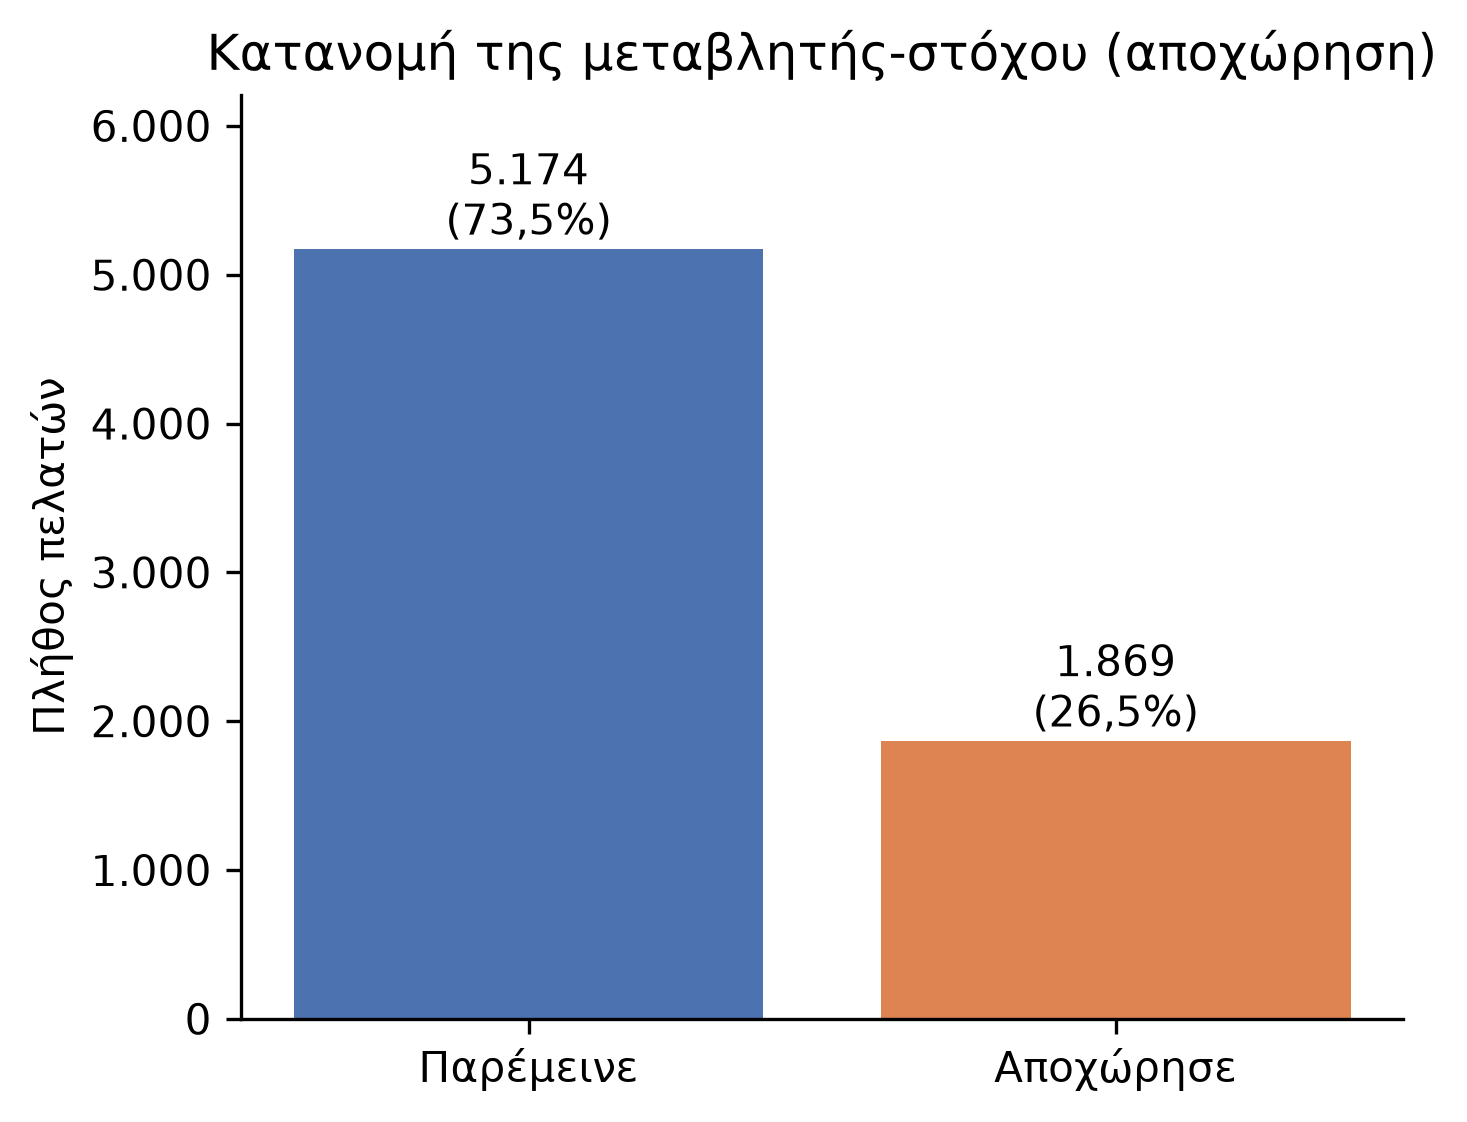

In [4]:
Image(filename=str(FIGURES / "eda_target.png"), width=850)

### 1.2 Κατανομές

In [5]:
pd.read_csv(TABLES / "numeric_summary.csv")

,Μεταβλητή,Ομάδα,Πλήθος,Μέσος όρος,Τυπική απόκλιση,Ελάχιστο,25%,Διάμεσος,75%,Μέγιστο,Ασυμμετρία
0,tenure,Παρέμεινε,5174,37.570,24.114,0.00,15.00,38.000,61.00,72.00,-0.032
1,tenure,Αποχώρησε,1869,17.979,19.531,1.00,2.00,10.000,29.00,72.00,1.149
2,MonthlyCharges,Παρέμεινε,5174,61.265,31.093,18.25,25.10,64.425,88.40,118.75,-0.025
3,MonthlyCharges,Αποχώρησε,1869,74.441,24.666,18.85,56.15,79.650,94.20,118.35,-0.729
4,TotalCharges,Παρέμεινε,5174,2549.911,2329.954,0.00,572.90,1679.525,4262.85,8672.45,0.808
5,TotalCharges,Αποχώρησε,1869,1531.796,1890.823,18.85,134.50,703.550,2331.30,8684.80,1.511


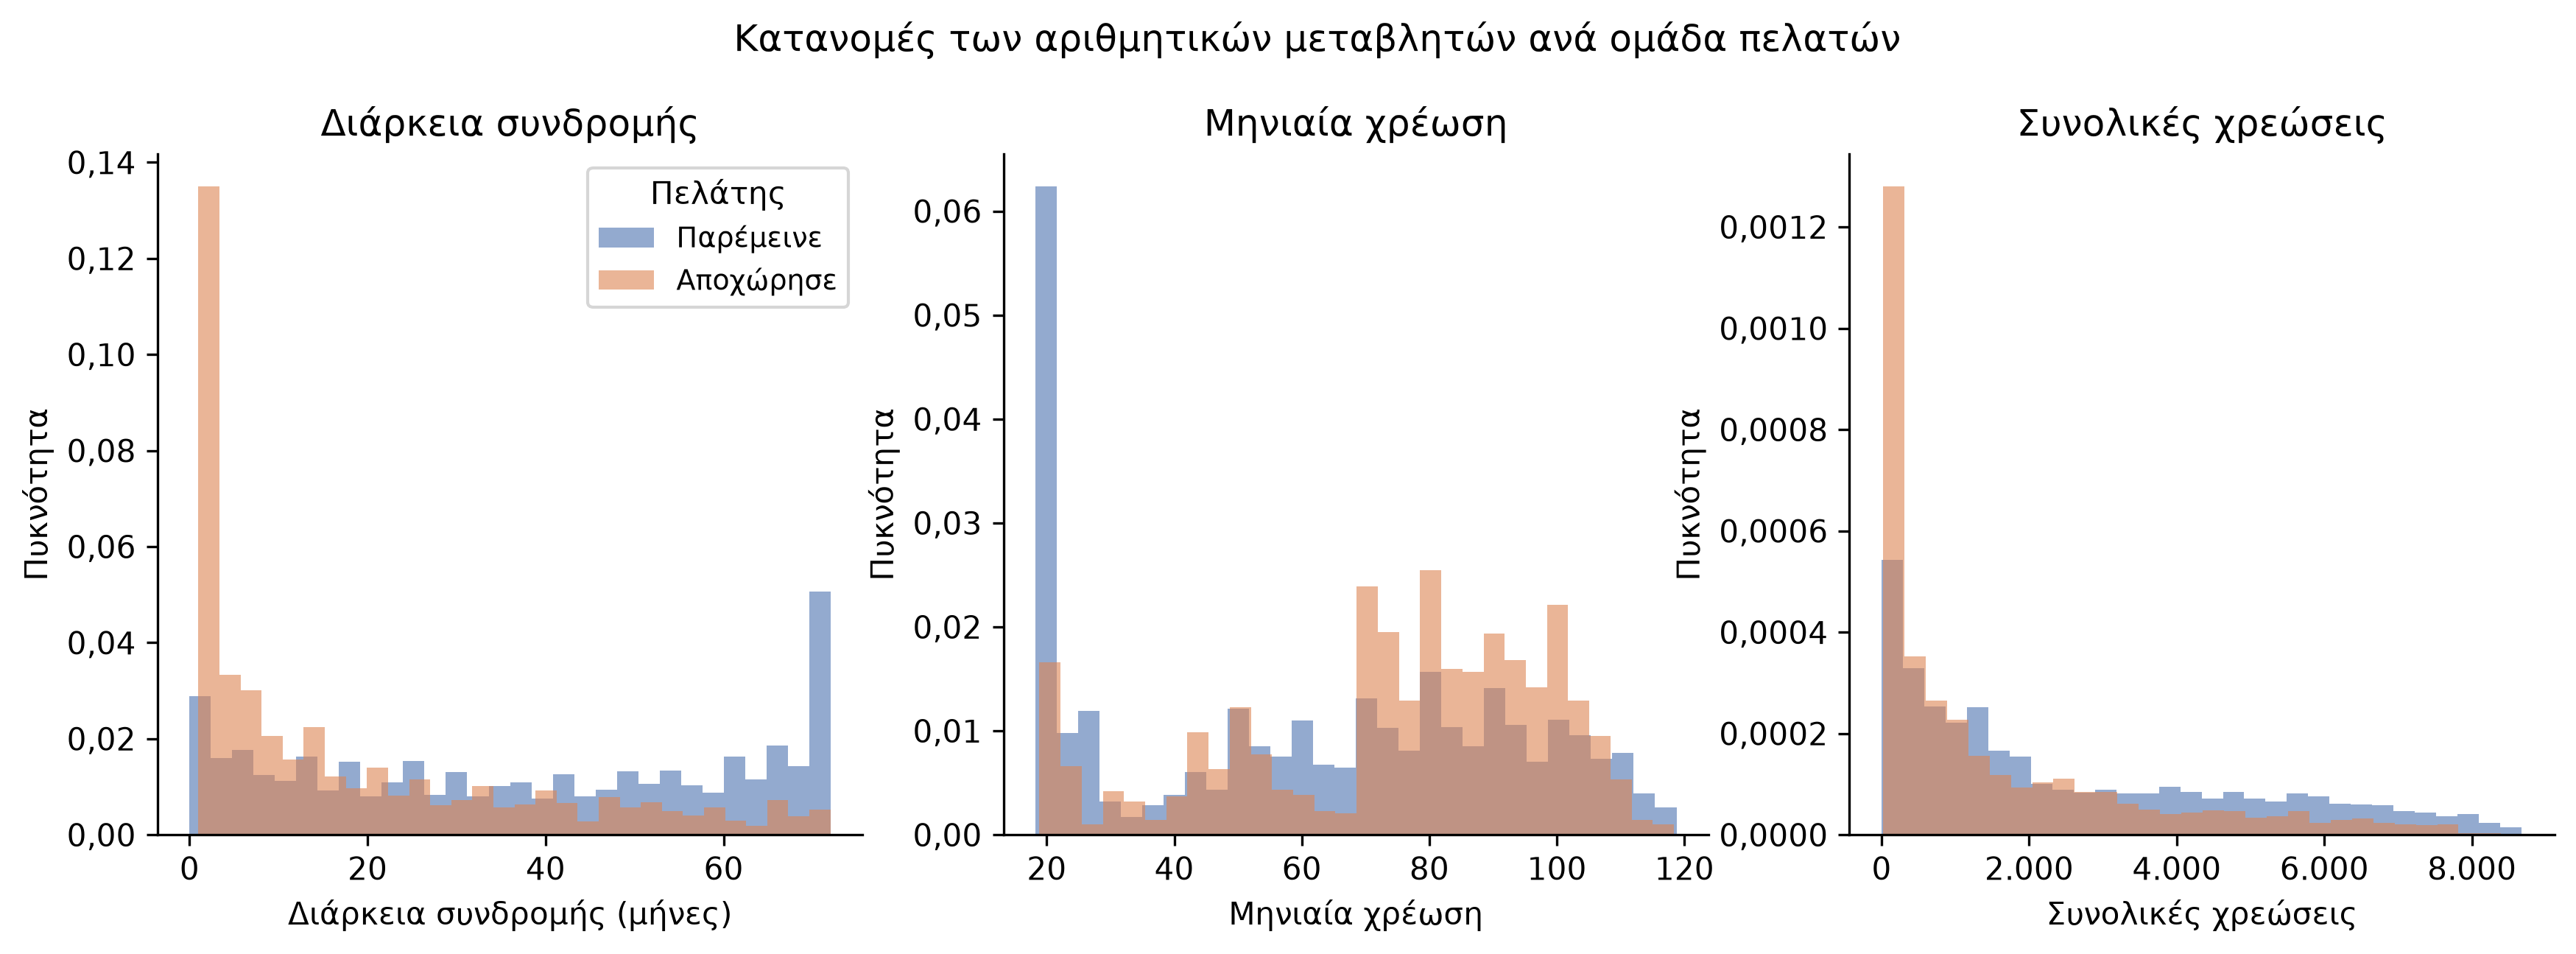

In [6]:
Image(filename=str(FIGURES / "eda_numeric.png"), width=850)

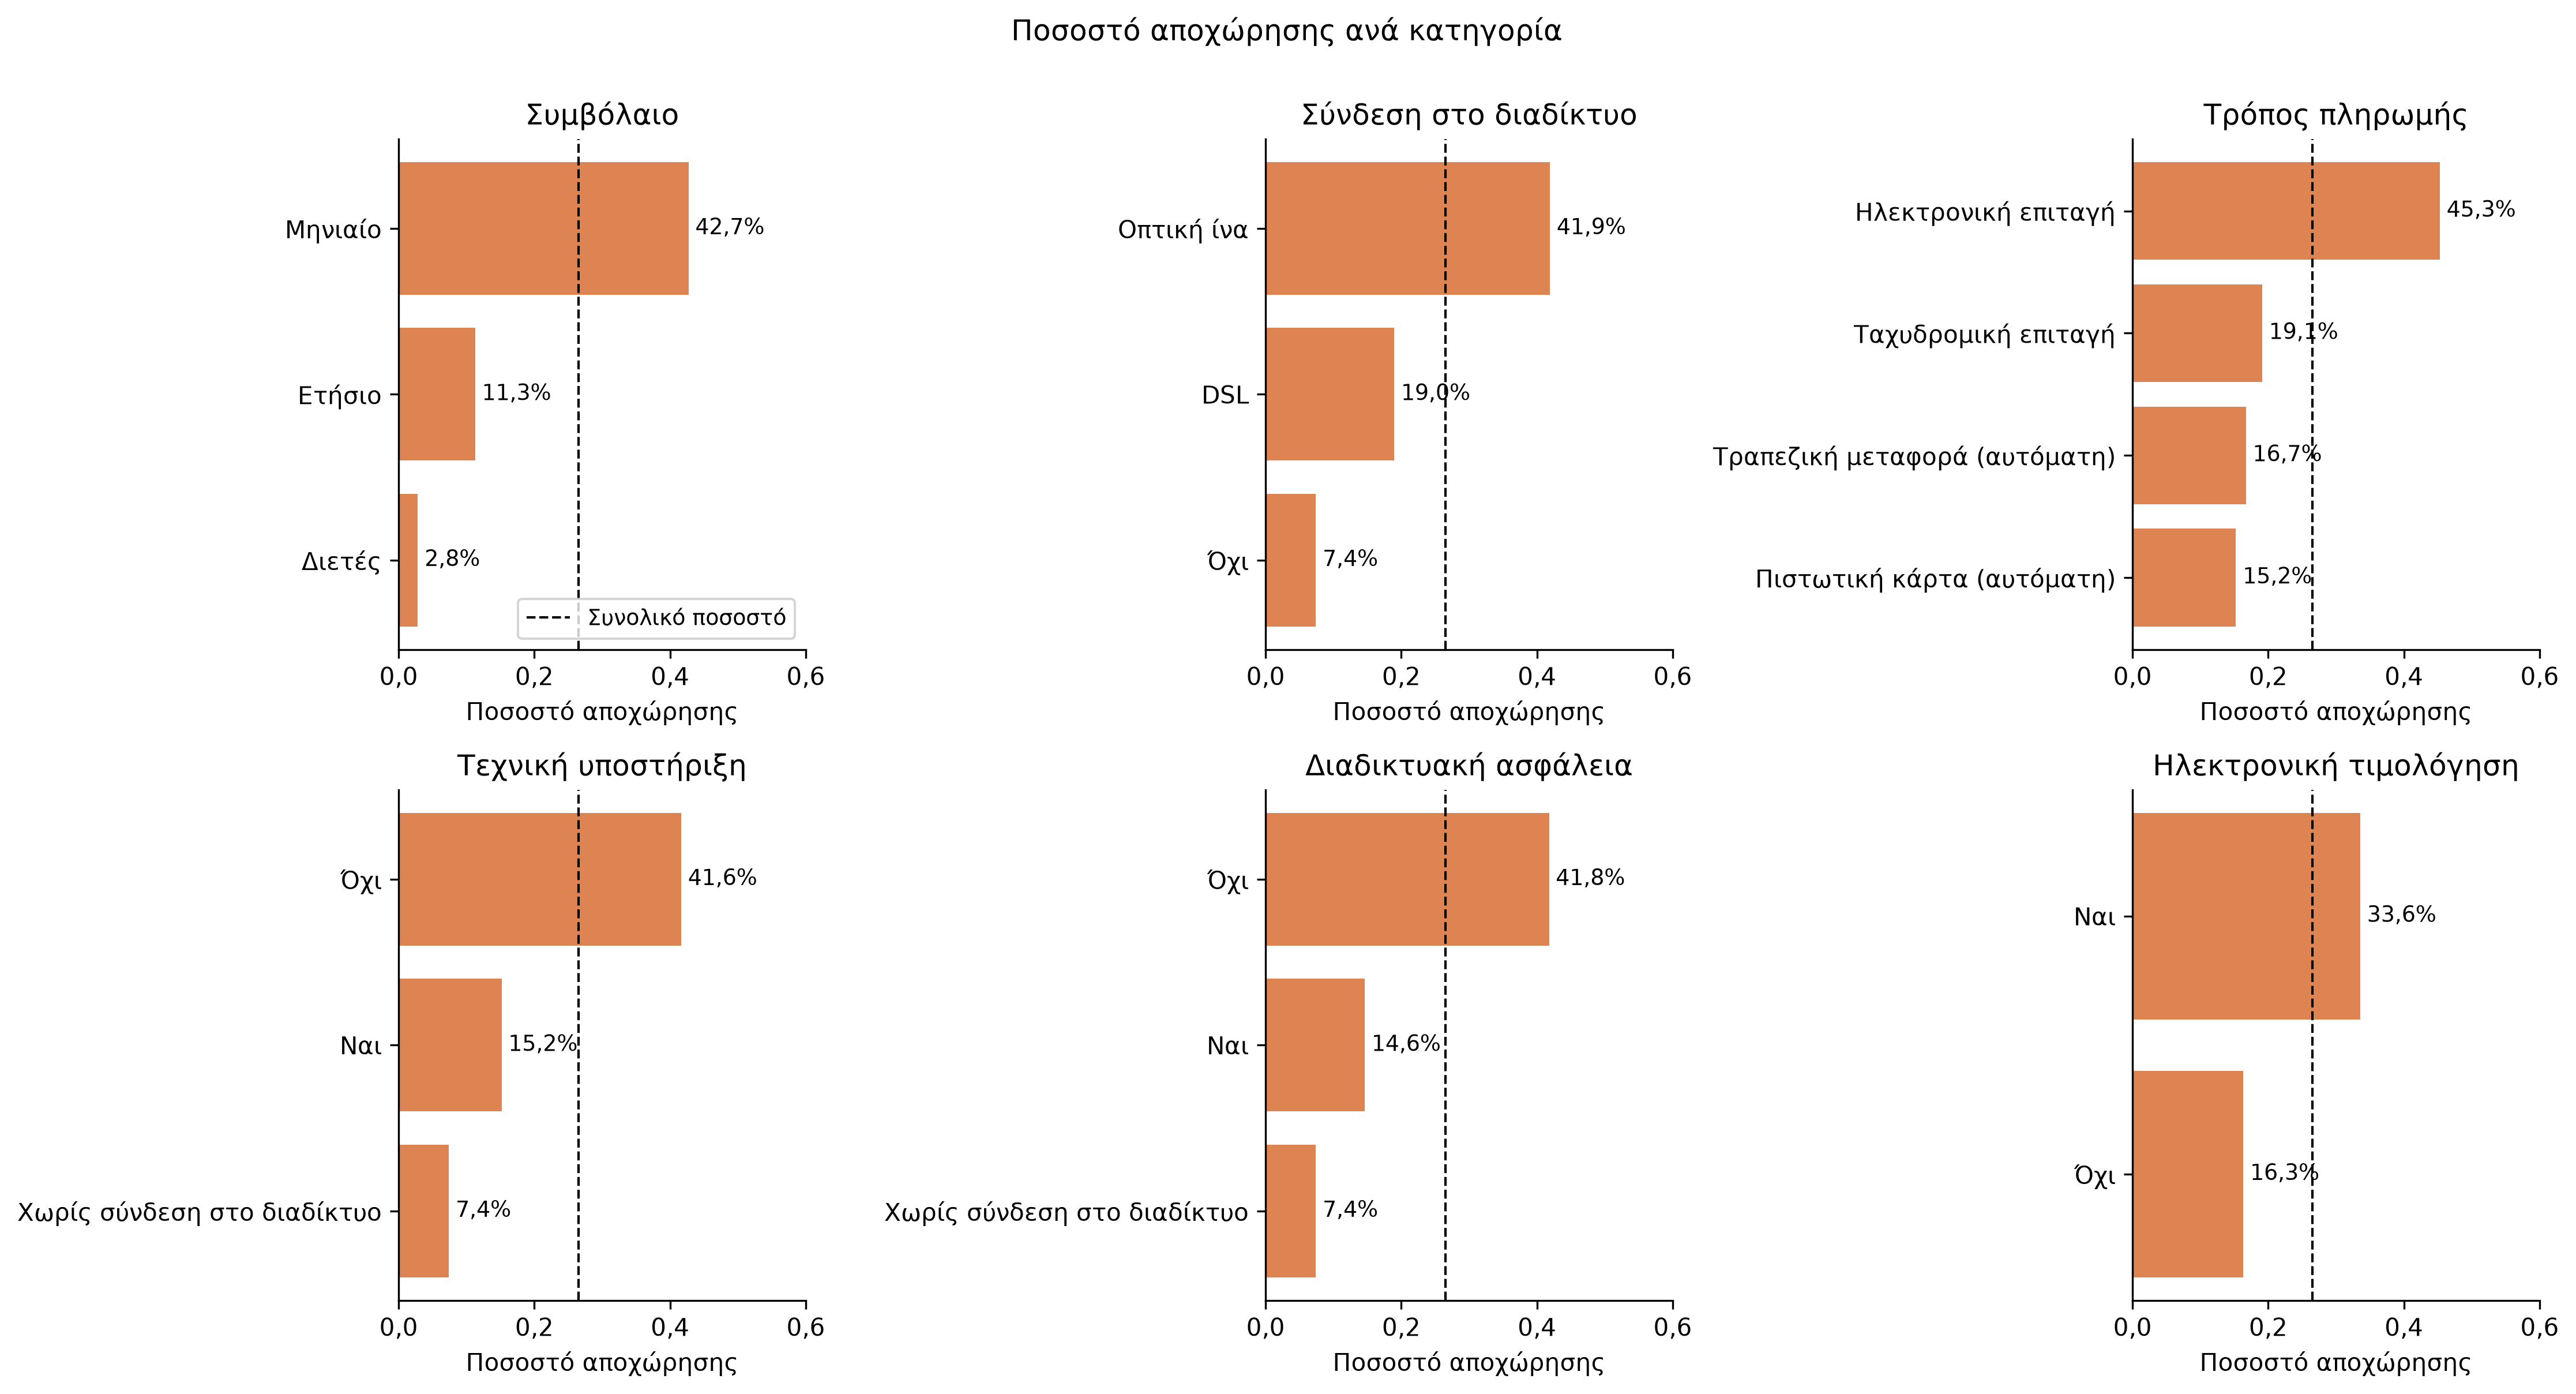

In [7]:
Image(filename=str(FIGURES / "eda_churn_by_category.png"), width=850)

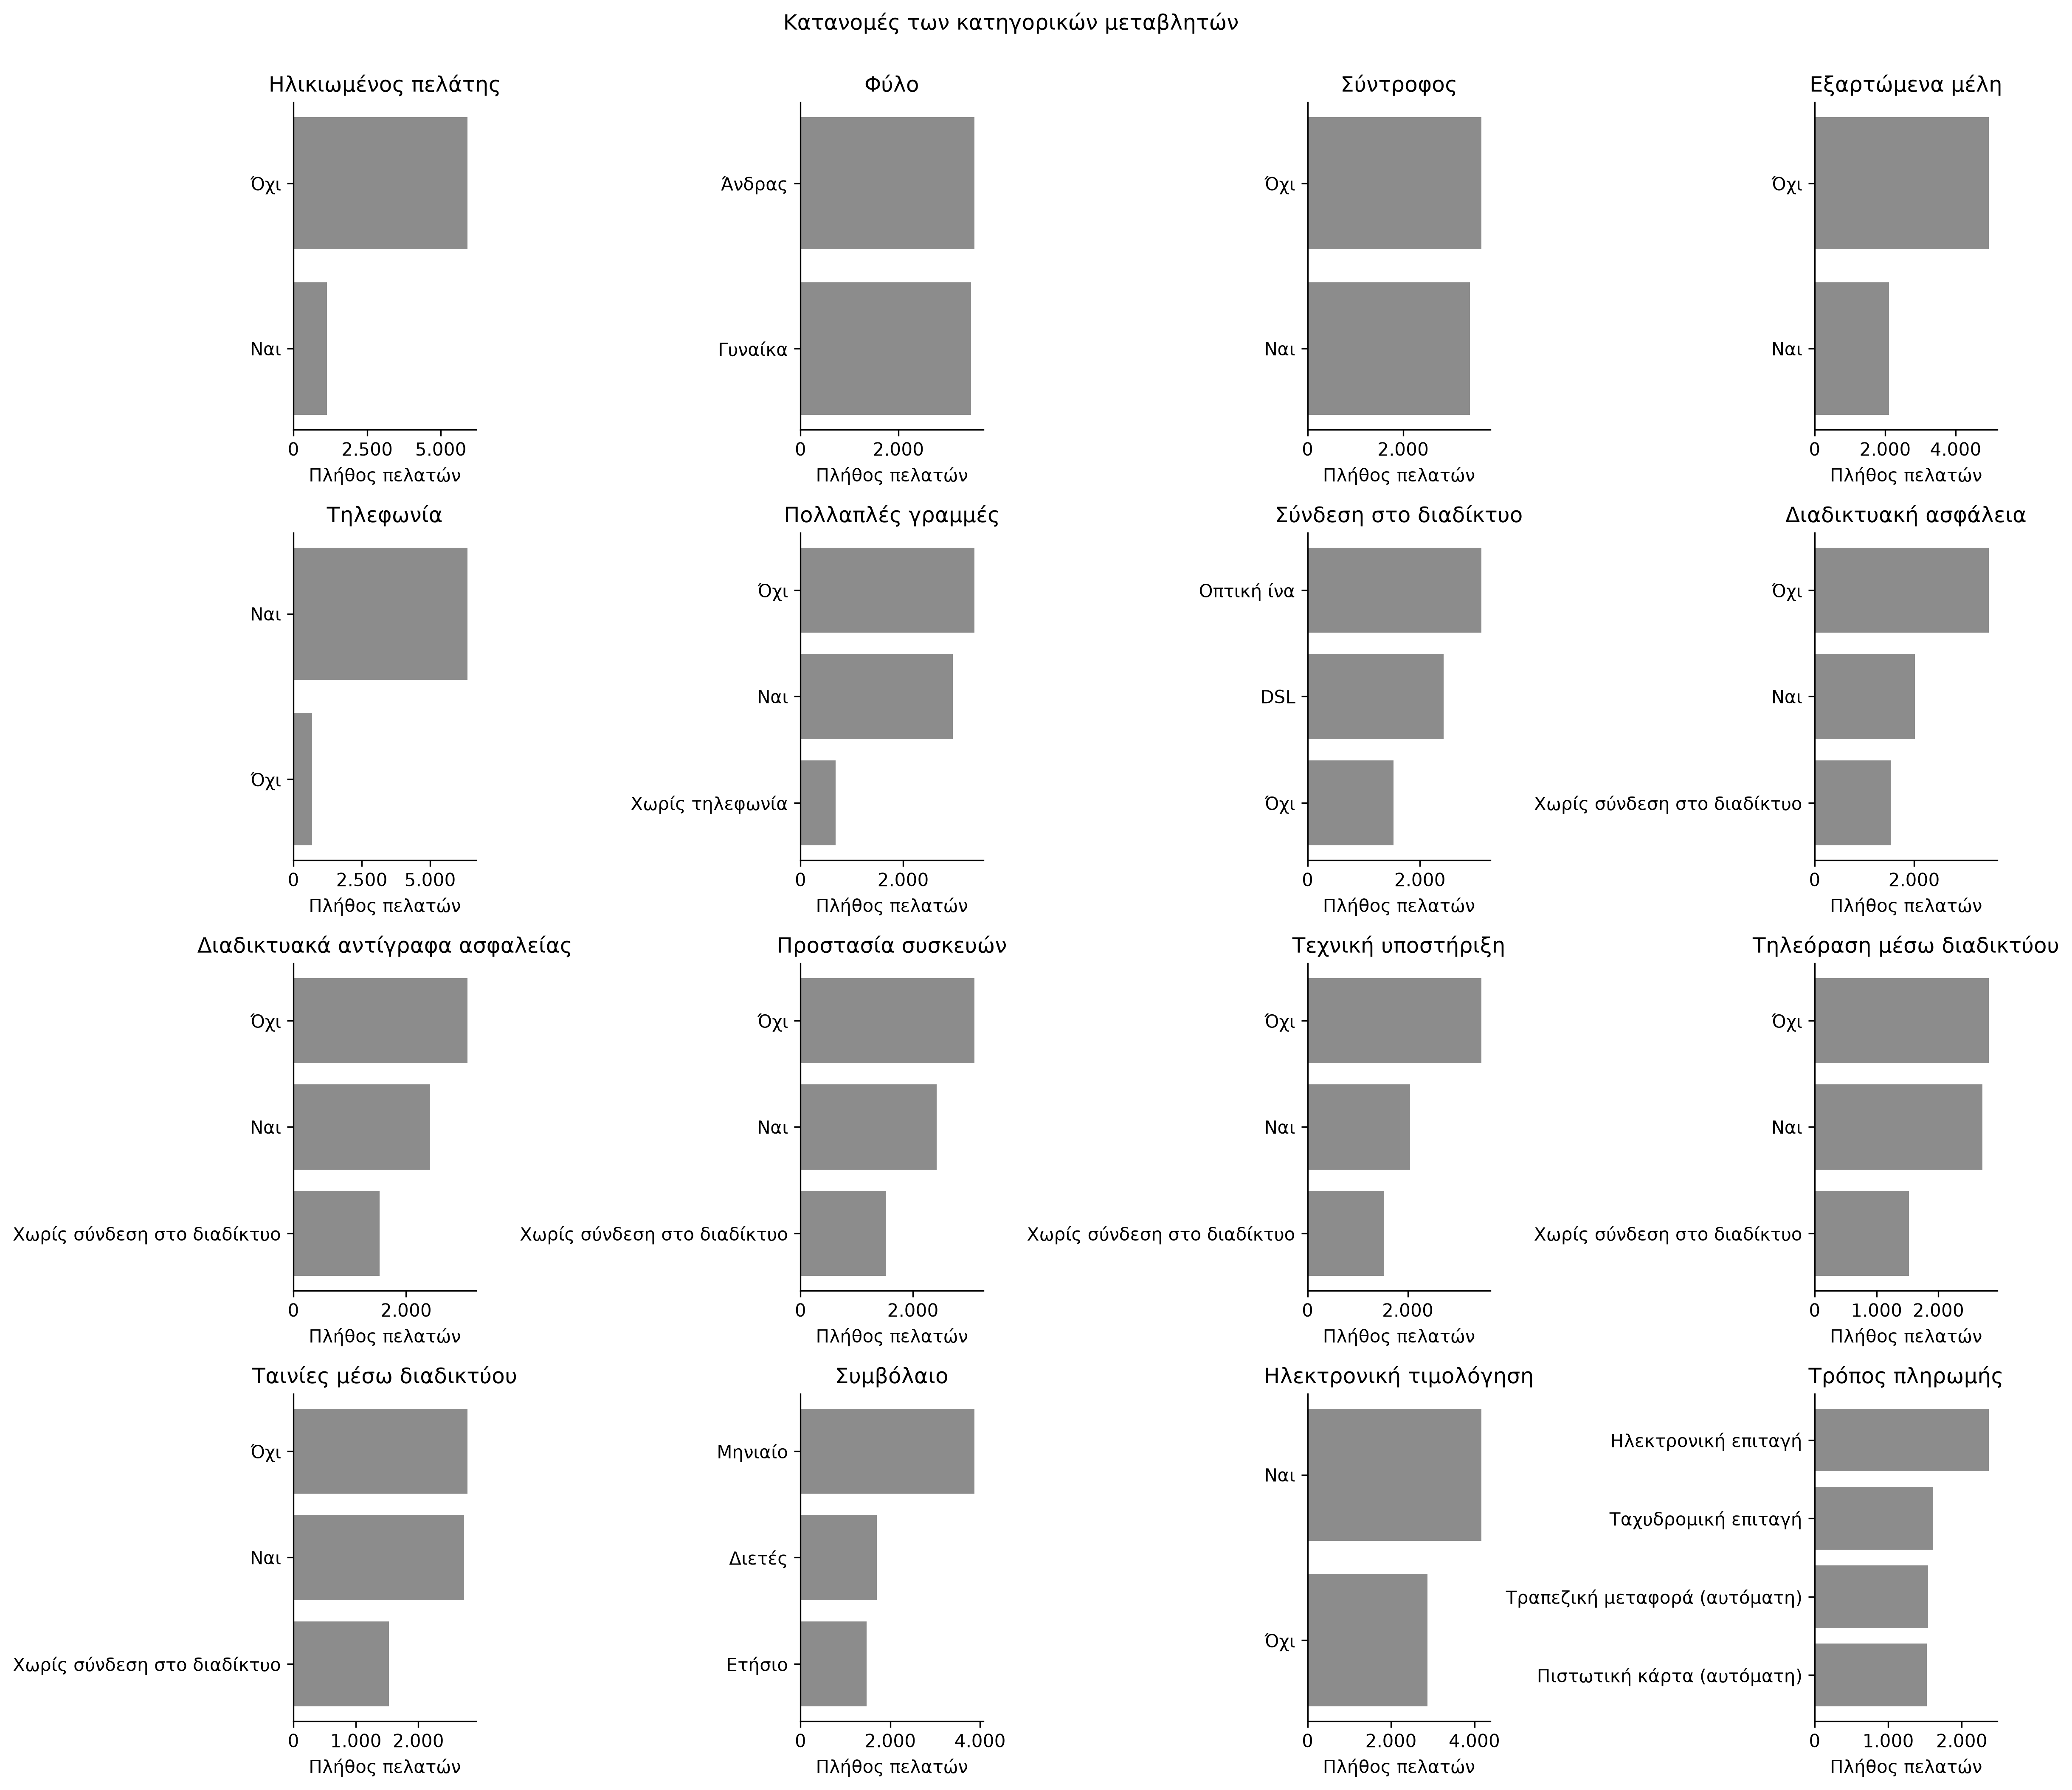

In [8]:
Image(filename=str(FIGURES / "eda_categorical_distributions.png"), width=850)

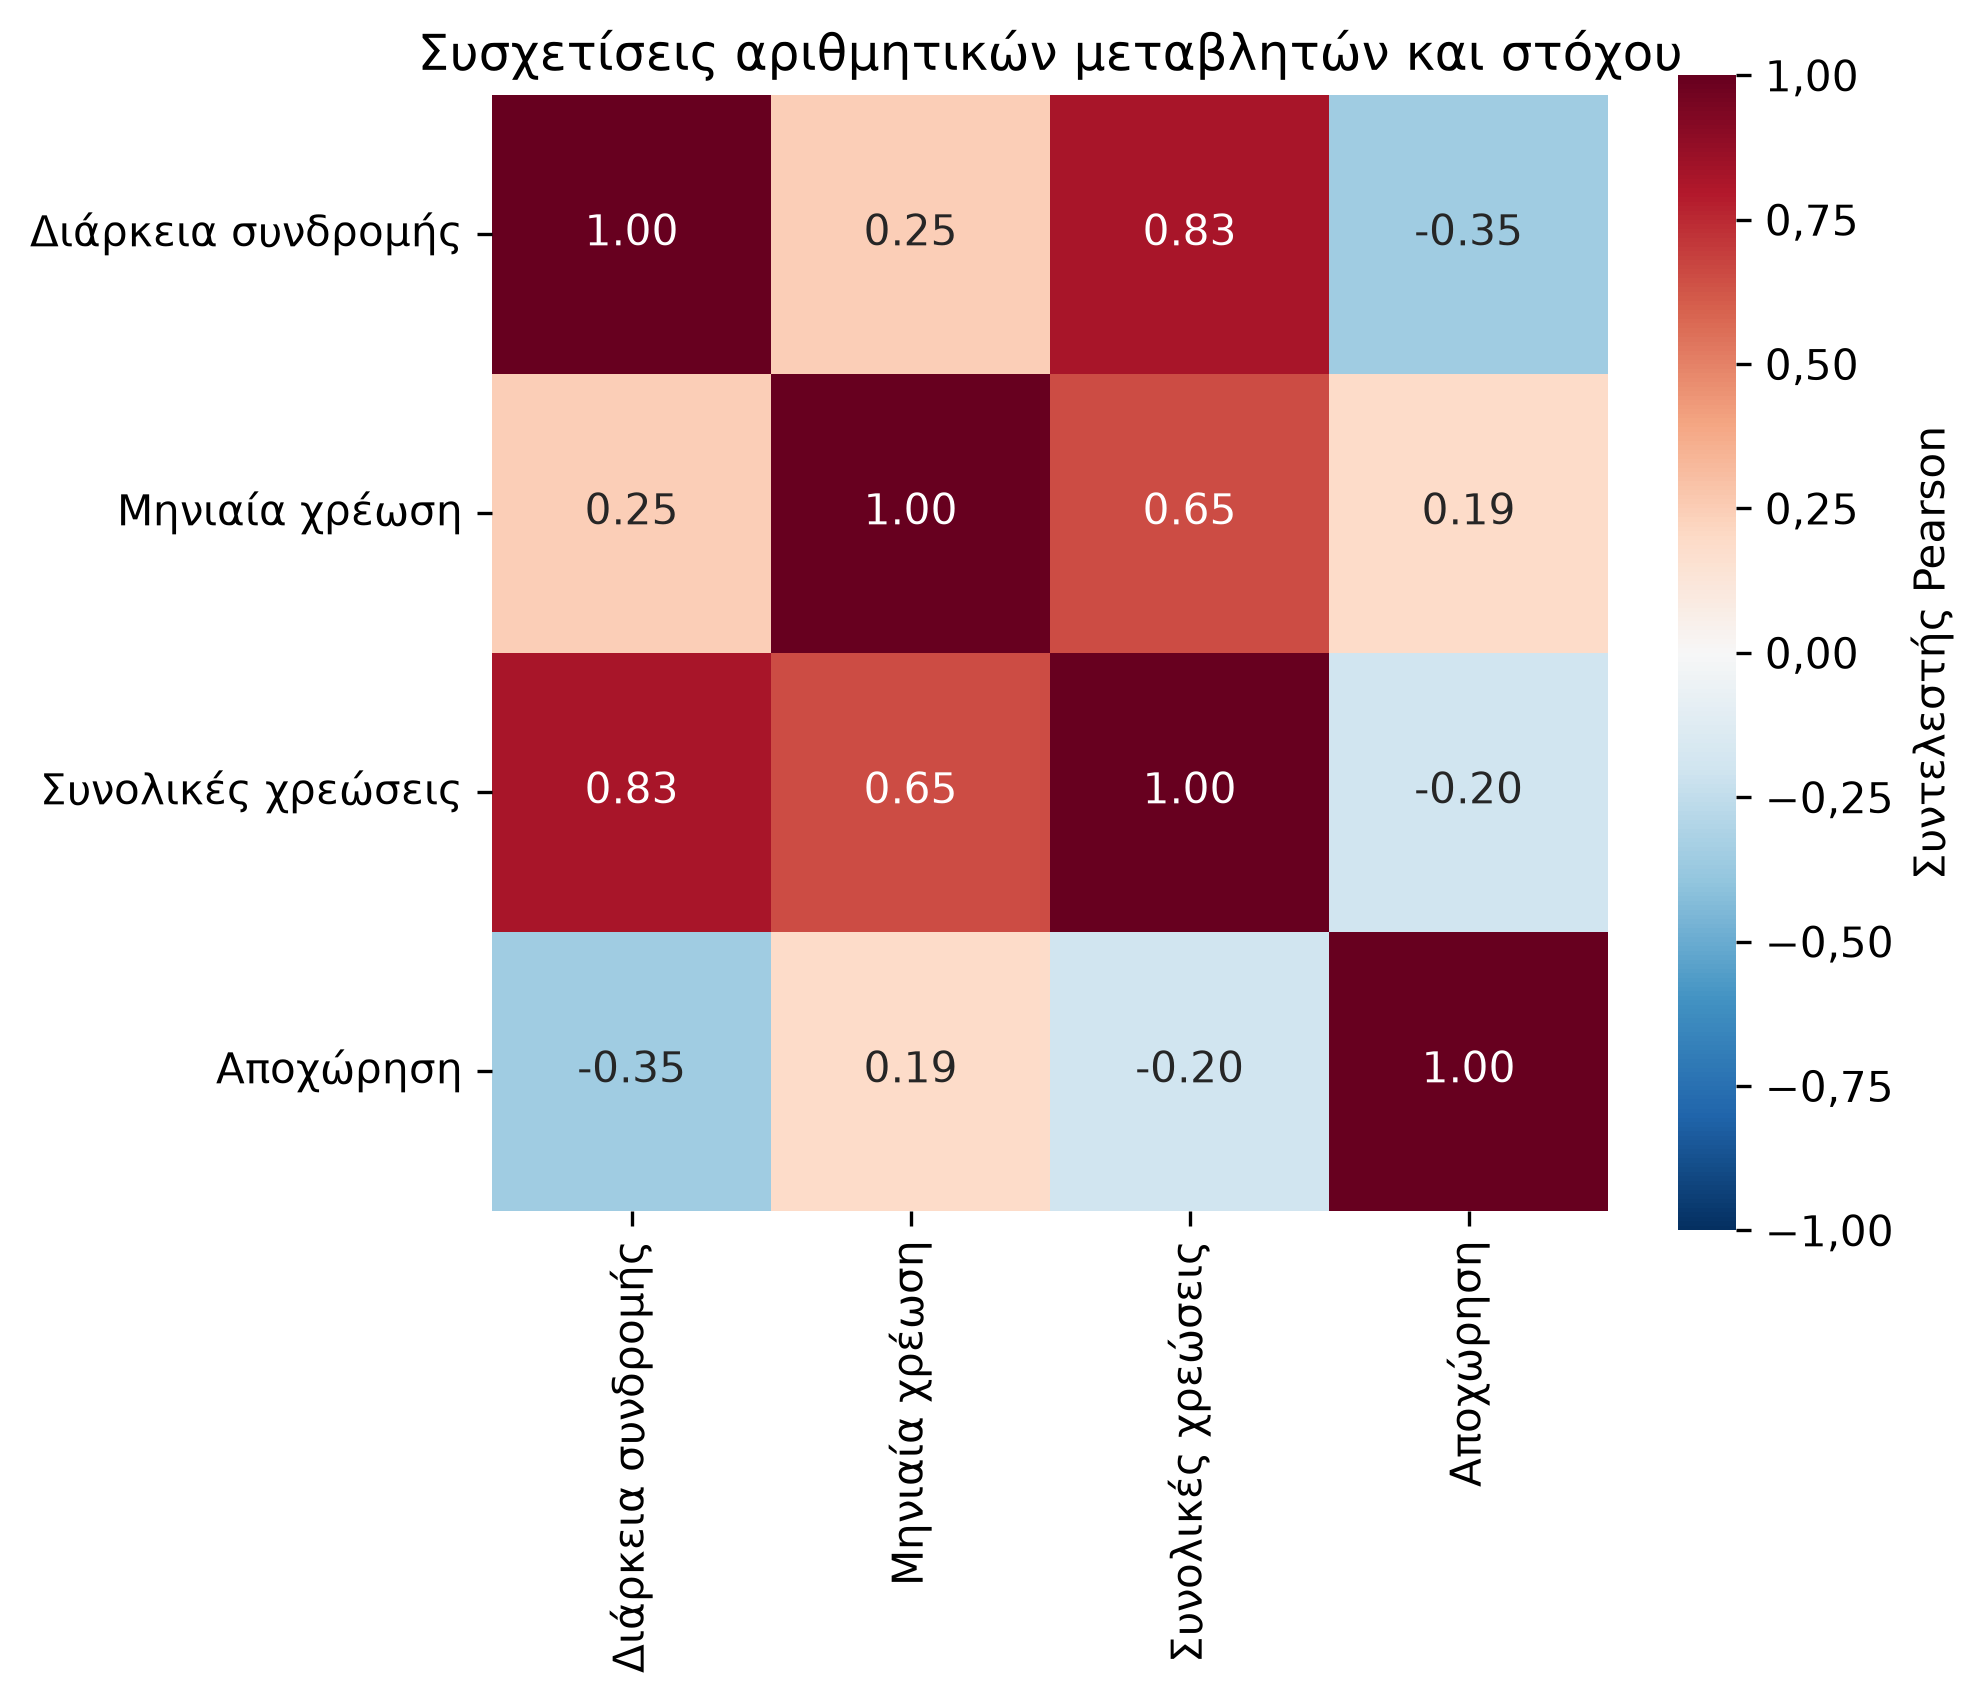

In [9]:
Image(filename=str(FIGURES / "eda_correlation.png"), width=850)

### 1.3 Σχέσεις ανάμεσα στα χαρακτηριστικά
Οι υπηρεσίες εξηγούν σχεδόν πλήρως τη μηνιαία χρέωση, το `TotalCharges` είναι σχεδόν ακριβώς
`tenure × MonthlyCharges`, και οι κατηγορίες «No internet/phone service» επαναλαμβάνουν πληροφορία
άλλων στηλών.

In [10]:
pd.read_csv(TABLES / "feature_redundancy.csv")

,Έλεγχος,Αποτέλεσμα,Γραμμές,Τιμή
0,OnlineSecurity = 'No internet service' ⇔ Inter...,True,1526,NaN
1,OnlineBackup = 'No internet service' ⇔ Interne...,True,1526,NaN
2,DeviceProtection = 'No internet service' ⇔ Int...,True,1526,NaN
3,TechSupport = 'No internet service' ⇔ Internet...,True,1526,NaN
4,StreamingTV = 'No internet service' ⇔ Internet...,True,1526,NaN
5,StreamingMovies = 'No internet service' ⇔ Inte...,True,1526,NaN
6,MultipleLines = 'No phone service' ⇔ PhoneServ...,True,682,NaN
7,"R² του MonthlyCharges από τις 9 υπηρεσίες ≥ 0,99",True,7043,0.9988
8,Συσχέτιση TotalCharges με tenure × MonthlyChar...,True,7043,0.9996


In [11]:
pd.read_csv(TABLES / "feature_associations_categorical.csv").head(15)

,feature_a,feature_b,cramers_v
0,PhoneService,MultipleLines,1.0000
1,StreamingTV,StreamingMovies,0.7710
2,DeviceProtection,StreamingMovies,0.7360
3,DeviceProtection,StreamingTV,0.7337
4,OnlineSecurity,TechSupport,0.7331
5,DeviceProtection,TechSupport,0.7265
6,InternetService,OnlineSecurity,0.7245
7,InternetService,TechSupport,0.7229
8,OnlineBackup,TechSupport,0.7198
9,OnlineBackup,DeviceProtection,0.7191


In [12]:
pd.read_csv(TABLES / "feature_associations_cat_num.csv").head(10)

,categorical,numeric,eta
0,InternetService,MonthlyCharges,0.9059
1,StreamingTV,MonthlyCharges,0.8372
2,StreamingMovies,MonthlyCharges,0.8354
3,DeviceProtection,MonthlyCharges,0.7913
4,OnlineBackup,MonthlyCharges,0.7807
5,TechSupport,MonthlyCharges,0.7684
6,OnlineSecurity,MonthlyCharges,0.7649
7,Contract,tenure,0.6759
8,DeviceProtection,TotalCharges,0.5558
9,StreamingMovies,TotalCharges,0.5483


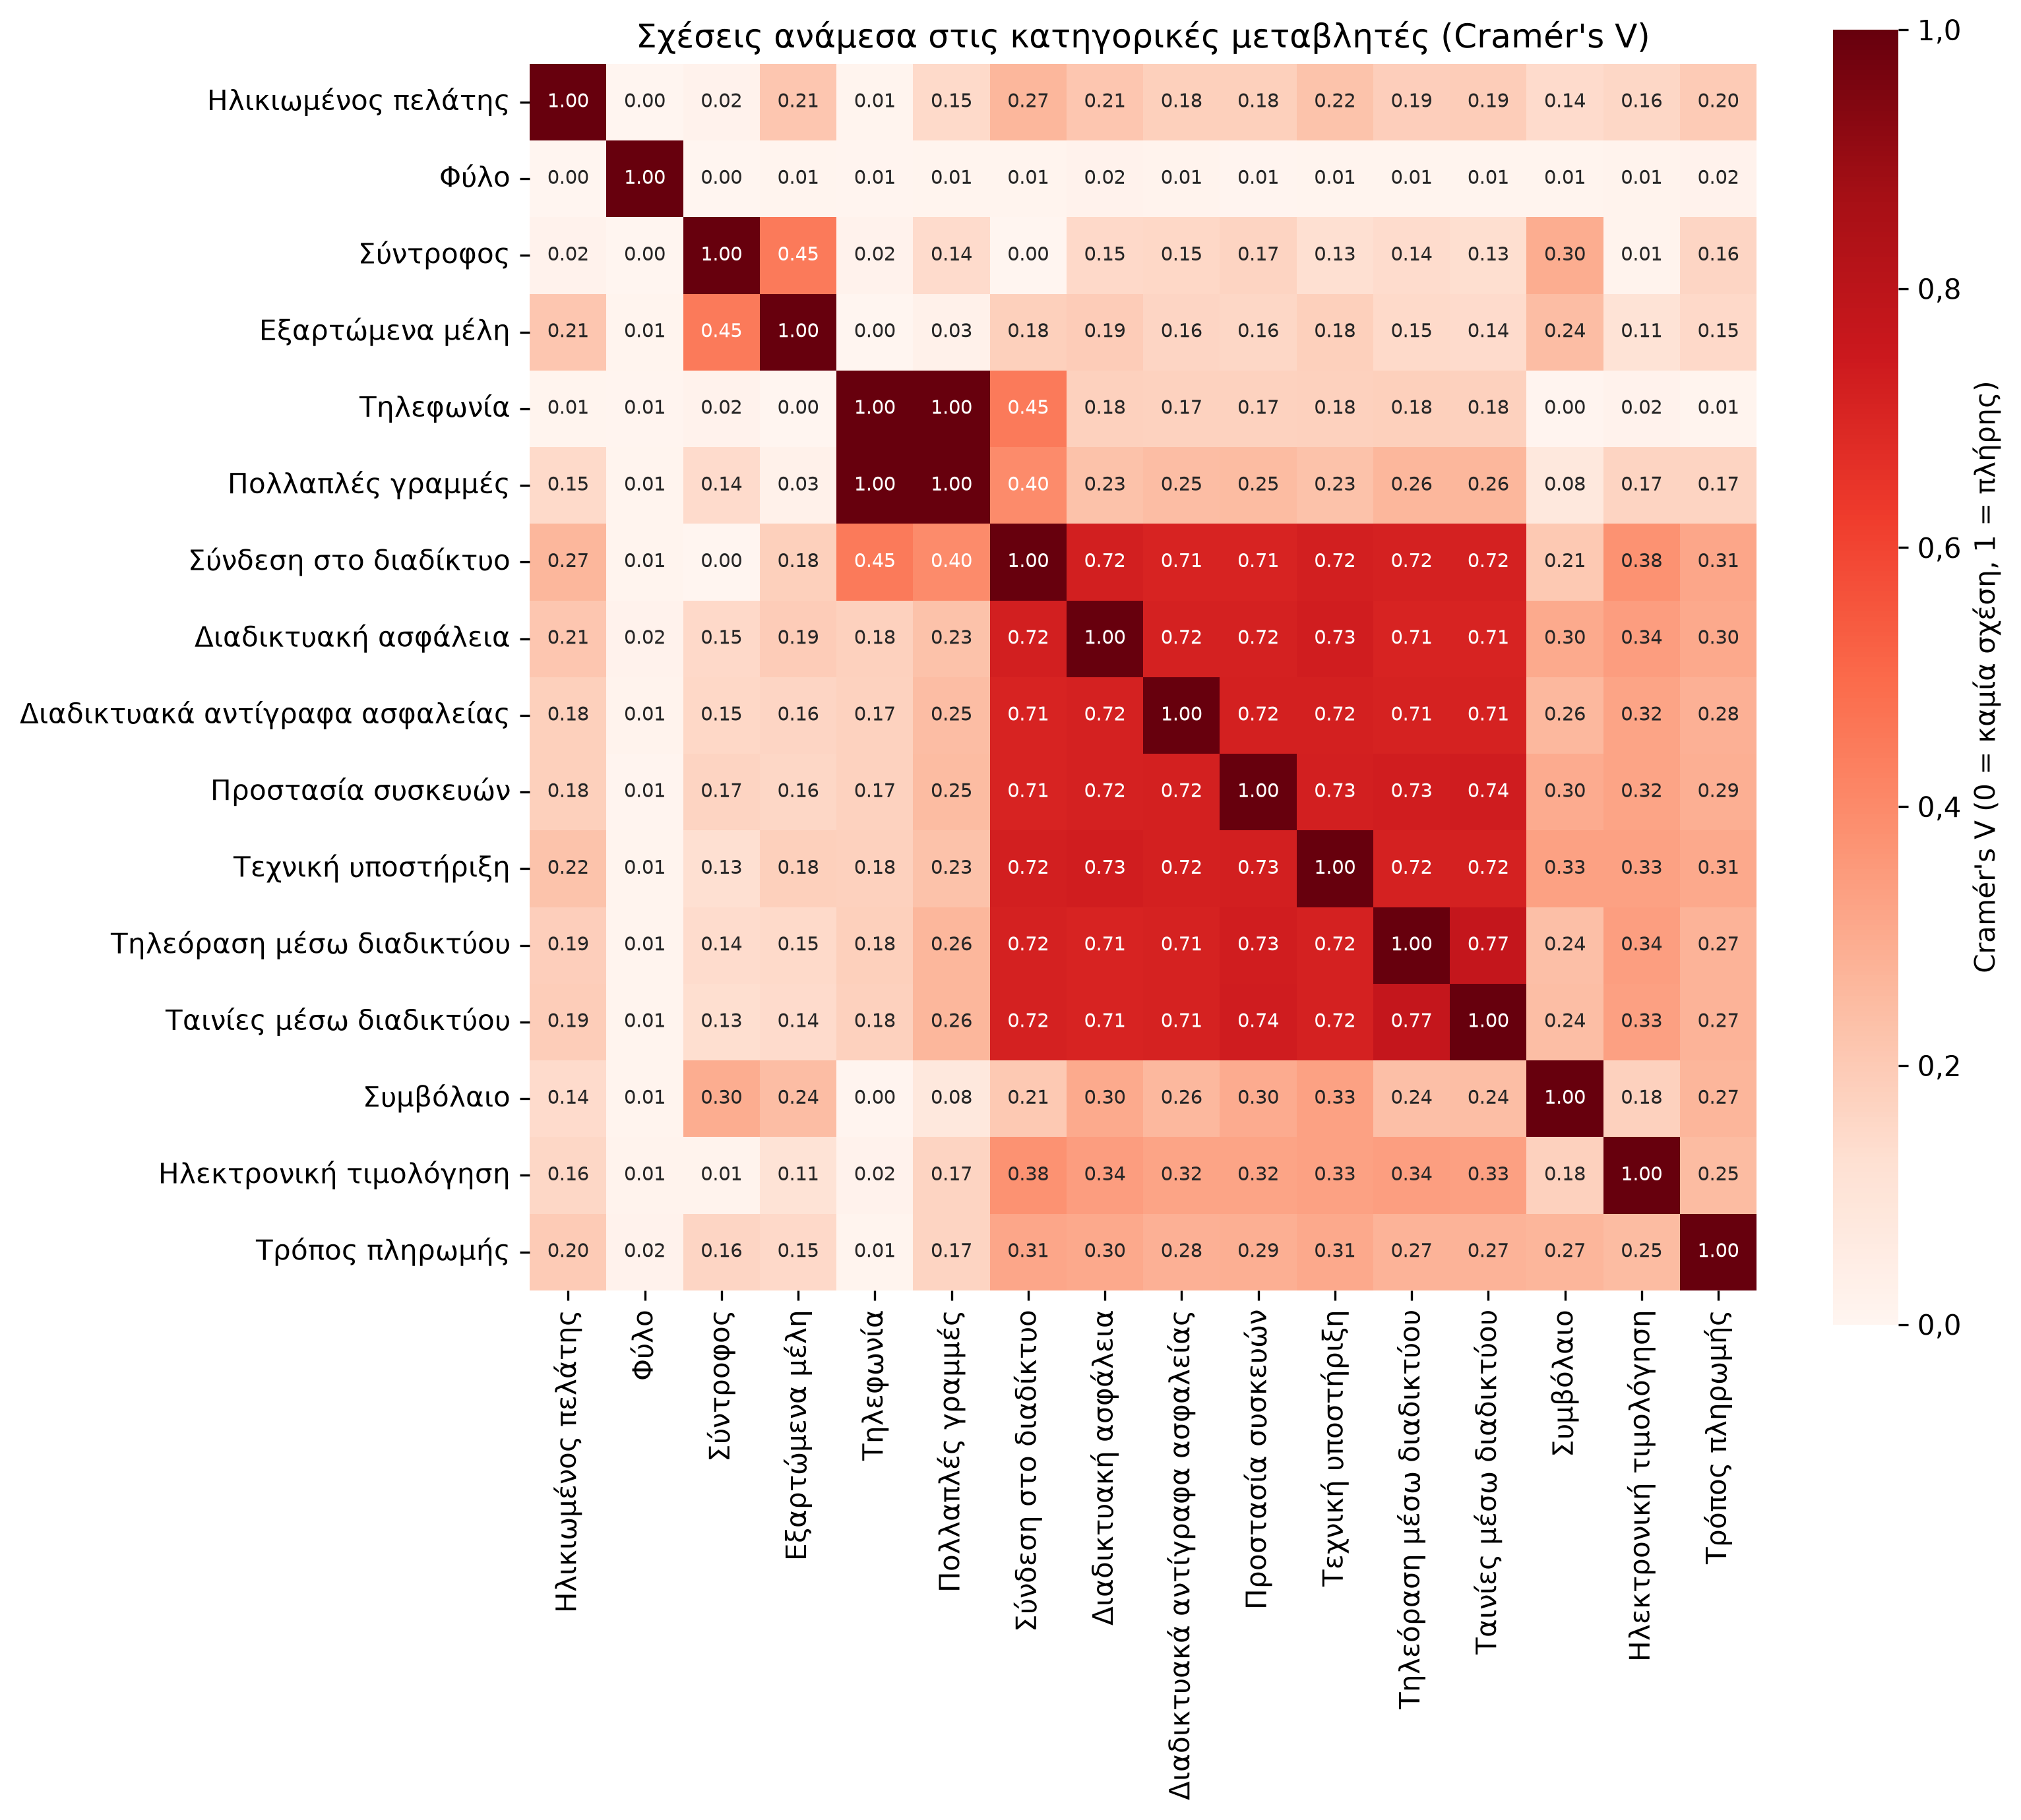

In [13]:
Image(filename=str(FIGURES / "eda_cramers_v.png"), width=850)

### 1.4 Καθαρισμός και προεπεξεργασία
- **Κενές τιμές:** οι 11 κενές τιμές του `TotalCharges` ανήκουν σε πελάτες με `tenure = 0` και γίνονται 0.
- **Κωδικοποίηση:** one-hot για τις κατηγορικές (οι δυαδικές γίνονται μία στήλη 0/1). Η μεταχείριση των
  περιττών κατηγοριών και του `TotalCharges` αποφασίστηκε με πείραμα (1.5).
- **Κανονικοποίηση:** `StandardScaler` στις 3 αριθμητικές, εκπαιδευμένος μόνο στο train.
- **Διαχωρισμός:** 70/15/15 με διαστρωμάτωση.

In [14]:
from src.data import load_splits
from src.preprocessing import build_preprocessor, feature_names
X_train, y_train, X_val, y_val, X_test, y_test = load_splits()
prep = build_preprocessor().fit(X_train)
print(f"train {len(X_train)}, val {len(X_val)}, test {len(X_test)} — χαρακτηριστικά μετά την προεπεξεργασία: {len(feature_names(prep))}")
print("Ποσοστό αποχώρησης ανά σύνολο:", [round(y.mean(), 4) for y in (y_train, y_val, y_test)])

train 4929, val 1057, test 1057 — χαρακτηριστικά μετά την προεπεξεργασία: 25
Ποσοστό αποχώρησης ανά σύνολο: [np.float64(0.2654), np.float64(0.2658), np.float64(0.2649)]


### 1.5 Πείραμα κωδικοποίησης
Τρεις παραλλαγές (πλήρης, συγχώνευση περιττών κατηγοριών, και χωρίς `TotalCharges`), με Logistic Regression και
XGBoost (5-fold CV στο train).

In [15]:
pd.read_csv(TABLES / "encoding_comparison.csv")

,model,variant,Παραλλαγή,n_features,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std,f1_mean,f1_std,recall_mean,recall_std
0,logreg,full,Πλήρης,40,0.8473,0.0128,0.6683,0.0259,0.6334,0.0227,0.8081,0.0151
1,logreg,merged,Συγχώνευση,26,0.8472,0.0129,0.6683,0.0261,0.6333,0.0222,0.8081,0.0153
2,logreg,merged_no_total,Συγχώνευση χωρίς συνολικές χρεώσεις,25,0.8457,0.0127,0.6654,0.0244,0.6322,0.0202,0.8035,0.0127
3,xgb,full,Πλήρης,40,0.8287,0.0124,0.6328,0.0226,0.6006,0.0198,0.6560,0.0276
4,xgb,merged,Συγχώνευση,26,0.8279,0.0123,0.6333,0.0201,0.5995,0.0187,0.6491,0.0268
5,xgb,merged_no_total,Συγχώνευση χωρίς συνολικές χρεώσεις,25,0.8284,0.0132,0.6331,0.0195,0.6063,0.0152,0.6644,0.0194


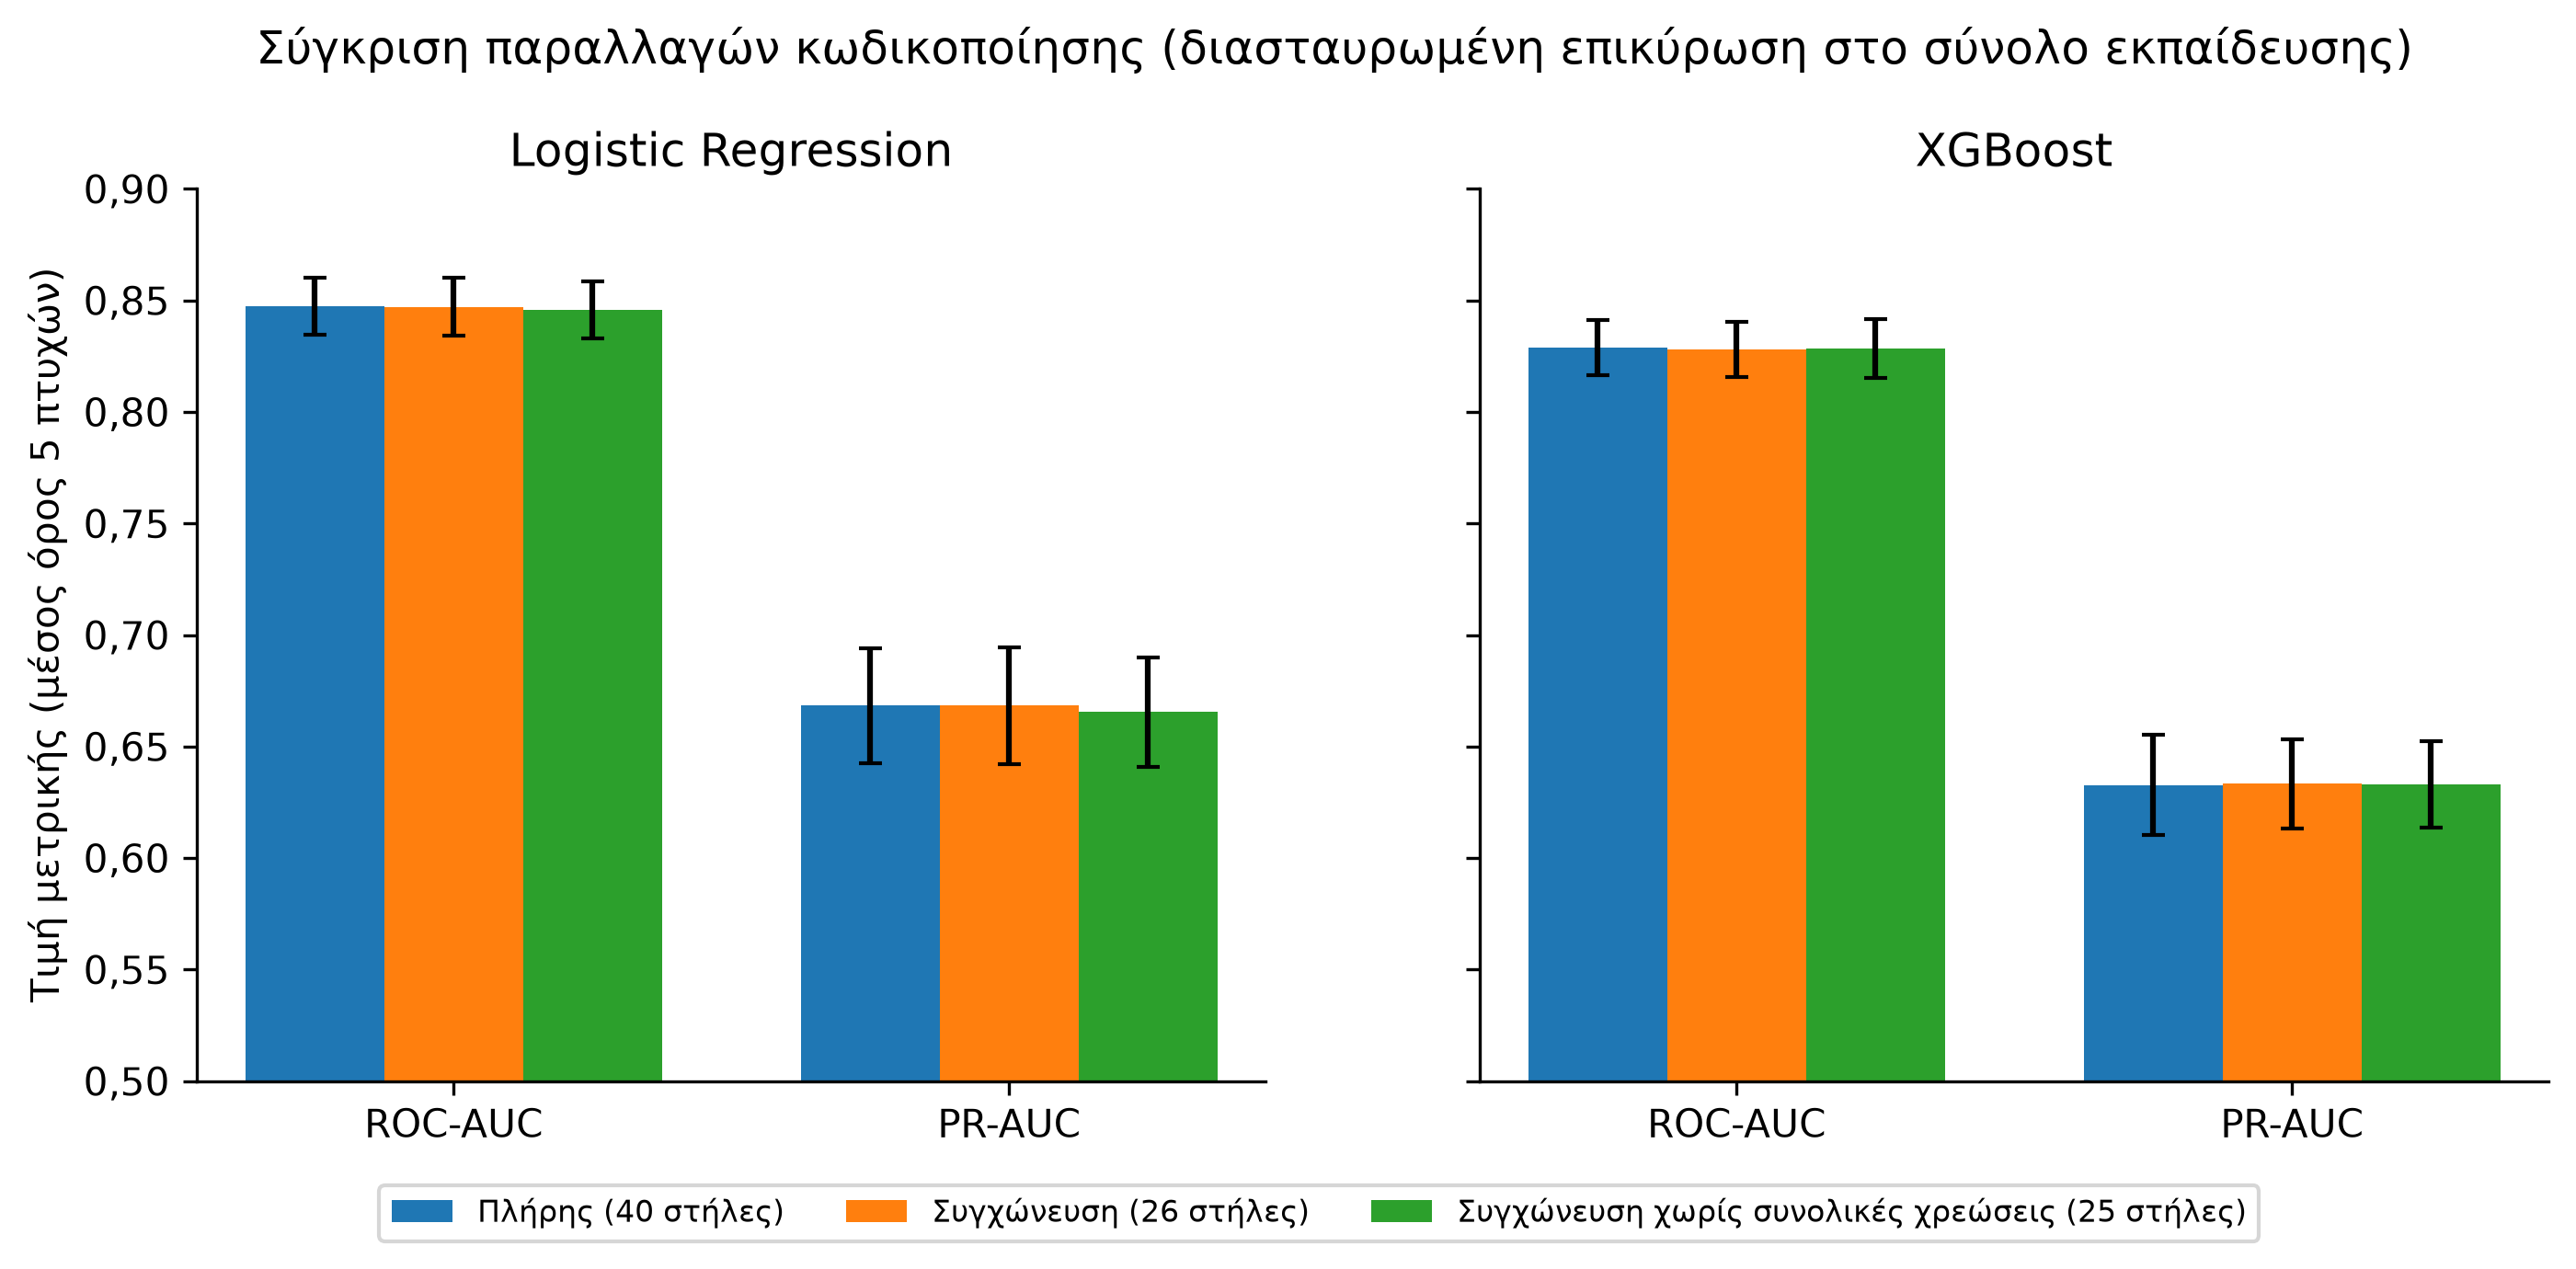

In [16]:
Image(filename=str(FIGURES / "encoding_comparison.png"), width=850)

In [17]:
json.loads((METRICS / "encoding_choice.json").read_text())

{'variant': 'merged_no_total',
 'n_features': 25,
 'best_by_pr_auc': 'full',
 'within_one_std': ['full', 'merged', 'merged_no_total'],
 'xgb_agrees': True,
 'reason': "Το μεγαλύτερο μέσο PR-AUC το έδωσε η «full» (0.6683), αλλά οι παραλλαγές ['full', 'merged', 'merged_no_total'] απέχουν λιγότερο από μία τυπική απόκλιση (0.0259). Επιλέχθηκε αυτή με τα λιγότερα χαρακτηριστικά. Το XGBoost συμφωνεί (διαφορά μέσα σε μία τυπική απόκλιση)."}

### 1.6 Ανισορροπία κλάσεων
Πρώτα ένα επιχείρημα από τα δεδομένα, χωρίς μοντέλα, και μετά ένα πείραμα με Logistic Regression
(5-fold CV στο train) για τις 4 μεθόδους.

In [18]:
json.loads((TABLES / "imbalance_facts.json").read_text())

{'train_rows': 4929,
 'train_churn': 1308,
 'train_stay': 3621,
 'ratio_stay_per_churn': 2.768,
 'undersample_discards': 2313,
 'undersample_discards_share': 0.4693,
 'smote_nc_creates': 2313,
 'input_columns_categorical': 16,
 'input_columns_numeric': 3,
 'encoded_columns_binary': 23}

In [19]:
pd.read_csv(TABLES / "imbalance_comparison.csv")

,method,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std,f1_mean,f1_std,recall_mean,recall_std
0,none,0.8461,0.0131,0.6663,0.0238,0.6026,0.0113,0.5528,0.0121
1,class_weight,0.8457,0.0127,0.6654,0.0244,0.6322,0.0202,0.8035,0.0127
2,smote_nc,0.8367,0.0118,0.6458,0.0226,0.6302,0.0182,0.7347,0.0207
3,undersample,0.8440,0.0118,0.6599,0.0256,0.6297,0.0168,0.7974,0.0100


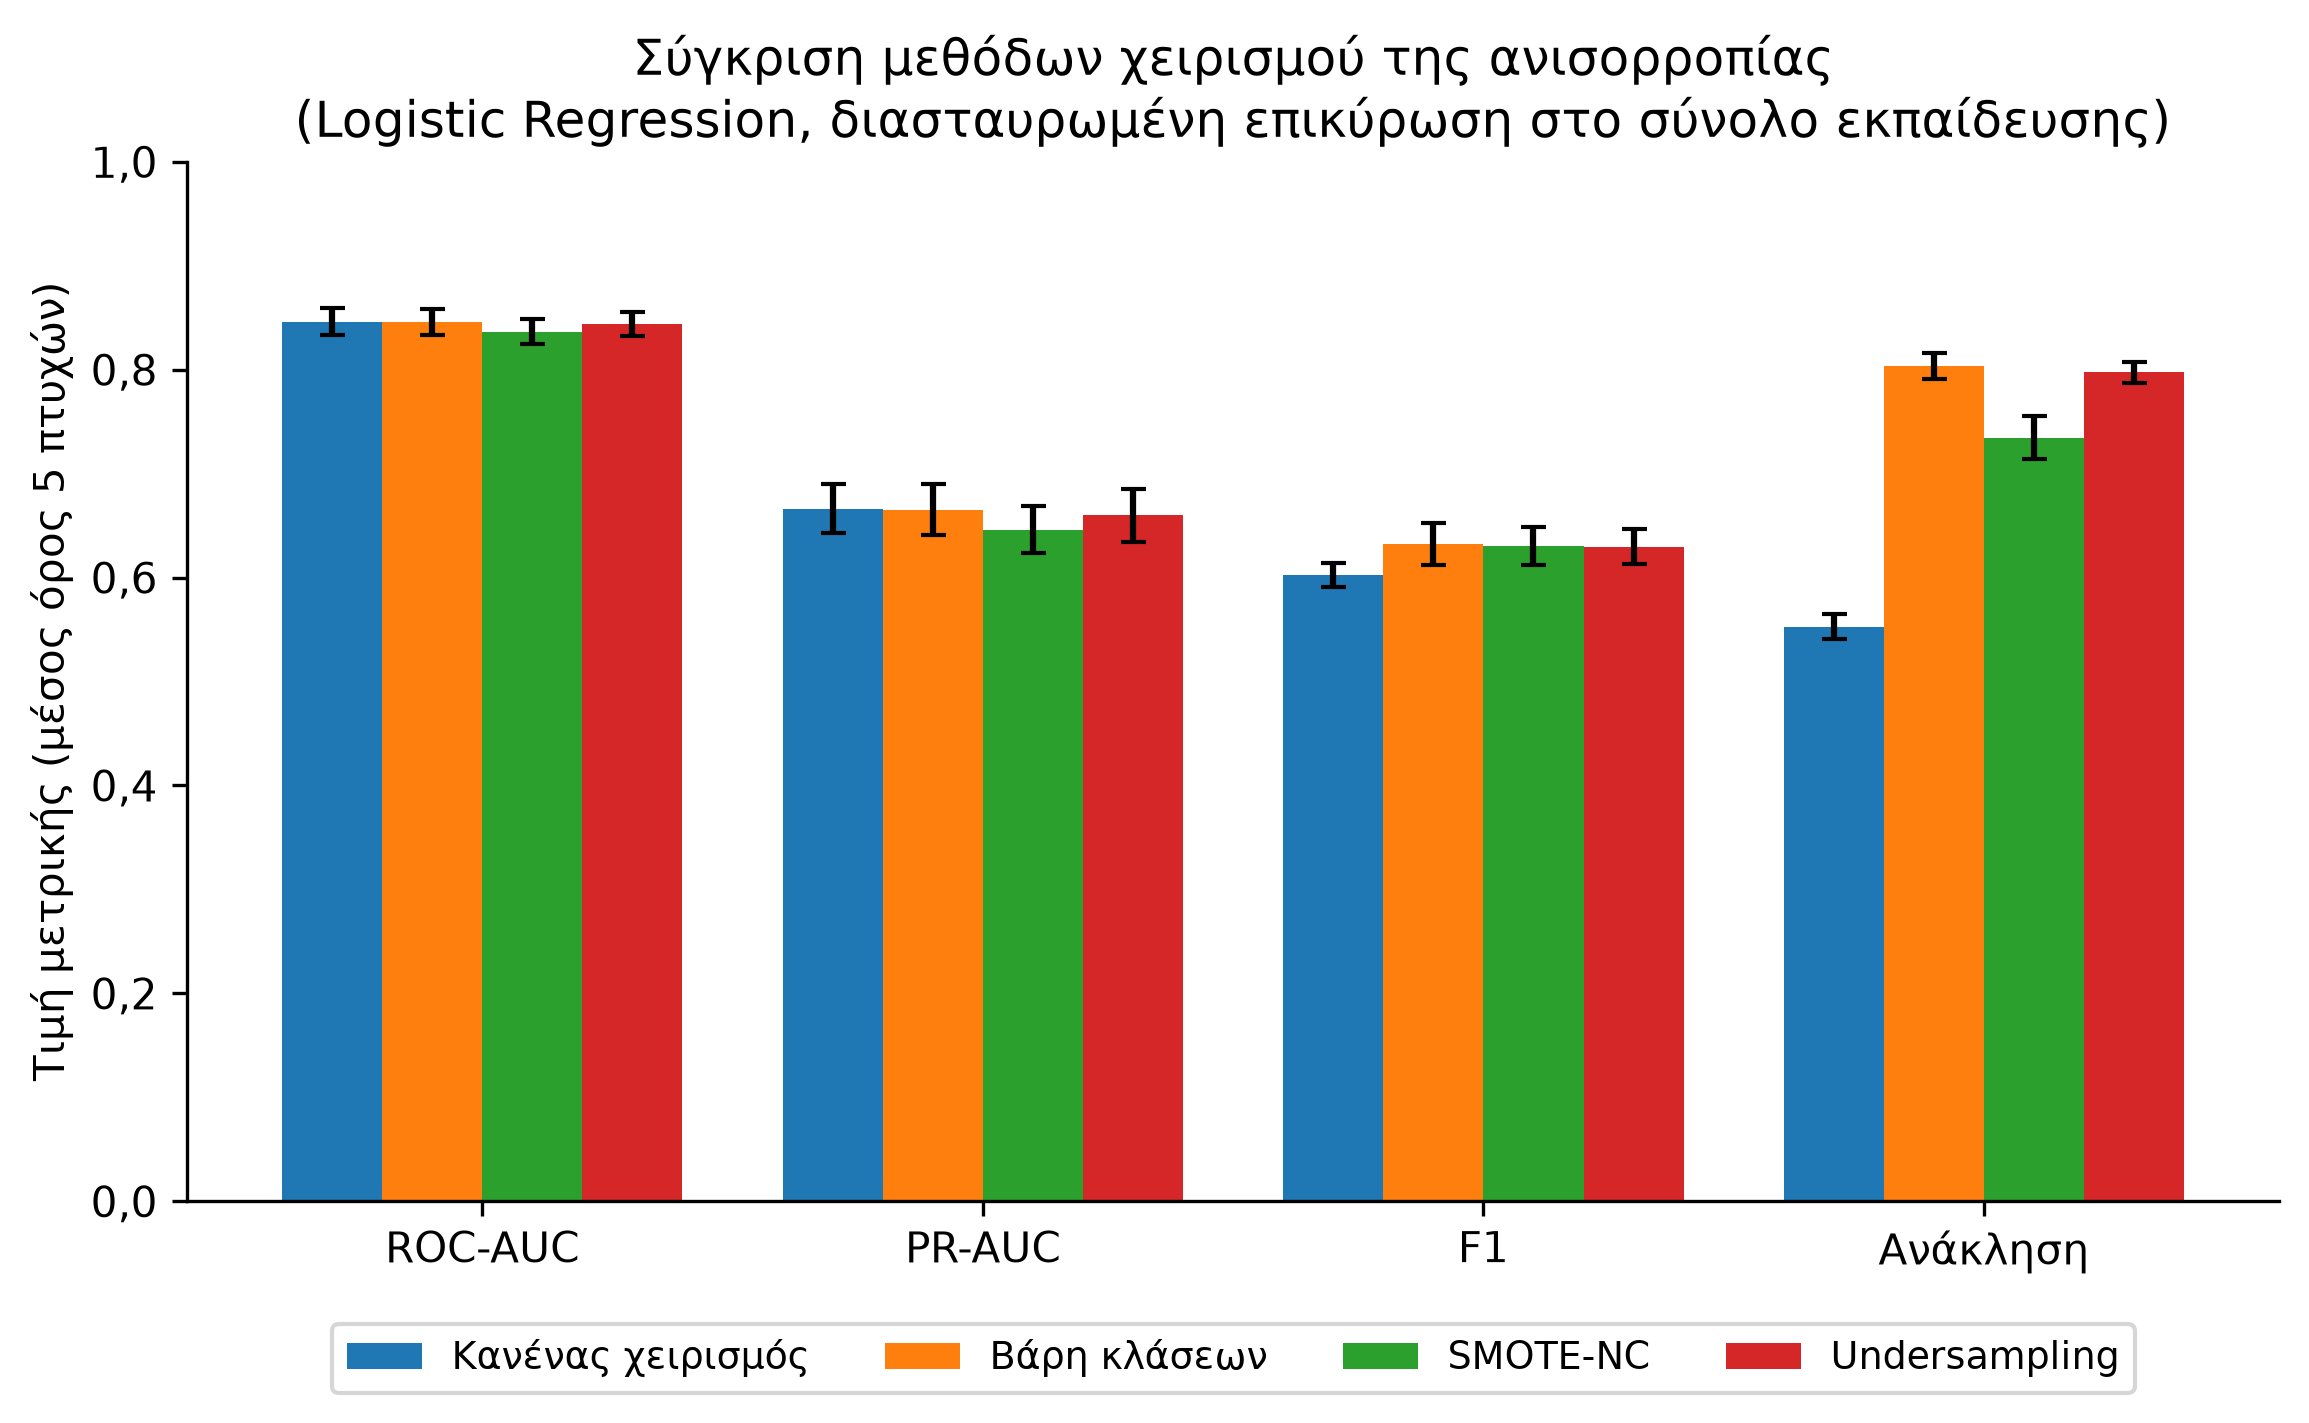

In [20]:
Image(filename=str(FIGURES / "imbalance_comparison.png"), width=850)

In [21]:
json.loads((METRICS / "imbalance_choice.json").read_text())

{'method': 'class_weight',
 'best_by_pr_auc': 'none',
 'within_one_std': ['none', 'class_weight', 'smote_nc', 'undersample'],
 'reason': "Το μεγαλύτερο μέσο PR-AUC το έδωσε η «none» (0.6663), αλλά οι μέθοδοι ['none', 'class_weight', 'smote_nc', 'undersample'] απέχουν λιγότερο από μία τυπική απόκλιση (0.0238). Επιλέχθηκε η απλούστερη από αυτές."}

## 2. Baseline: Logistic Regression
Grid search στο C και στο είδος ποινής (L1/L2), threshold επιλεγμένο στο validation. Ο έλεγχος άκρων
(`grid_edge_report.csv`) δείχνει αν κάποια καλύτερη τιμή «ακούμπησε» στην άκρη του πλέγματος.

In [22]:
pd.read_csv(TABLES / "grid_edge_report.csv")

,model,parameter,value,edge,grid
0,rf,n_estimators,200.0,min,"[200, 400, 800]"
1,xgb,max_depth,2.0,min,"[2, 3, 4, 6]"
2,xgb,subsample,0.7,min,"[0.7, 0.85, 1.0]"
3,xgb,colsample_bytree,0.6,min,"[0.6, 0.8, 1.0]"
4,lgbm,num_leaves,4.0,min,"[4, 7, 15, 31, 63]"
5,lgbm,min_child_samples,10.0,min,"[10, 20, 50, 100, 200]"
6,nb,var_smoothing,0.1,max,"[1e-09, 1e-07, 1e-05, 0.001, 0.01, 0.1]"


Πόσο «επίπεδος» είναι ο χώρος αναζήτησης: όταν οι περισσότερες ρυθμίσεις απέχουν από την καλύτερη λιγότερο από μία
τυπική απόκλιση των folds, το ποια «κερδίζει» (και αν πέφτει στην άκρη του πλέγματος) είναι θέμα θορύβου.

In [23]:
pd.read_csv(TABLES / "search_flatness.csv")

,model,n_configs,best_cv_auc,fold_std,cv_auc_5th,cv_auc_10th,within_1_std,share_within_1_std
0,rf,30,0.8502,0.0118,0.8496,0.8480,26,0.8667
1,xgb,40,0.8513,0.0124,0.8499,0.8494,32,0.8000
2,lgbm,40,0.8508,0.0128,0.8502,0.8488,33,0.8250
3,catboost,20,0.8506,0.0124,0.8495,0.8476,17,0.8500
4,svm,9,0.8443,0.0130,0.8388,0.8084,6,0.6667
5,knn,16,0.8411,0.0102,0.8391,0.8293,8,0.5000
6,nb,6,0.8381,0.0117,0.8348,0.8348,6,1.0000
7,logreg,14,0.8461,0.0134,0.8459,0.8457,12,0.8571


In [24]:
json.loads((METRICS / "logreg.json").read_text())["params"]

{'C': 0.1, 'l1_ratio': 1.0}

In [25]:
pd.read_csv(TABLES / "logreg_coefficients.csv").head(15)

,Χαρακτηριστικό,Συντελεστής,Λόγος σχετικών πιθανοτήτων
0,Contract_Month-to-month,0.8363,2.3078
1,tenure,-0.7540,0.4705
2,MonthlyCharges,0.6310,1.8796
3,PhoneService_Yes,-0.6146,0.5409
4,Contract_Two year,-0.5680,0.5667
5,TechSupport_Yes,-0.3980,0.6717
6,OnlineSecurity_Yes,-0.3655,0.6938
7,PaymentMethod_Electronic check,0.3582,1.4308
8,InternetService_Fiber optic,0.3549,1.4261
9,PaperlessBilling_Yes,0.3308,1.3920


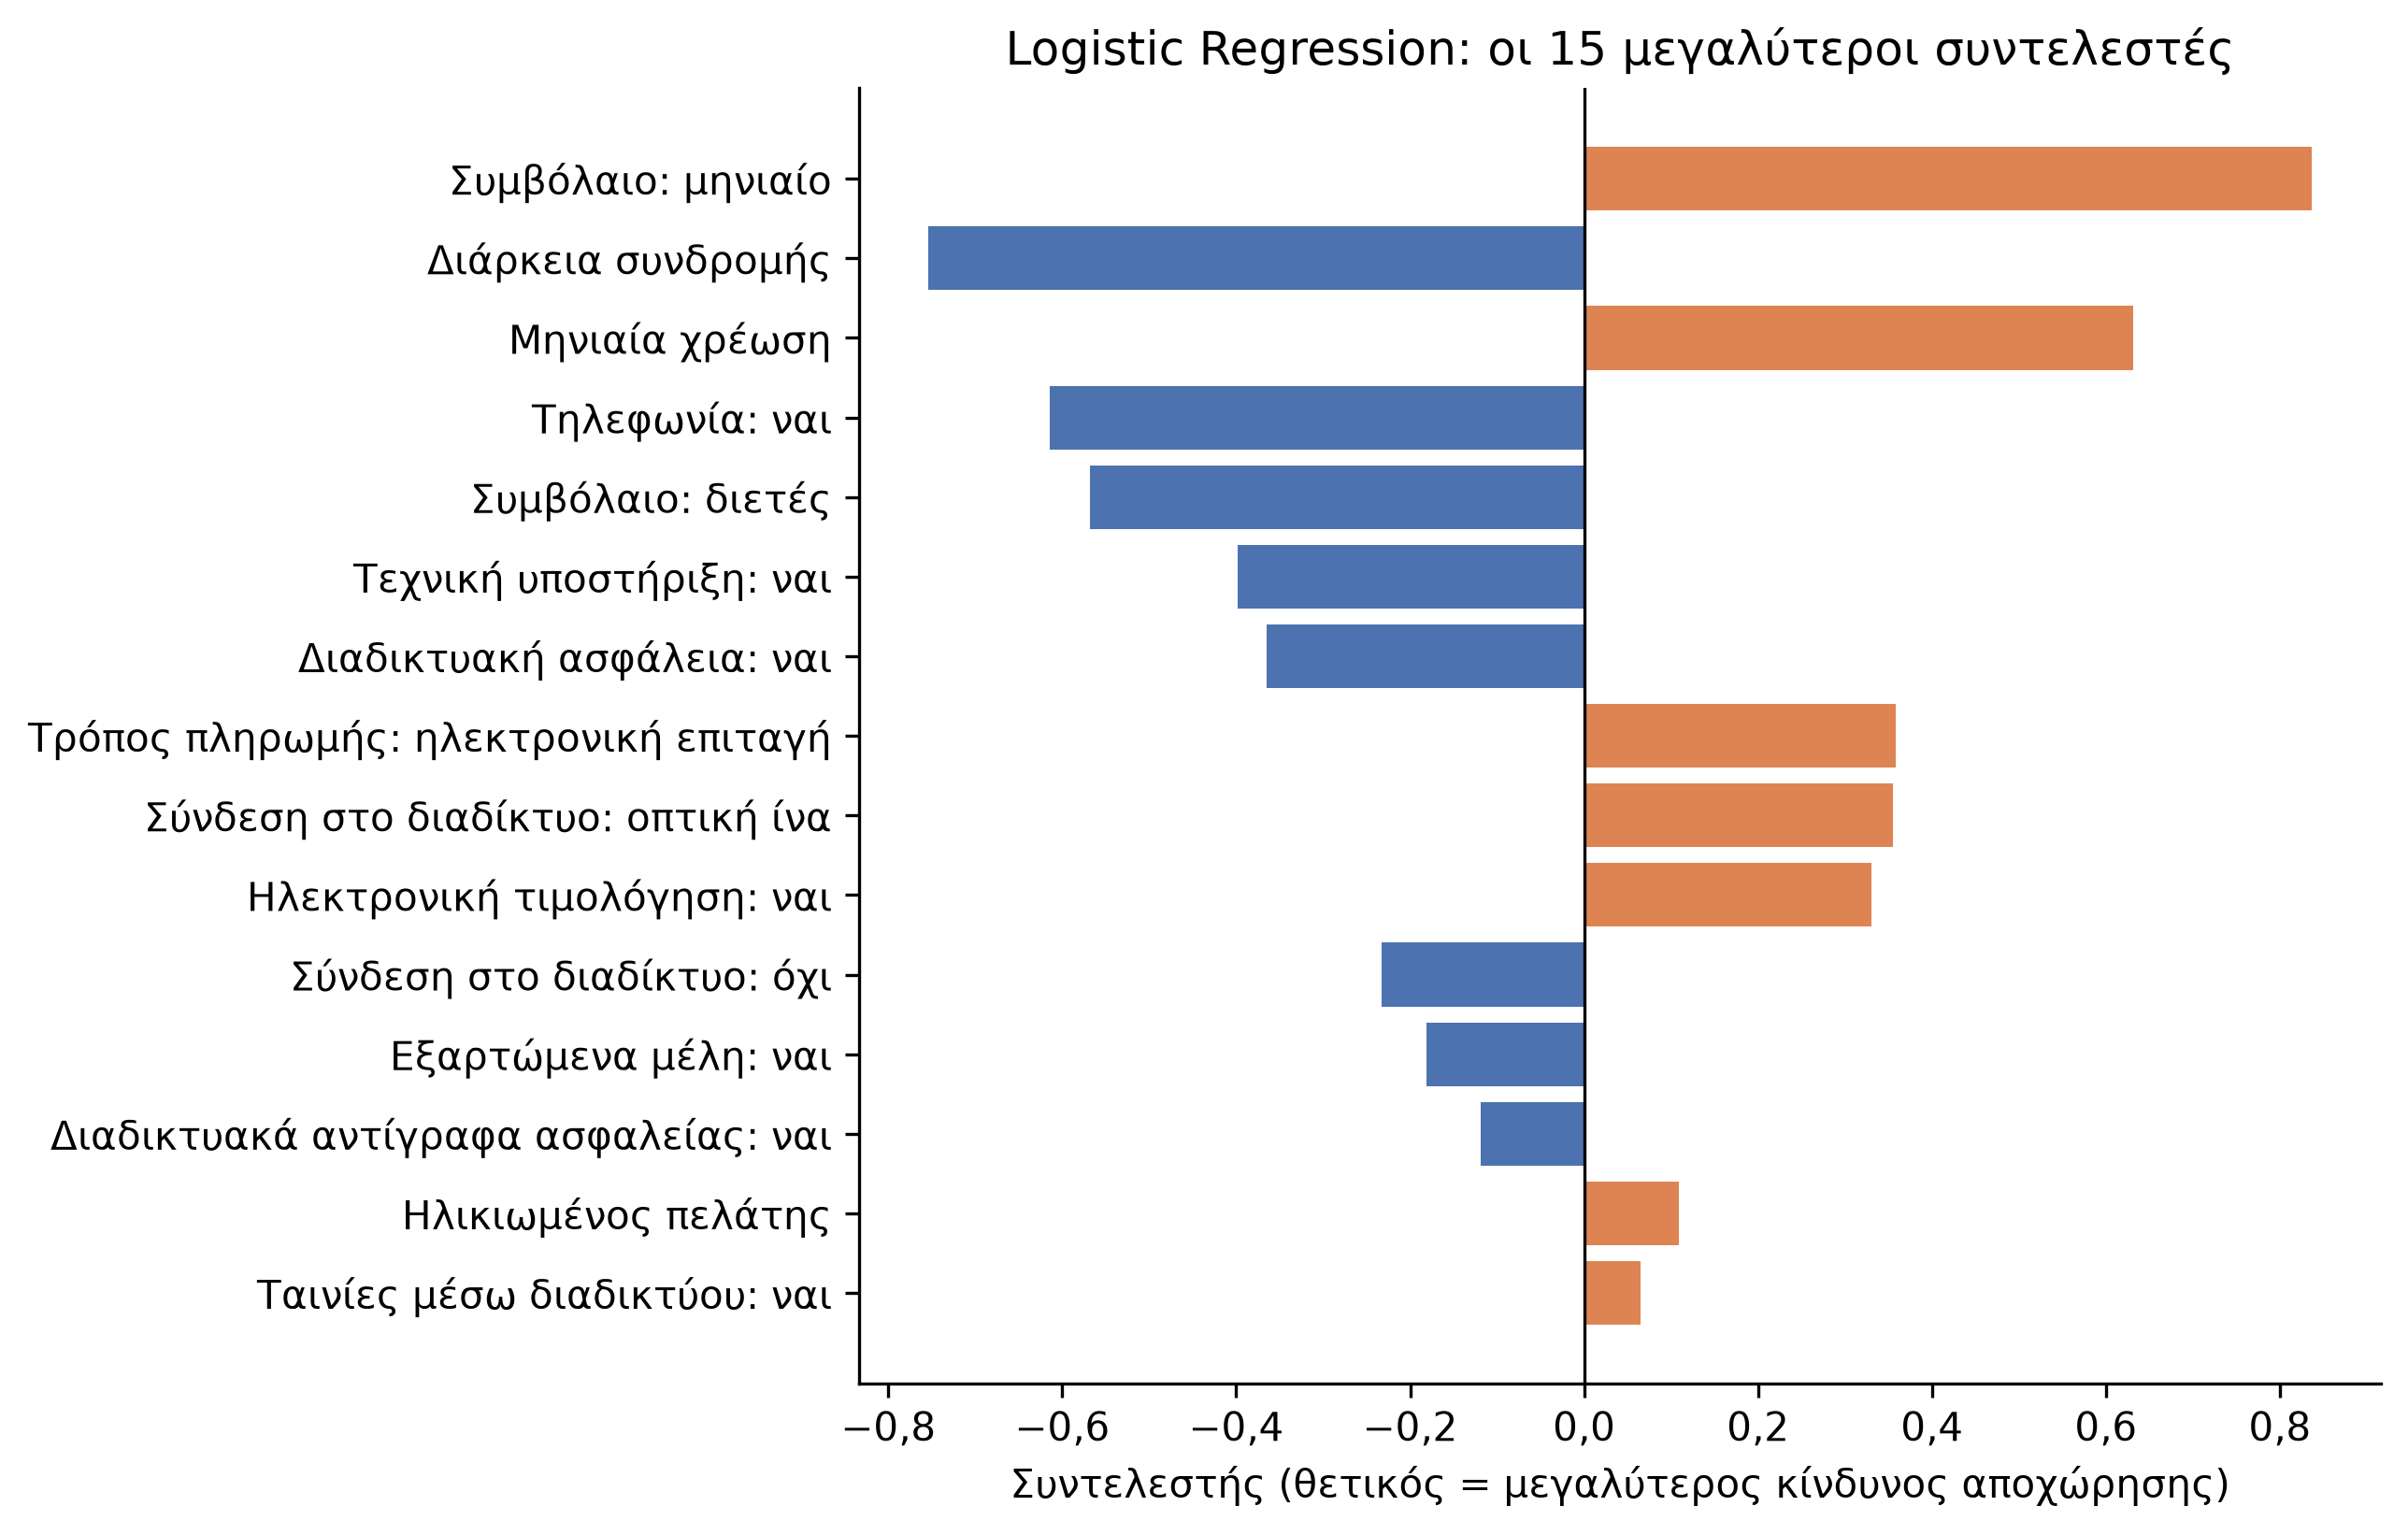

In [26]:
Image(filename=str(FIGURES / "logreg_coefficients.png"), width=850)

## 3. Νευρωνικό δίκτυο (TensorFlow/Keras)
### 3.1 Αρχιτεκτονική
Το προχωρημένο MLP συνδυάζει Batch Normalization, Dropout, ποινές L1/L2 και residual συνδέσεις
(`src/nn_models.py`). Ακολουθεί η δομή του τελικού μοντέλου:

In [27]:
# Το τελικό MLP είναι ensemble 5 μοντέλων με την ίδια αρχιτεκτονική (seeds 42–46). Δείχνουμε τη δομή ενός.
# Η αρχιτεκτονική χτίζεται από την καλύτερη ρύθμιση του tuning, οπότε δεν χρειάζεται το εκπαιδευμένο αρχείο.
from src.data import load_splits
from src.nn_models import build_advanced_mlp
from src.preprocessing import build_preprocessor

X_train, *_ = load_splits()
n_features = build_preprocessor().fit(X_train).transform(X_train.head(1)).shape[1]
best = json.loads((METRICS / "nn_tuning_best.json").read_text())["params"]
final_nn = build_advanced_mlp(best, n_features)
final_nn.summary()
print(json.loads((METRICS / "mlp_tuned.json").read_text())["ensemble_seeds"])

Model: "mlp_advanced"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 25)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 32)        │        832 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 32)        │          0 │ dense[0][0]       │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 32)        │          0 │ activation[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 32)        │      1,056 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 32)        │          0 │ dense_1[0][0]     │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 32)        │          0 │ activation_1[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 32)        │      1,056 │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 32)        │          0 │ dropout[0][0],    │
│                     │                   │            │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 32)        │          0 │ add[0][0]         │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 1)         │         33 │ activation_2[0][… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,977 (11.63 KB)

 Trainable params: 2,977 (11.63 KB)

 Non-trainable params: 0 (0.00 B)

[42, 43, 44, 45, 46]


### 3.2 Σύγκριση μεθόδων hyperparameter tuning
Τέσσερις μέθοδοι, 3 seeds η καθεμία, με ίδιο χώρο αναζήτησης και ίδιο προϋπολογισμό σε εποχές
(`src/nn_tuning.py`). Για να ξανατρέξει: `python main.py nn-tune`.

In [28]:
pd.read_csv(TABLES / "tuning_comparison.csv")

,method,Μέθοδος,best_val_auc_mean,best_val_auc_std,n_trials_mean,epochs_mean,minutes_mean,minutes_std
0,random,Random Search (KerasTuner),0.8336,0.0008,49.3333,1768.6667,12.1480,7.8697
1,hyperband,Hyperband (KerasTuner),0.8331,0.0013,254.0000,1752.0000,44.7499,37.3244
2,bayesian,Bayesian Optimization (KerasTuner),0.8329,0.0009,55.3333,1778.6667,15.9867,12.2543
3,optuna_tpe,TPE (Optuna),0.8327,0.0004,57.0000,1768.3333,3.0134,0.2764


In [29]:
pd.read_csv(TABLES / "tuning_runs.csv")

,method,seed,budget,best_val_auc,n_trials,epochs_used,minutes
0,hyperband,42,1761,0.8324,254,1761,12.4489
1,random,42,1761,0.8329,47,1764,4.6506
2,bayesian,42,1761,0.8321,50,1768,5.5689
3,optuna_tpe,42,1761,0.8331,65,1762,3.2383
4,hyperband,43,1689,0.8323,254,1689,36.1902
5,random,43,1689,0.8335,53,1695,11.4500
6,bayesian,43,1689,0.8326,53,1710,12.9029
7,optuna_tpe,43,1689,0.8324,57,1694,3.0971
8,hyperband,44,1806,0.8346,254,1806,85.6107
9,random,44,1806,0.8344,48,1847,20.3435


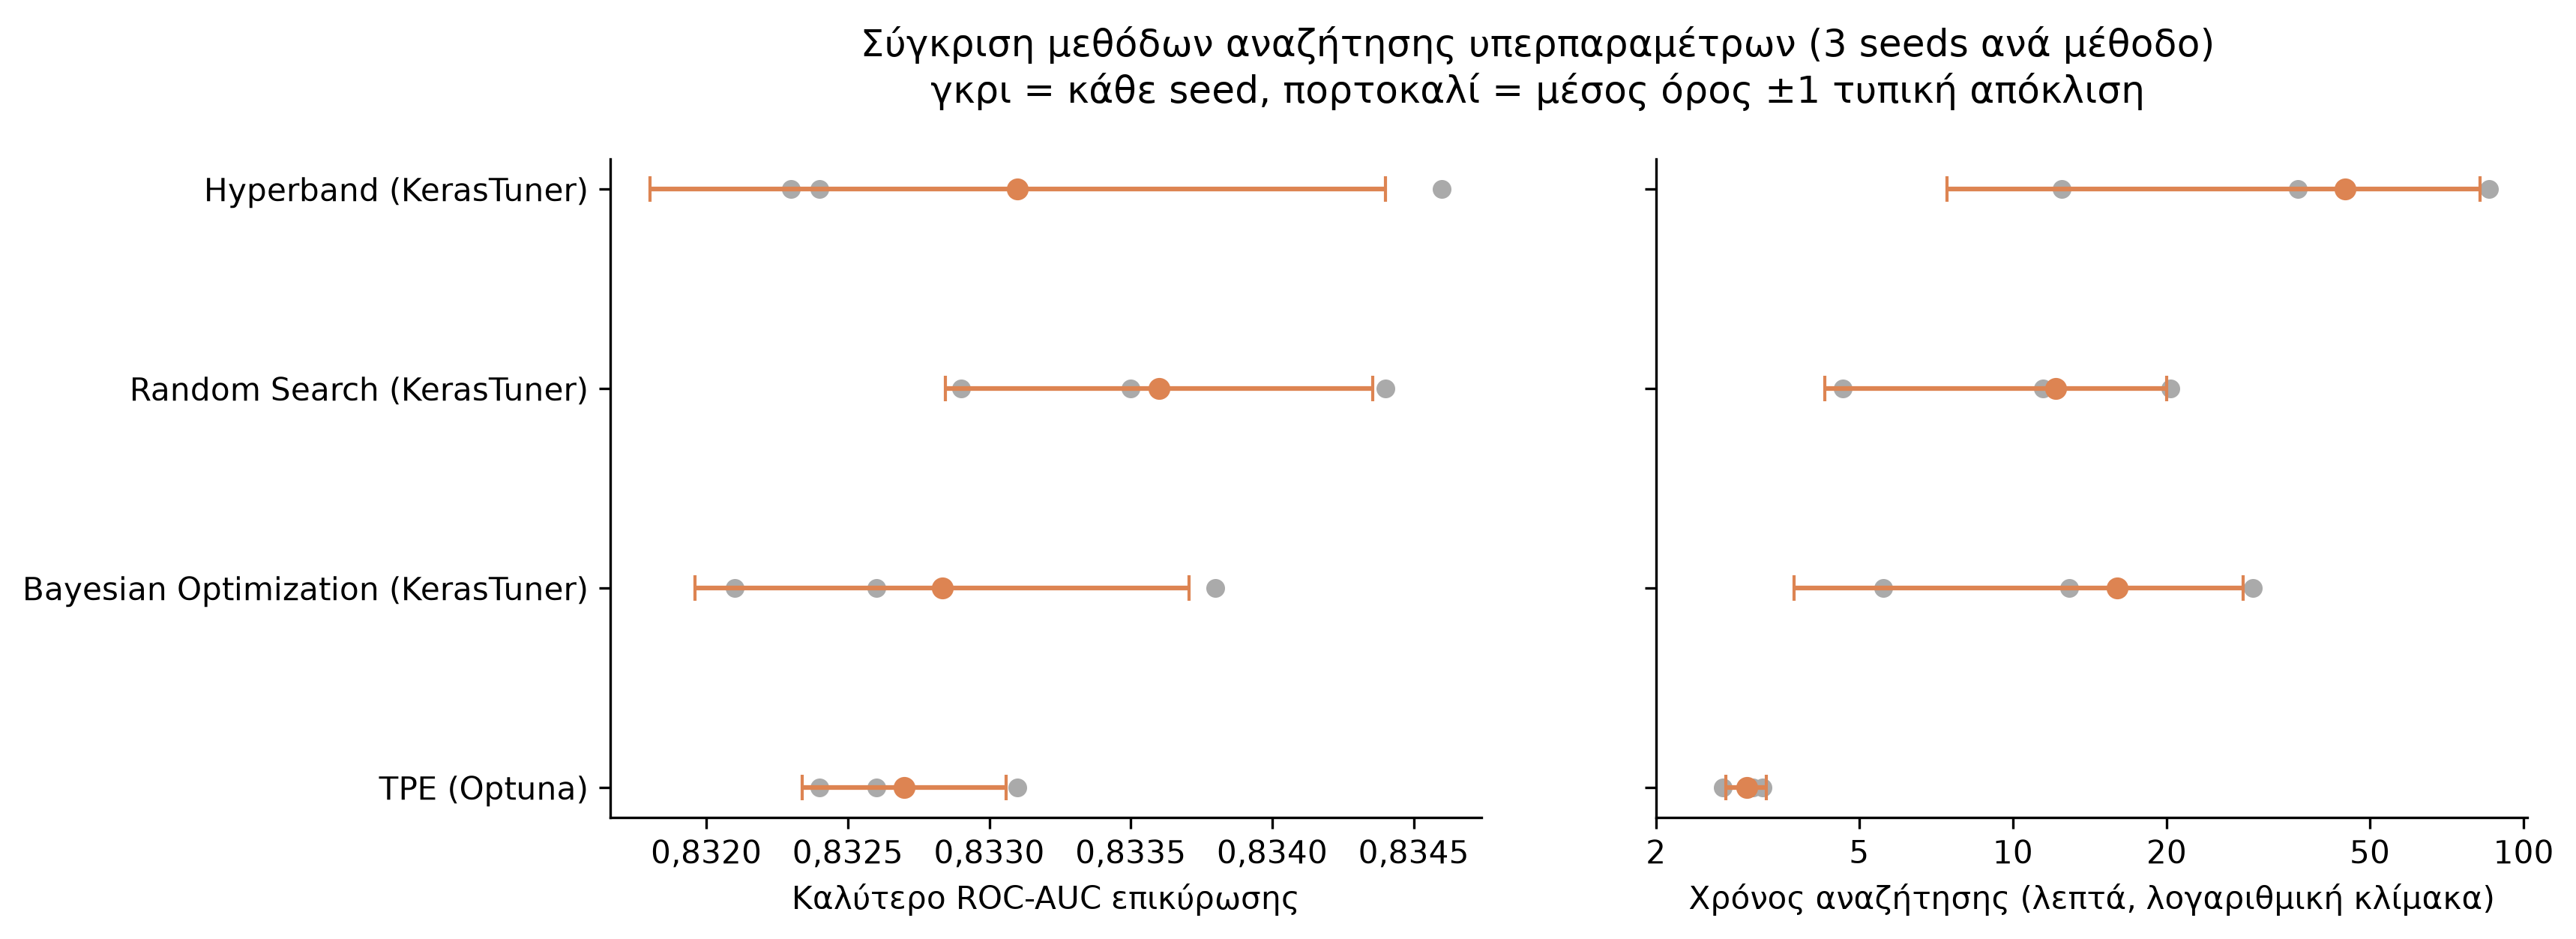

In [30]:
Image(filename=str(FIGURES / "tuning_methods.png"), width=850)

In [31]:
json.loads((METRICS / "nn_tuning_best.json").read_text())

{'method': 'hyperband',
 'seed': 44,
 'val_auc': 0.834570050239563,
 'budget_epochs': 1806,
 'params': {'units': 32,
  'n_blocks': 1,
  'dropout': 0.0,
  'l1': 0.0001,
  'l2': 1e-05,
  'use_residual': True,
  'use_bn': False,
  'lr': 0.001945510412913914,
  'batch_size': 128}}

### 3.3 Εκπαίδευση, έλεγχος overfitting και διακύμανση ανάμεσα στα seeds
Το τελικό μοντέλο είναι ensemble 5 seeds (μέσος όρος πιθανοτήτων).

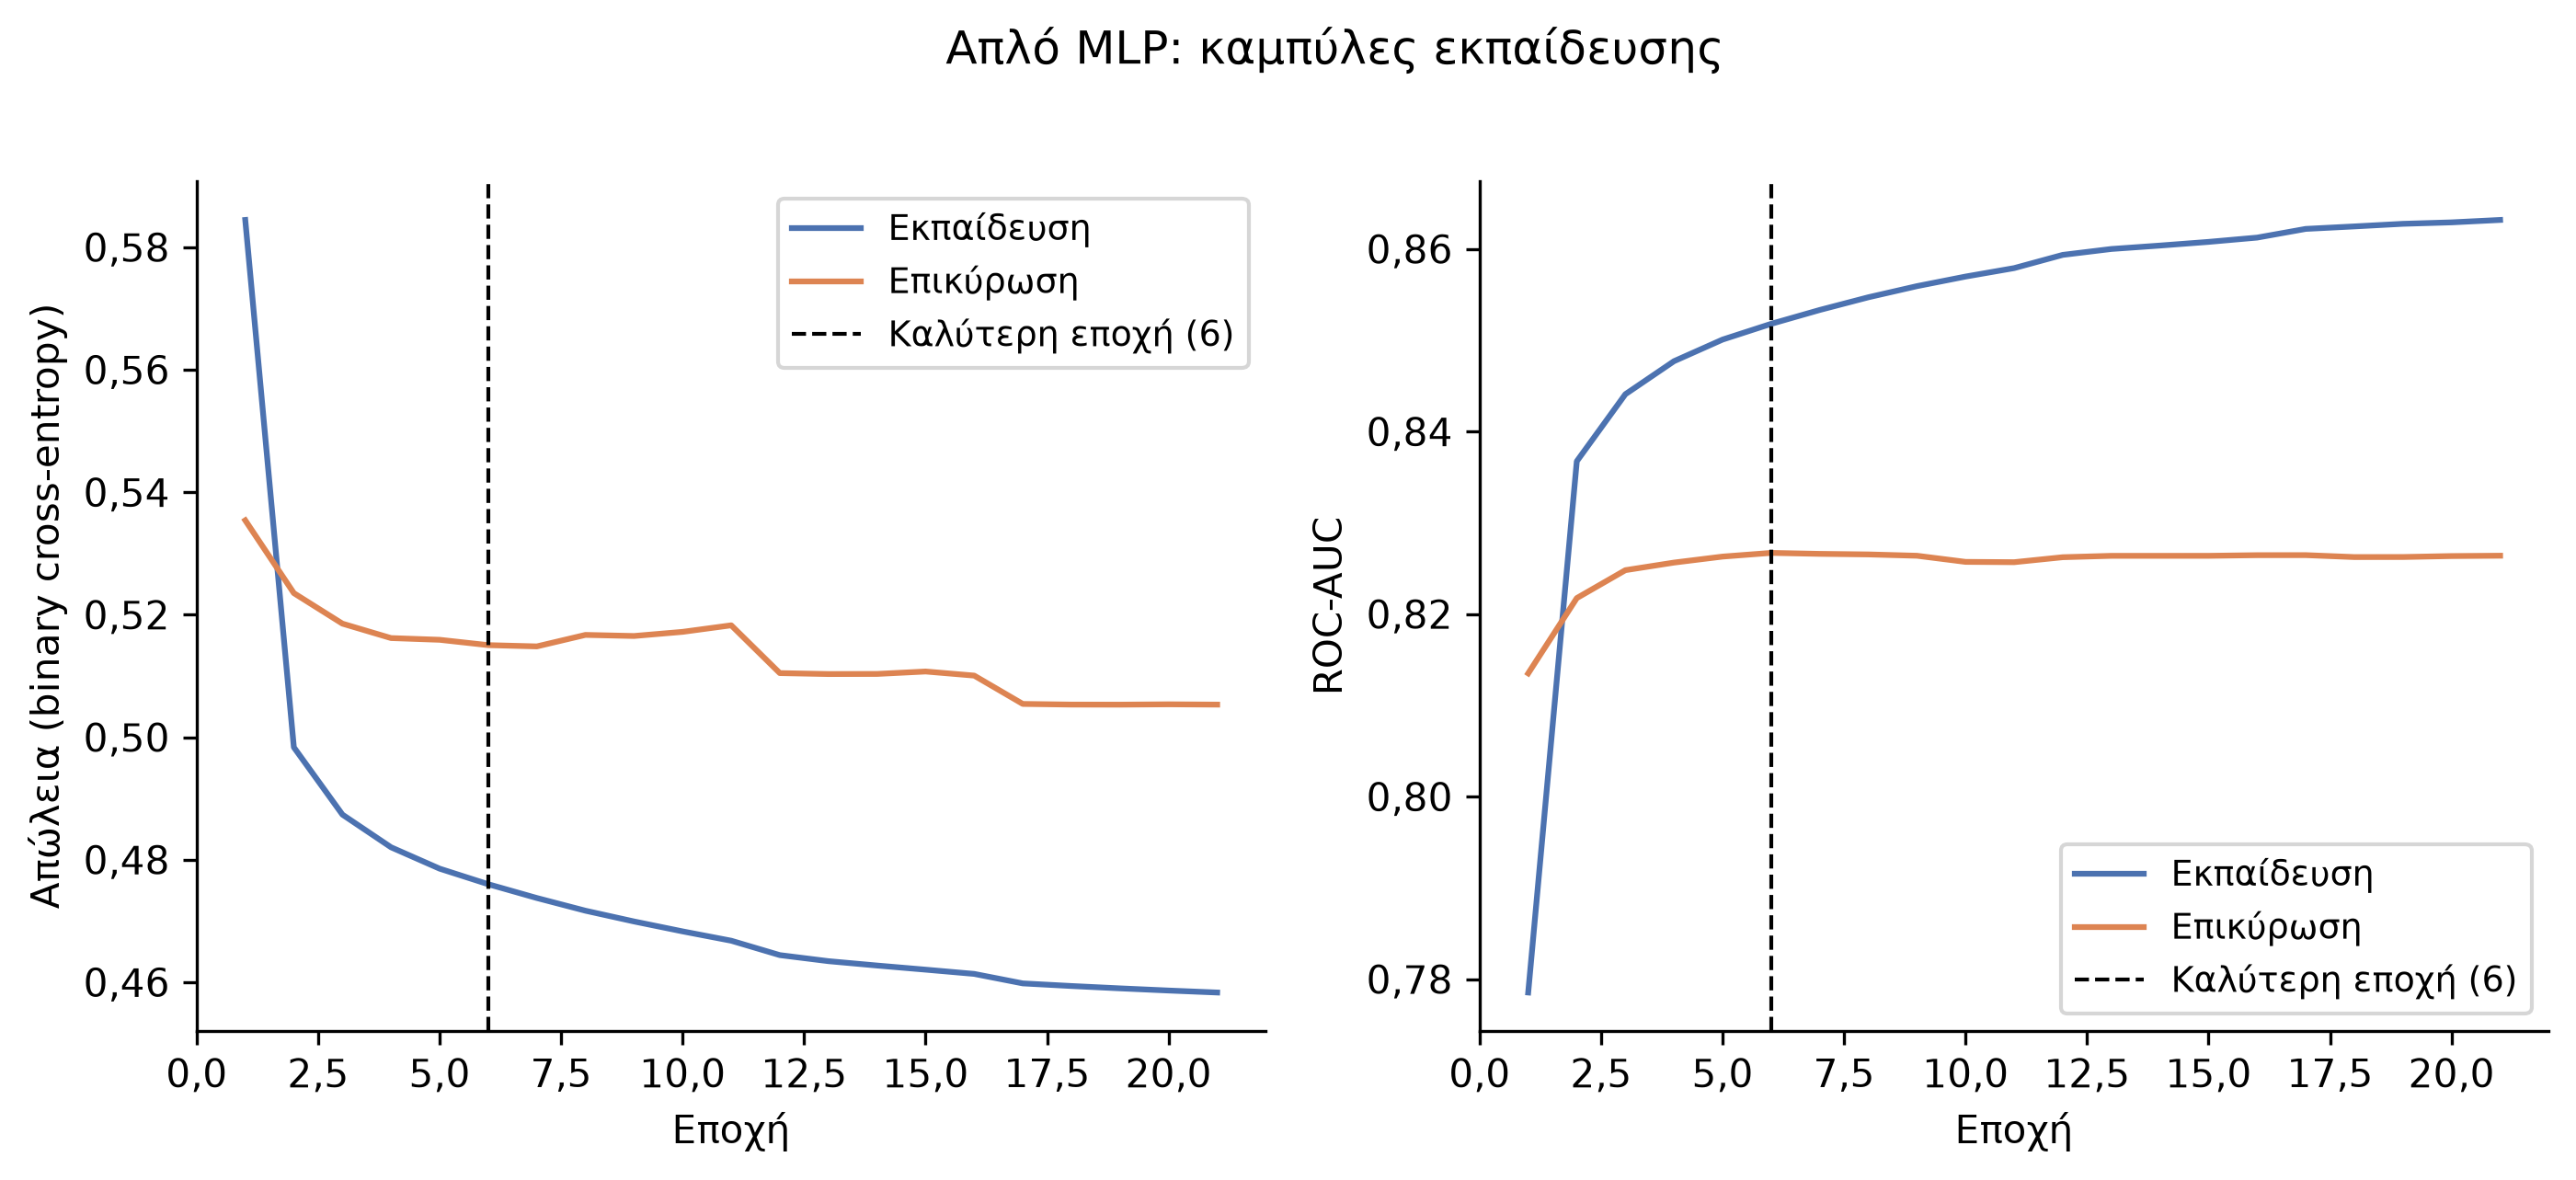

In [32]:
Image(filename=str(FIGURES / "nn_simple_curves.png"), width=850)

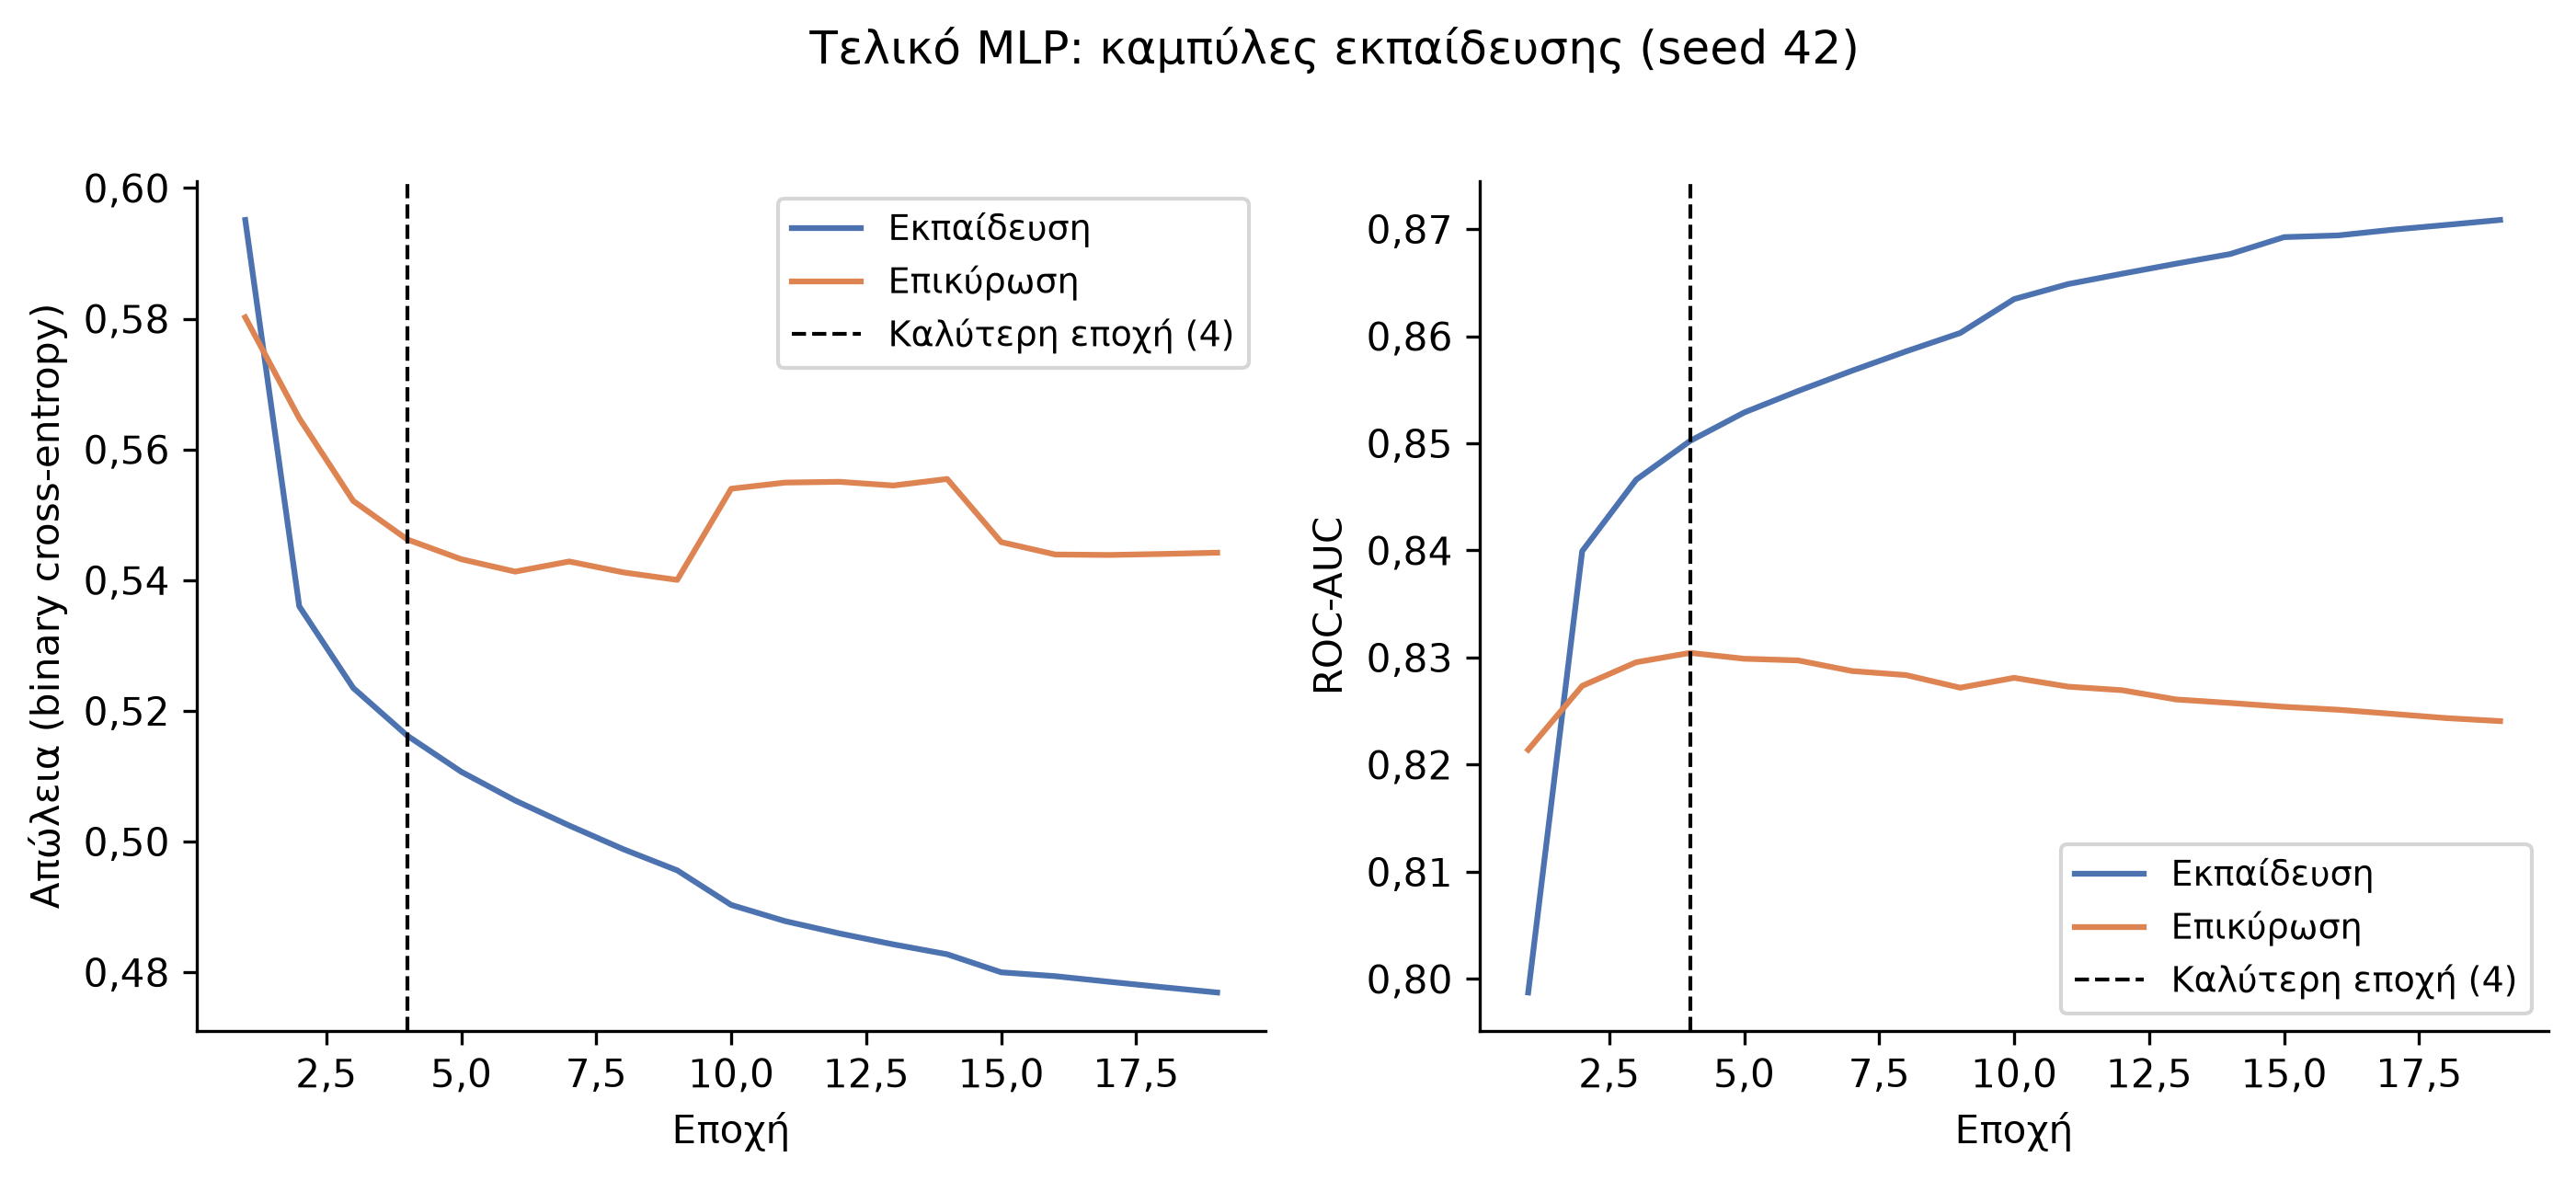

In [33]:
Image(filename=str(FIGURES / "nn_tuned_curves.png"), width=850)

In [34]:
pd.read_csv(TABLES / "nn_seed_variability.csv")

,model,seed,val_auc,val_f1,best_epoch,epochs_run
0,mlp_tuned,42,0.8303,0.6382,4.0,19.0
1,mlp_tuned,43,0.8326,0.6337,15.0,30.0
2,mlp_tuned,44,0.8312,0.6212,8.0,23.0
3,mlp_tuned,45,0.8300,0.6244,9.0,24.0
4,mlp_tuned,46,0.8335,0.6317,6.0,21.0
5,mlp_simple,42,0.8267,0.6260,6.0,21.0
6,mlp_simple,43,0.8278,0.6263,13.0,28.0
7,mlp_simple,44,0.8313,0.6341,7.0,22.0
8,mlp_simple,45,0.8278,0.6265,13.0,28.0
9,mlp_simple,46,0.8304,0.6314,11.0,26.0


### 3.4 Ablation: τι προσφέρει κάθε τεχνική
(α) αφαίρεση από την τελική ρύθμιση, (β) προσθήκη σε απλό δίκτυο. 5 seeds, μόνο validation.

In [35]:
pd.read_csv(TABLES / "nn_ablation.csv")

,direction,variant,Παραλλαγή,val_auc_mean,val_auc_std,val_f1_mean,stop_epoch_mean,note,delta_auc_vs_reference
0,remove,full,Τελική ρύθμιση,0.8315,0.0013,0.6299,23.4,NaN,0.0000
1,remove,no_bn,Τελική χωρίς Batch Normalization,NaN,NaN,NaN,NaN,δεν εφαρμόζεται: η τελική ρύθμιση δεν τη χρησι...,NaN
2,remove,no_dropout,Τελική χωρίς dropout,NaN,NaN,NaN,NaN,δεν εφαρμόζεται: η τελική ρύθμιση δεν τη χρησι...,NaN
3,remove,no_l1l2,Τελική χωρίς ποινές L1/L2,0.8311,0.0015,0.6292,20.8,NaN,-0.0004
4,remove,no_residual,Τελική χωρίς υπολειμματικές συνδέσεις,0.8297,0.0015,0.6261,26.8,NaN,-0.0018
5,add,plain,Δίκτυο χωρίς τεχνικές,0.8296,0.0014,0.6290,23.4,NaN,0.0000
6,add,plus_bn,Χωρίς τεχνικές + Batch Normalization,0.8274,0.0032,0.6257,20.6,NaN,-0.0022
7,add,plus_dropout,"Χωρίς τεχνικές + dropout 0,2",0.8291,0.0011,0.6294,26.8,NaN,-0.0005
8,add,plus_l1l2,Χωρίς τεχνικές + ποινή L2 10⁻⁴,0.8299,0.0012,0.6269,24.4,NaN,0.0003
9,add,plus_residual,Χωρίς τεχνικές + υπολειμματικές συνδέσεις,0.8311,0.0015,0.6292,20.8,NaN,0.0015


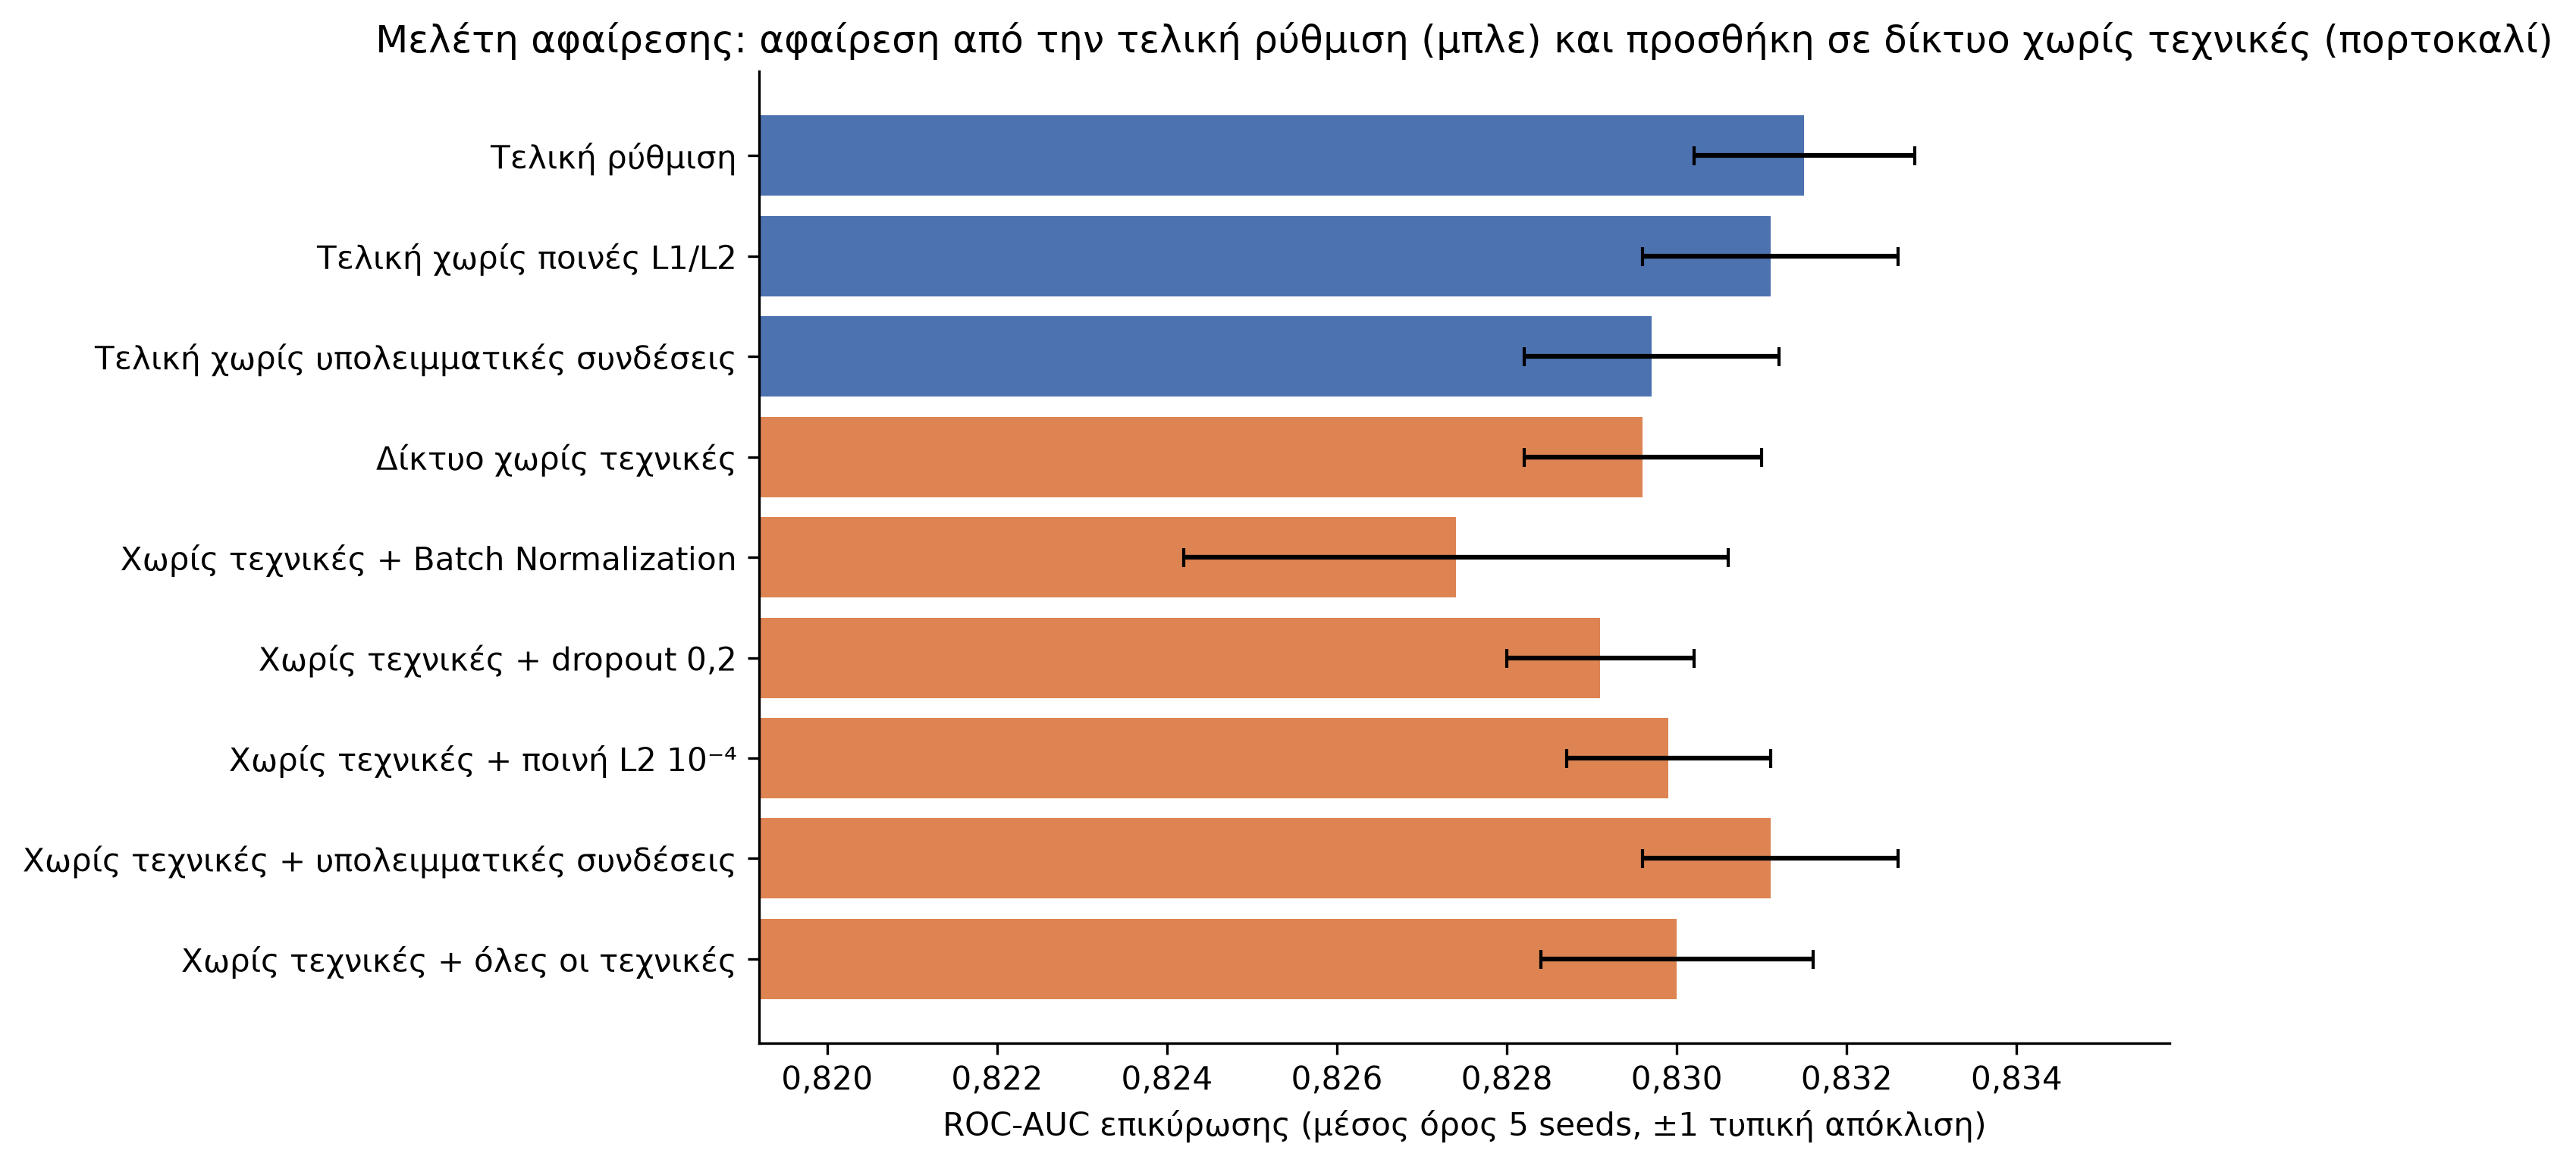

In [36]:
Image(filename=str(FIGURES / "nn_ablation.png"), width=850)

### 3.5 Επεξήγηση: SHAP και LIME
Και οι δύο μέθοδοι δουλεύουν στα αρχικά χαρακτηριστικά: κάθε κατηγορική μεταβλητή αλλάζει ως μία μονάδα,
χωρίς μη ρεαλιστικούς πελάτες.

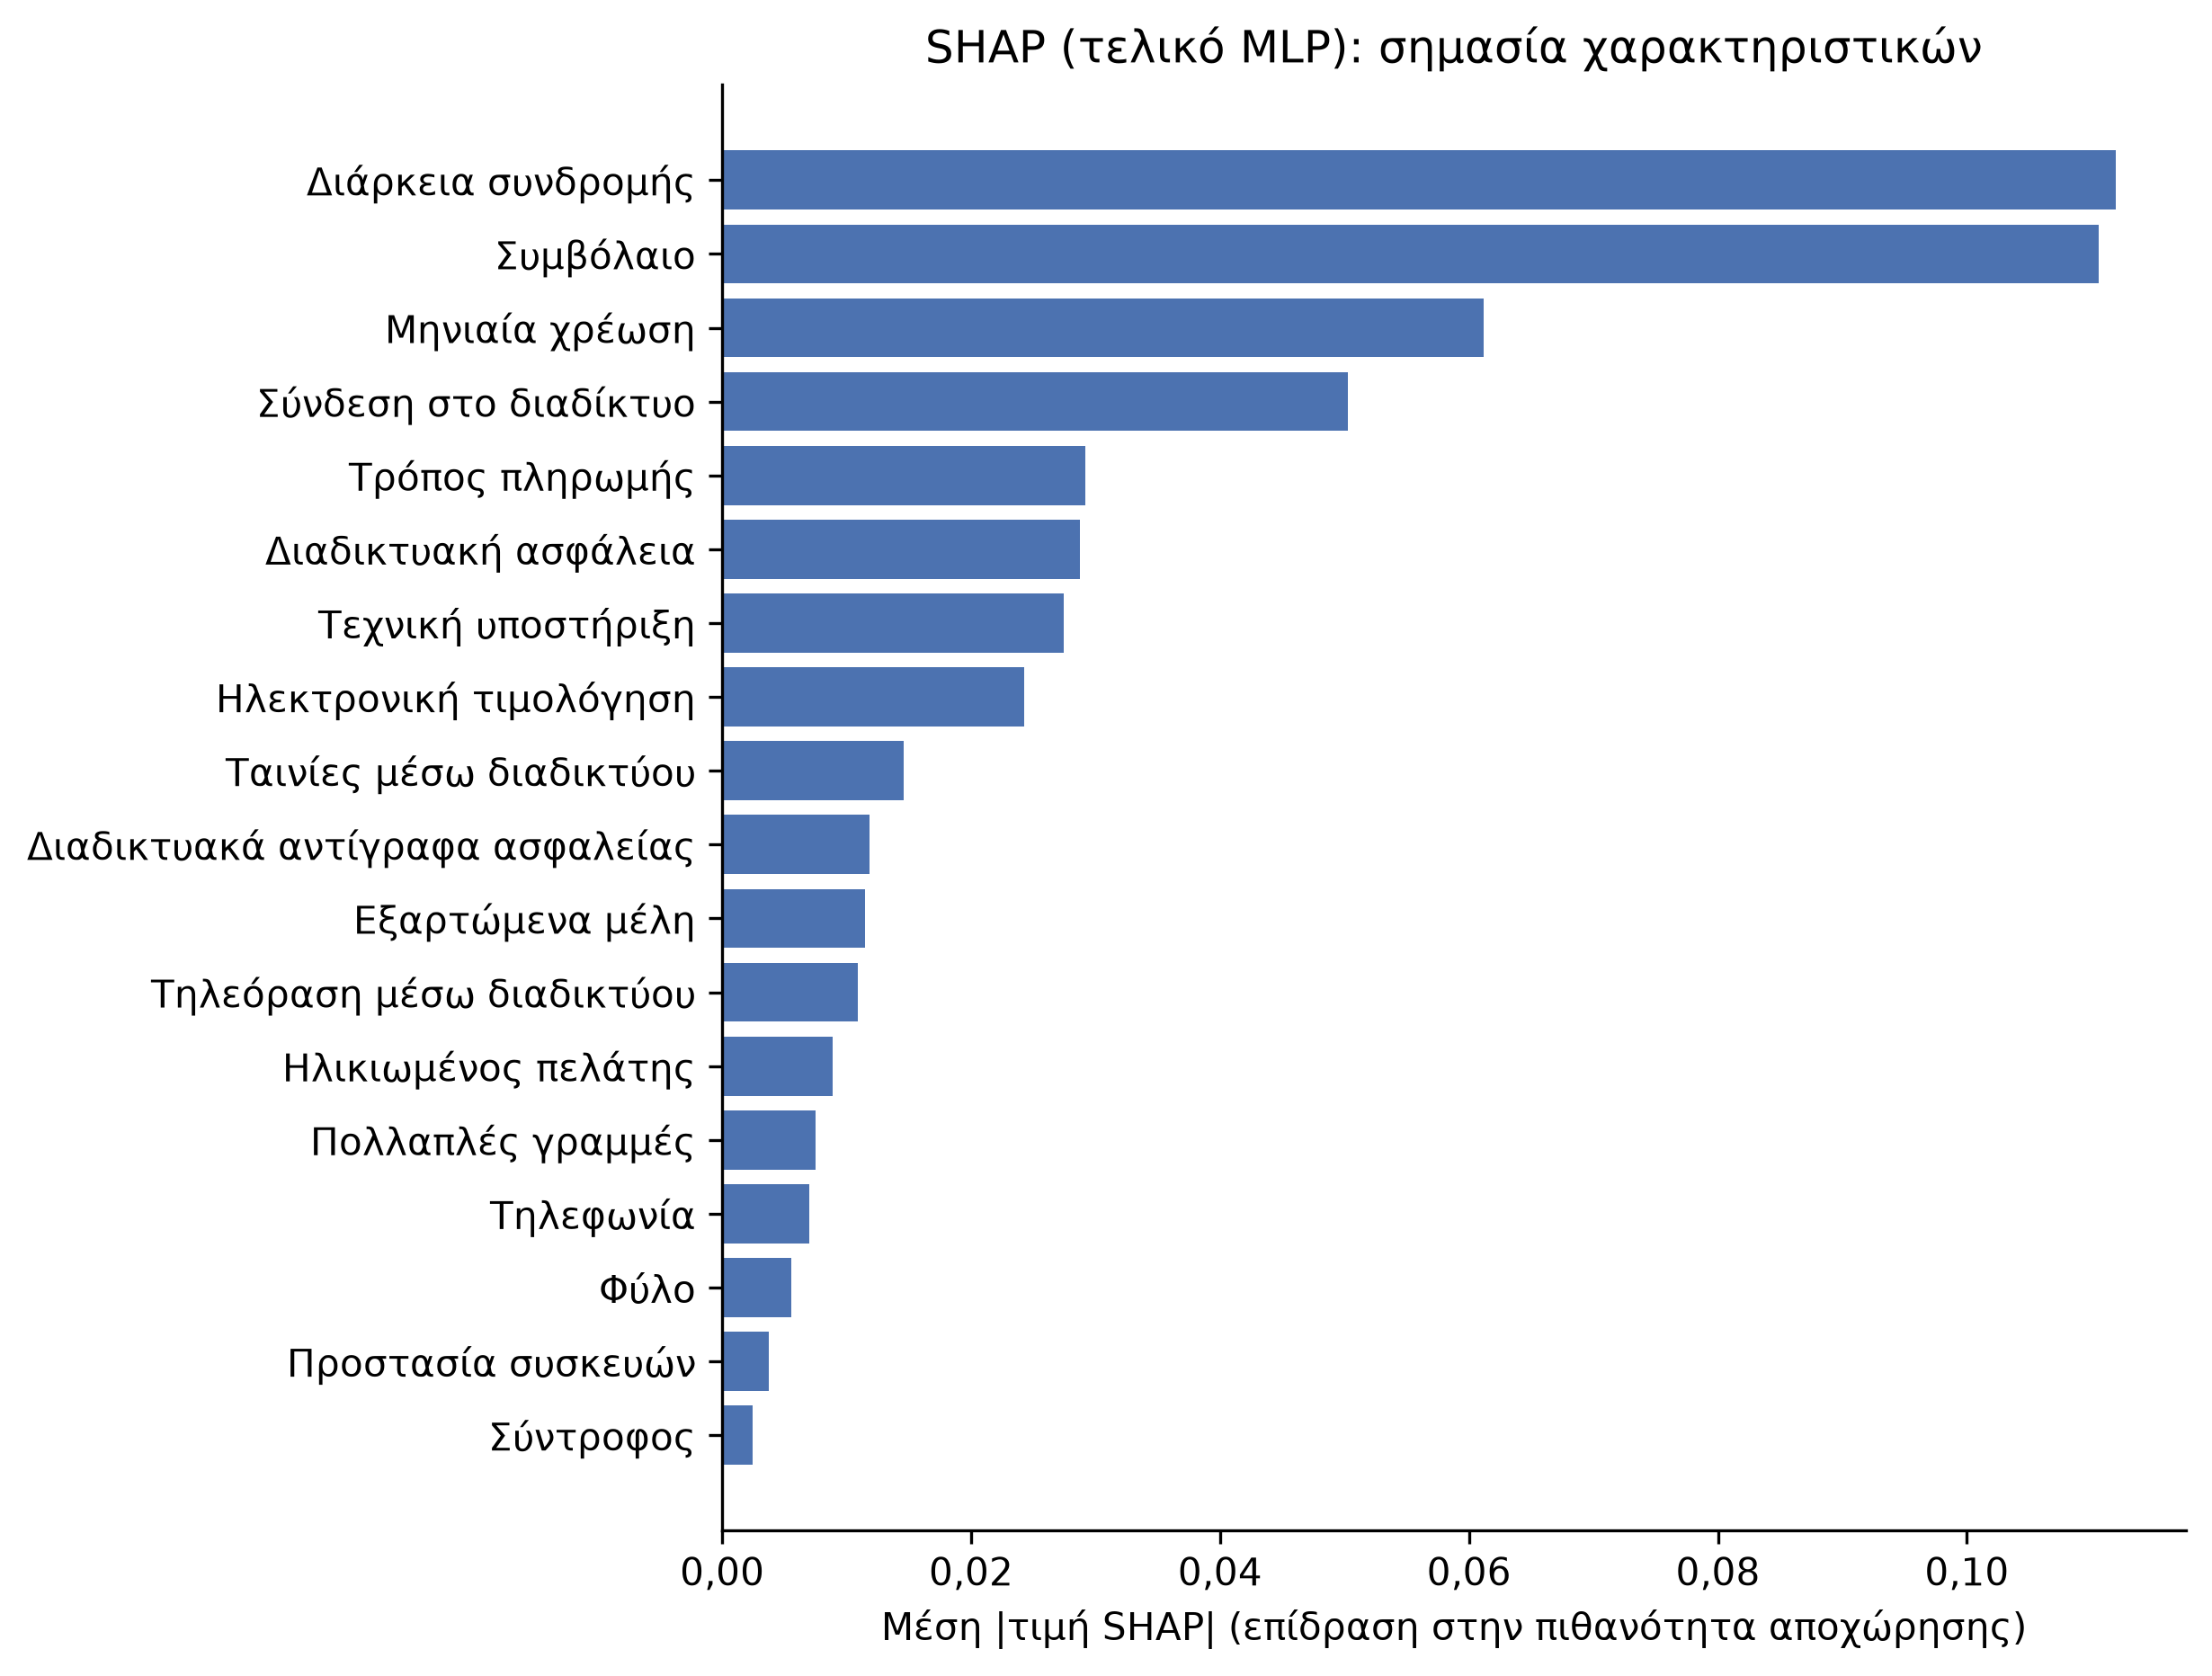

In [37]:
Image(filename=str(FIGURES / "shap_nn_bar.png"), width=850)

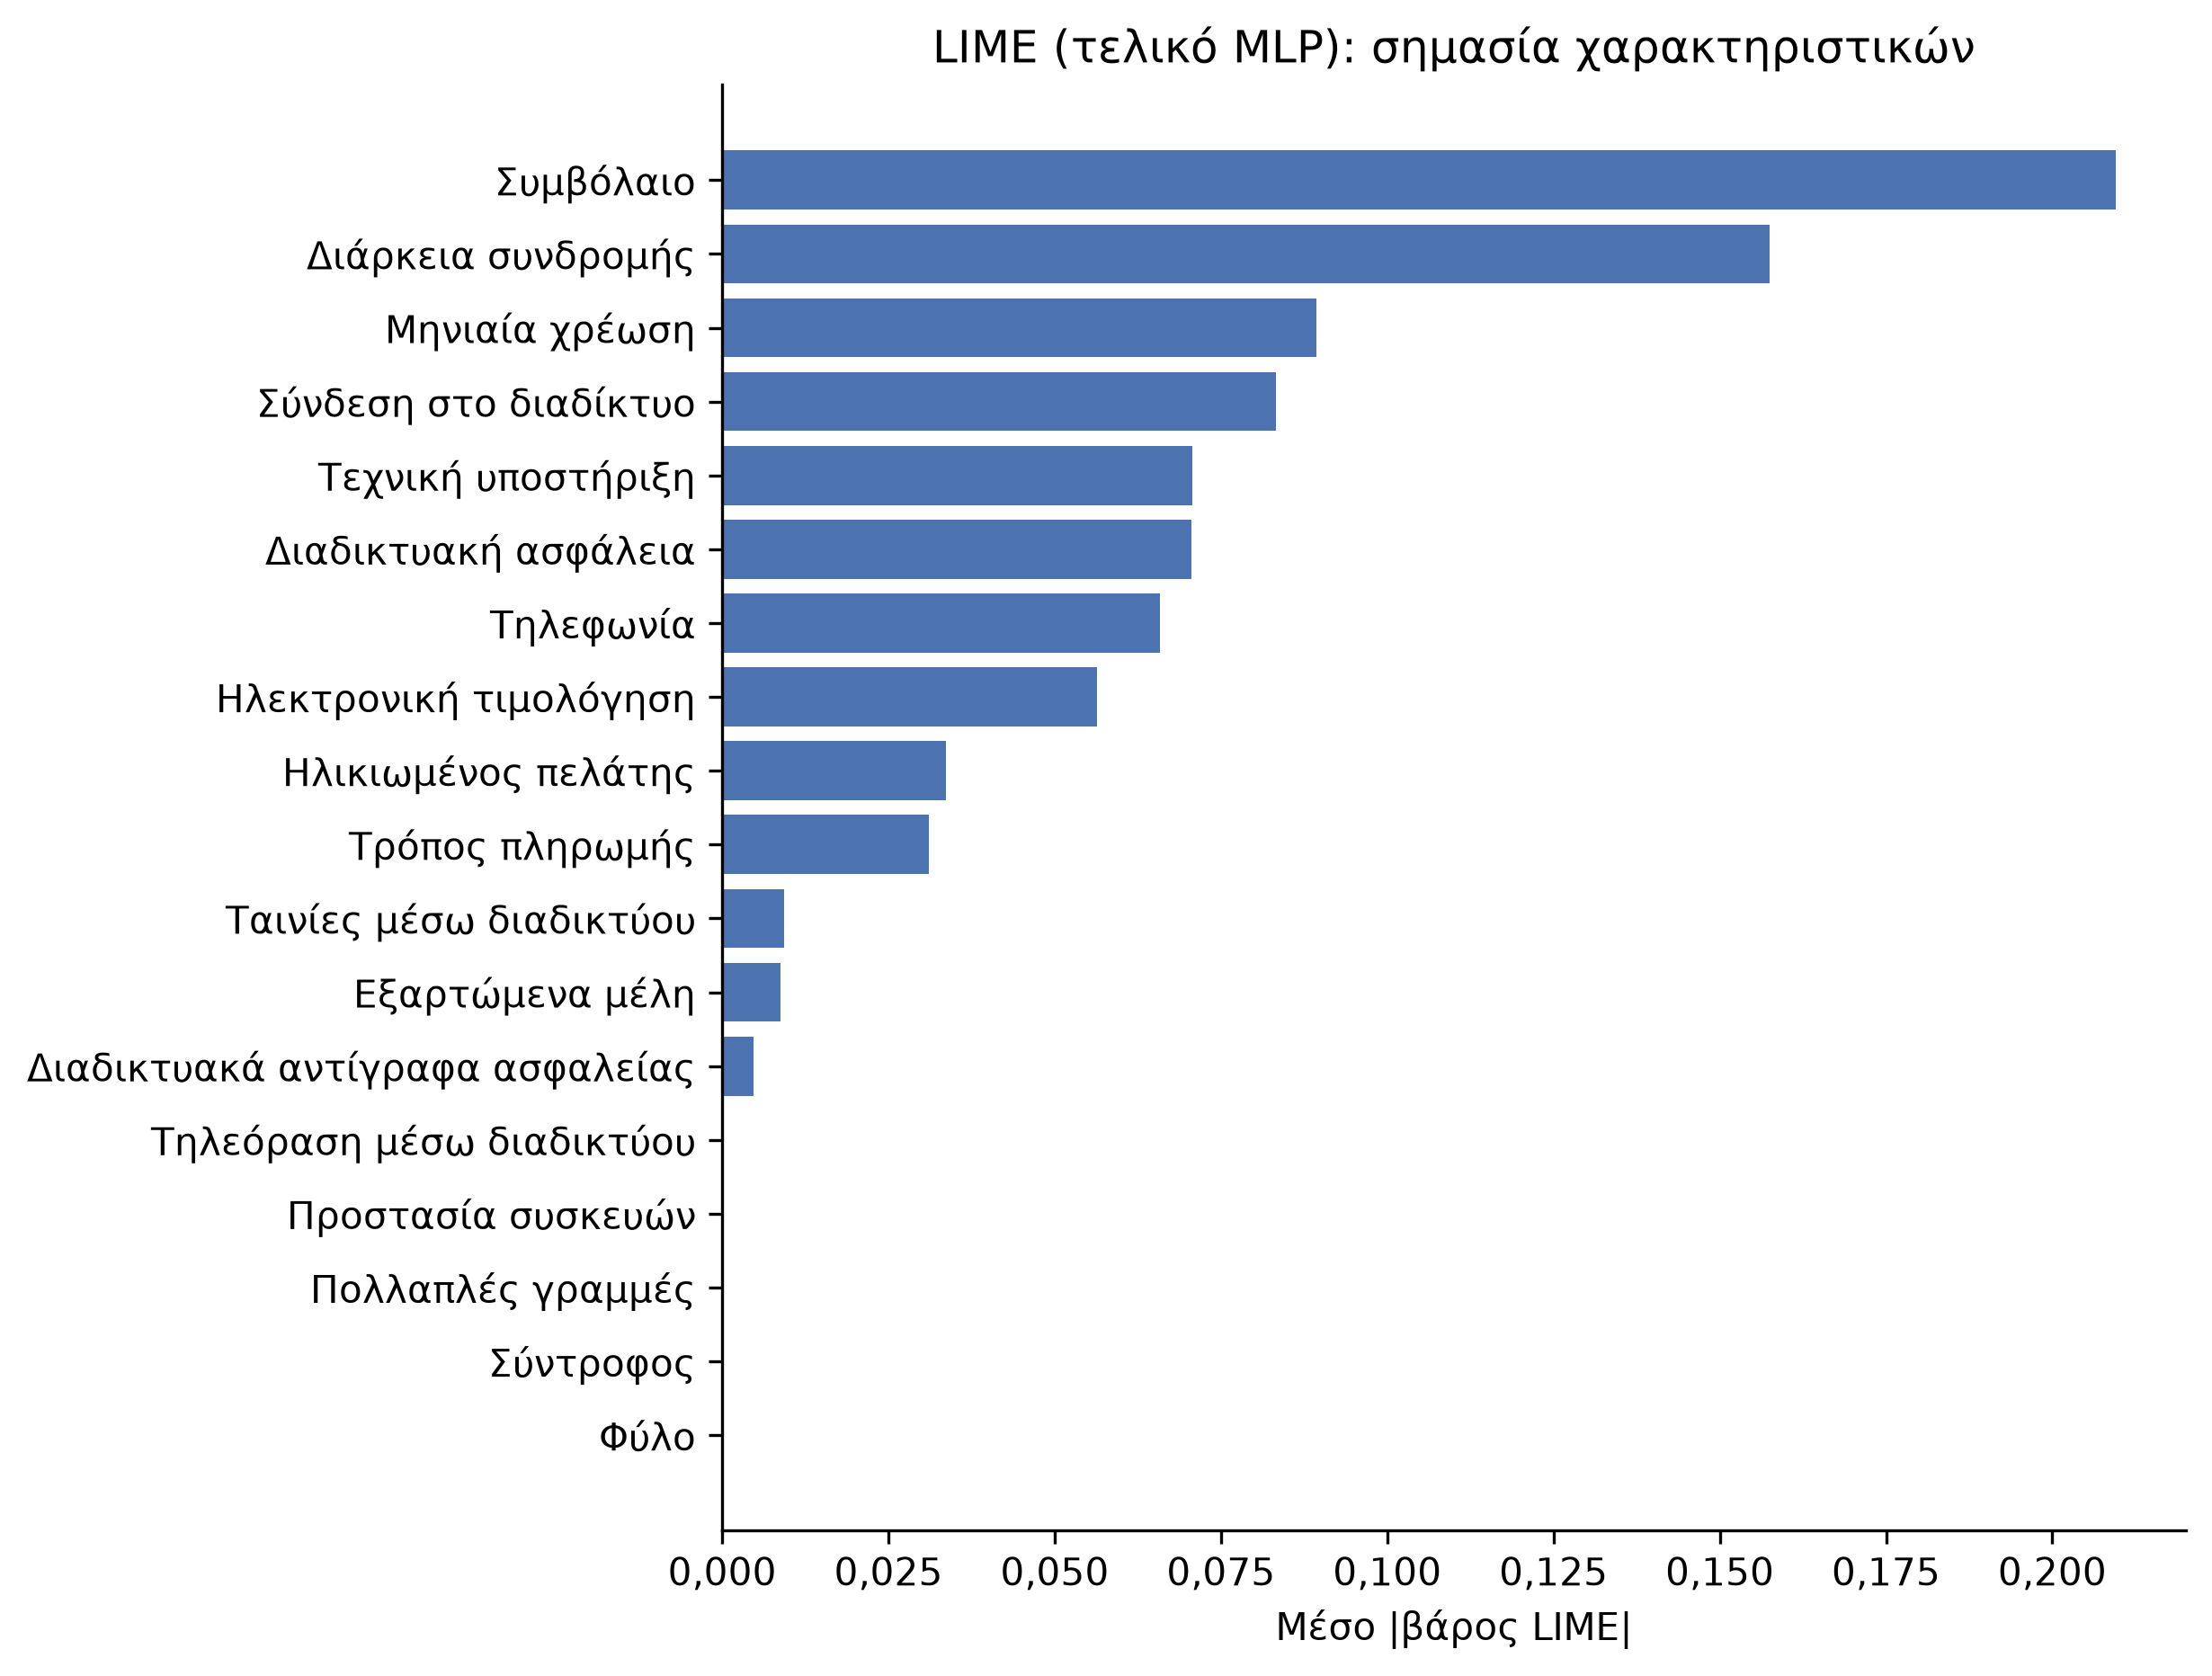

In [38]:
Image(filename=str(FIGURES / "lime_nn_bar.png"), width=850)

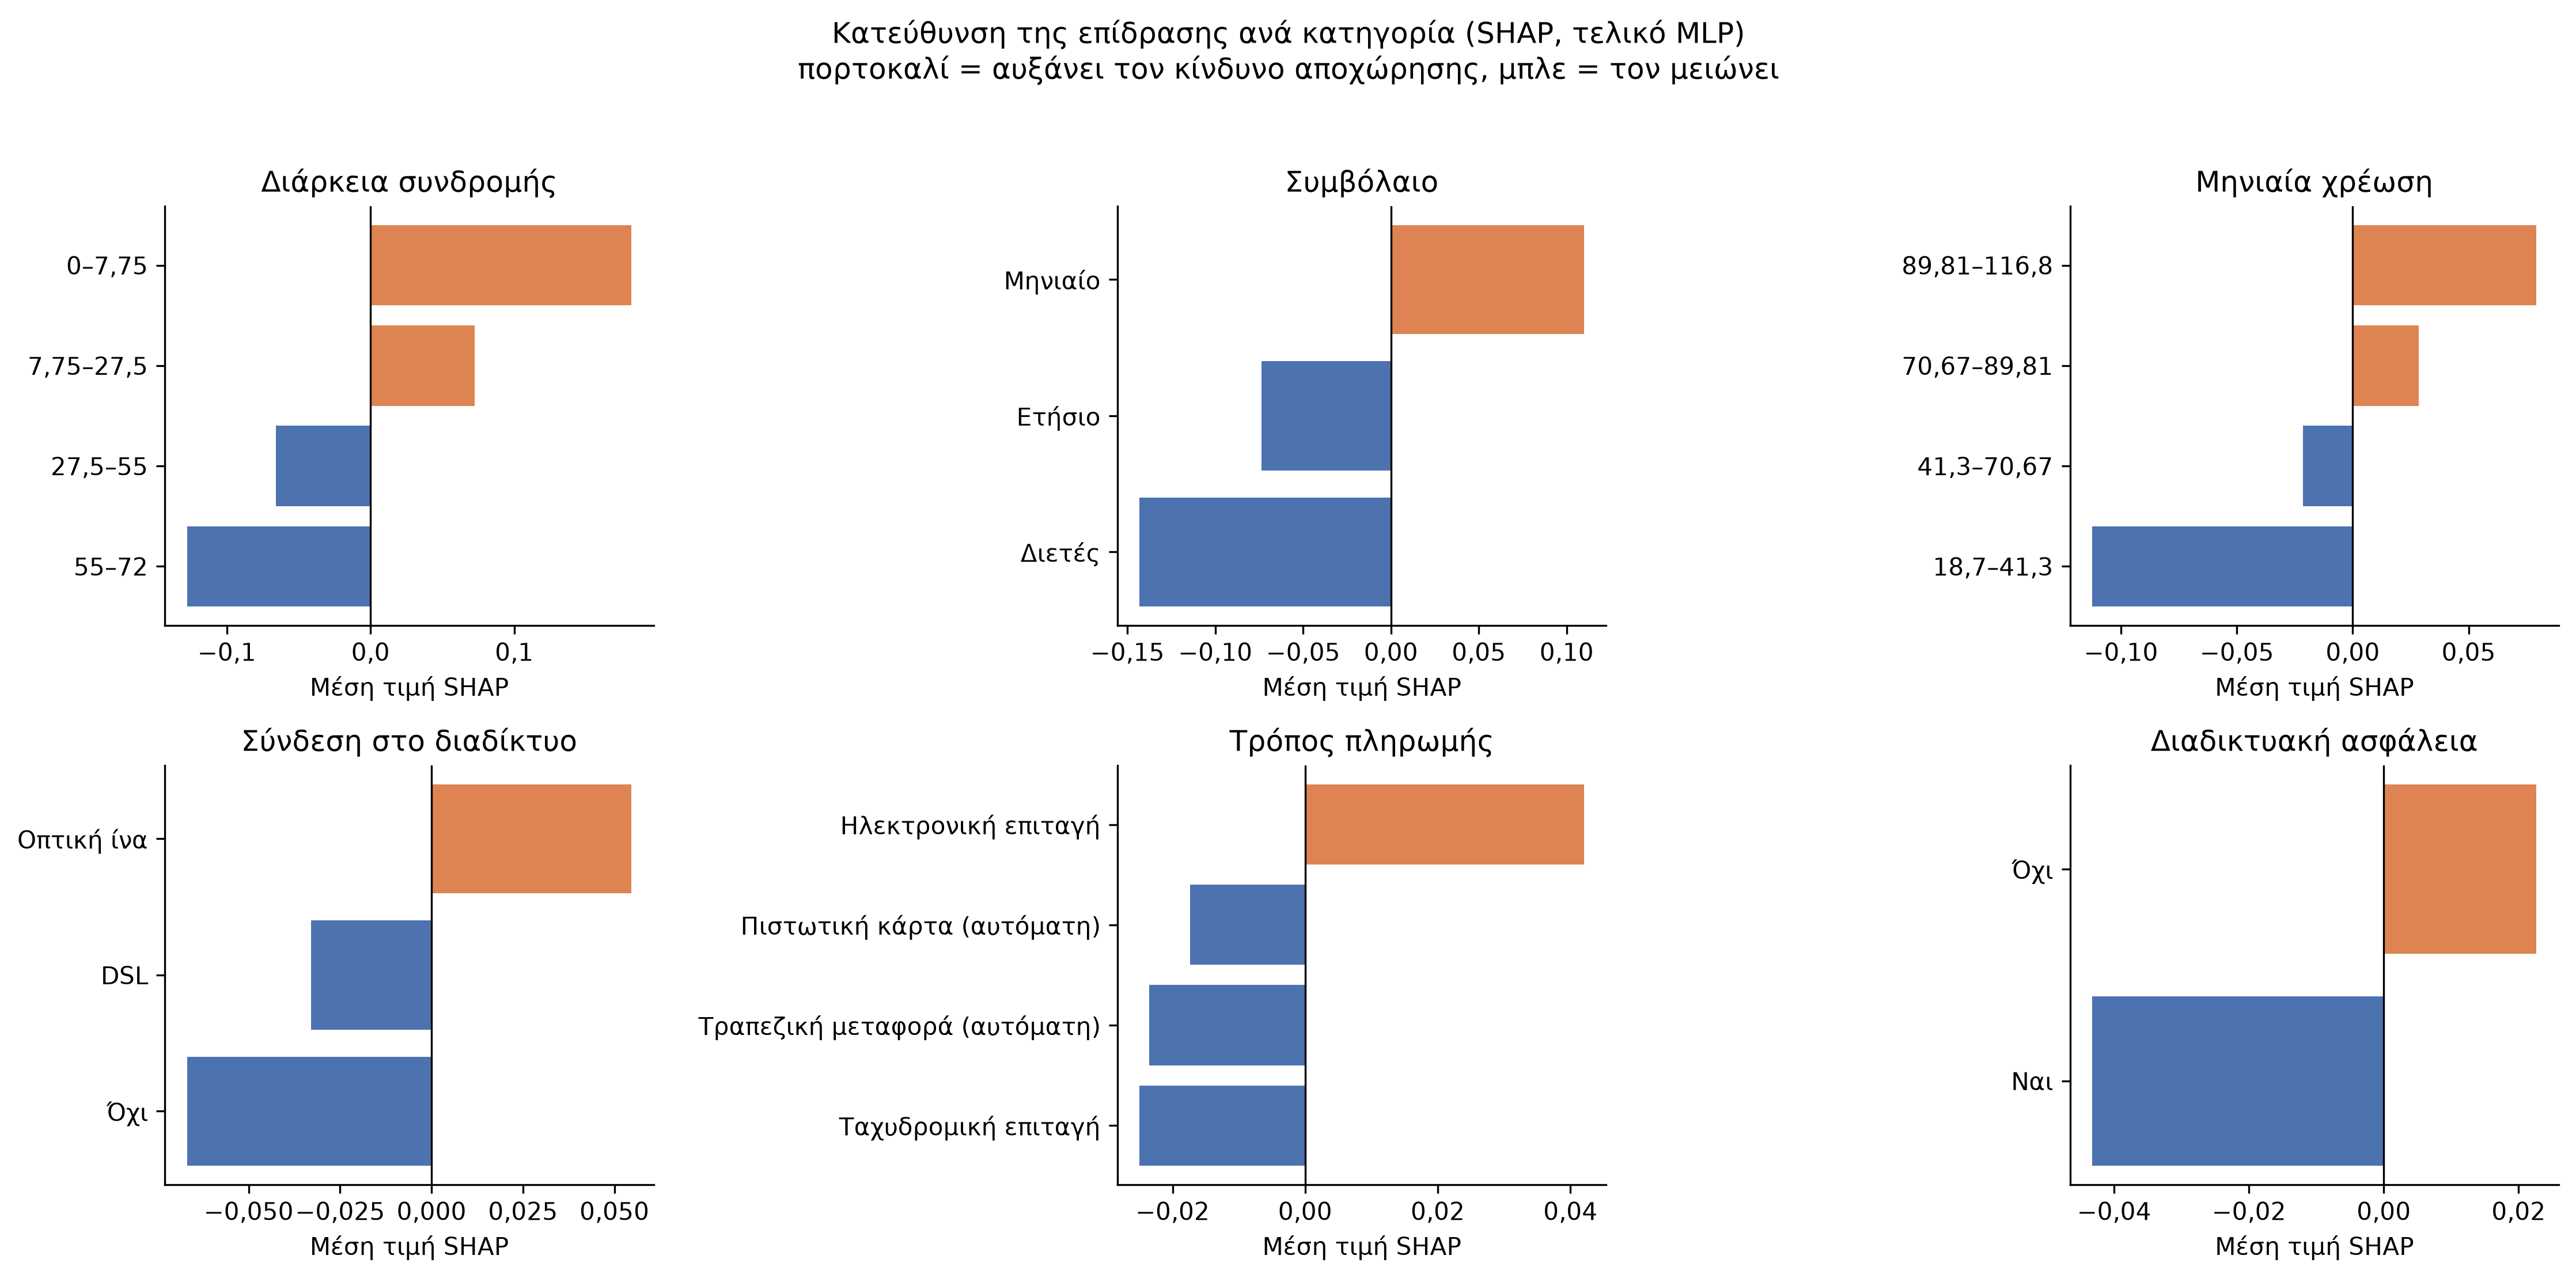

In [39]:
Image(filename=str(FIGURES / "shap_nn_by_category.png"), width=850)

In [40]:
pd.read_csv(TABLES / "shap_lime_agreement.csv")

,Μέτρο,Τιμή
0,Spearman ρ των συνολικών κατατάξεων (SHAP έναν...,0.8569
1,p-value του Spearman,0.0000
2,Μέση επικάλυψη των 5 κορυφαίων χαρακτηριστικών...,3.7500
3,Ελάχιστη επικάλυψη των 5 κορυφαίων χαρακτηριστ...,2.0000
4,Μέγιστη επικάλυψη των 5 κορυφαίων χαρακτηριστικών,5.0000


In [41]:
pd.read_csv(TABLES / "lime_stability.csv")

,Μέτρο,Τιμή
0,Μέση επικάλυψη των 5 κορυφαίων χαρακτηριστικών...,4.255
1,Ελάχιστη μέση επικάλυψη ζεύγους,4.050
2,Πλήθος εκτελέσεων (seeds),5.000
3,Πλήθος πελατών,20.000


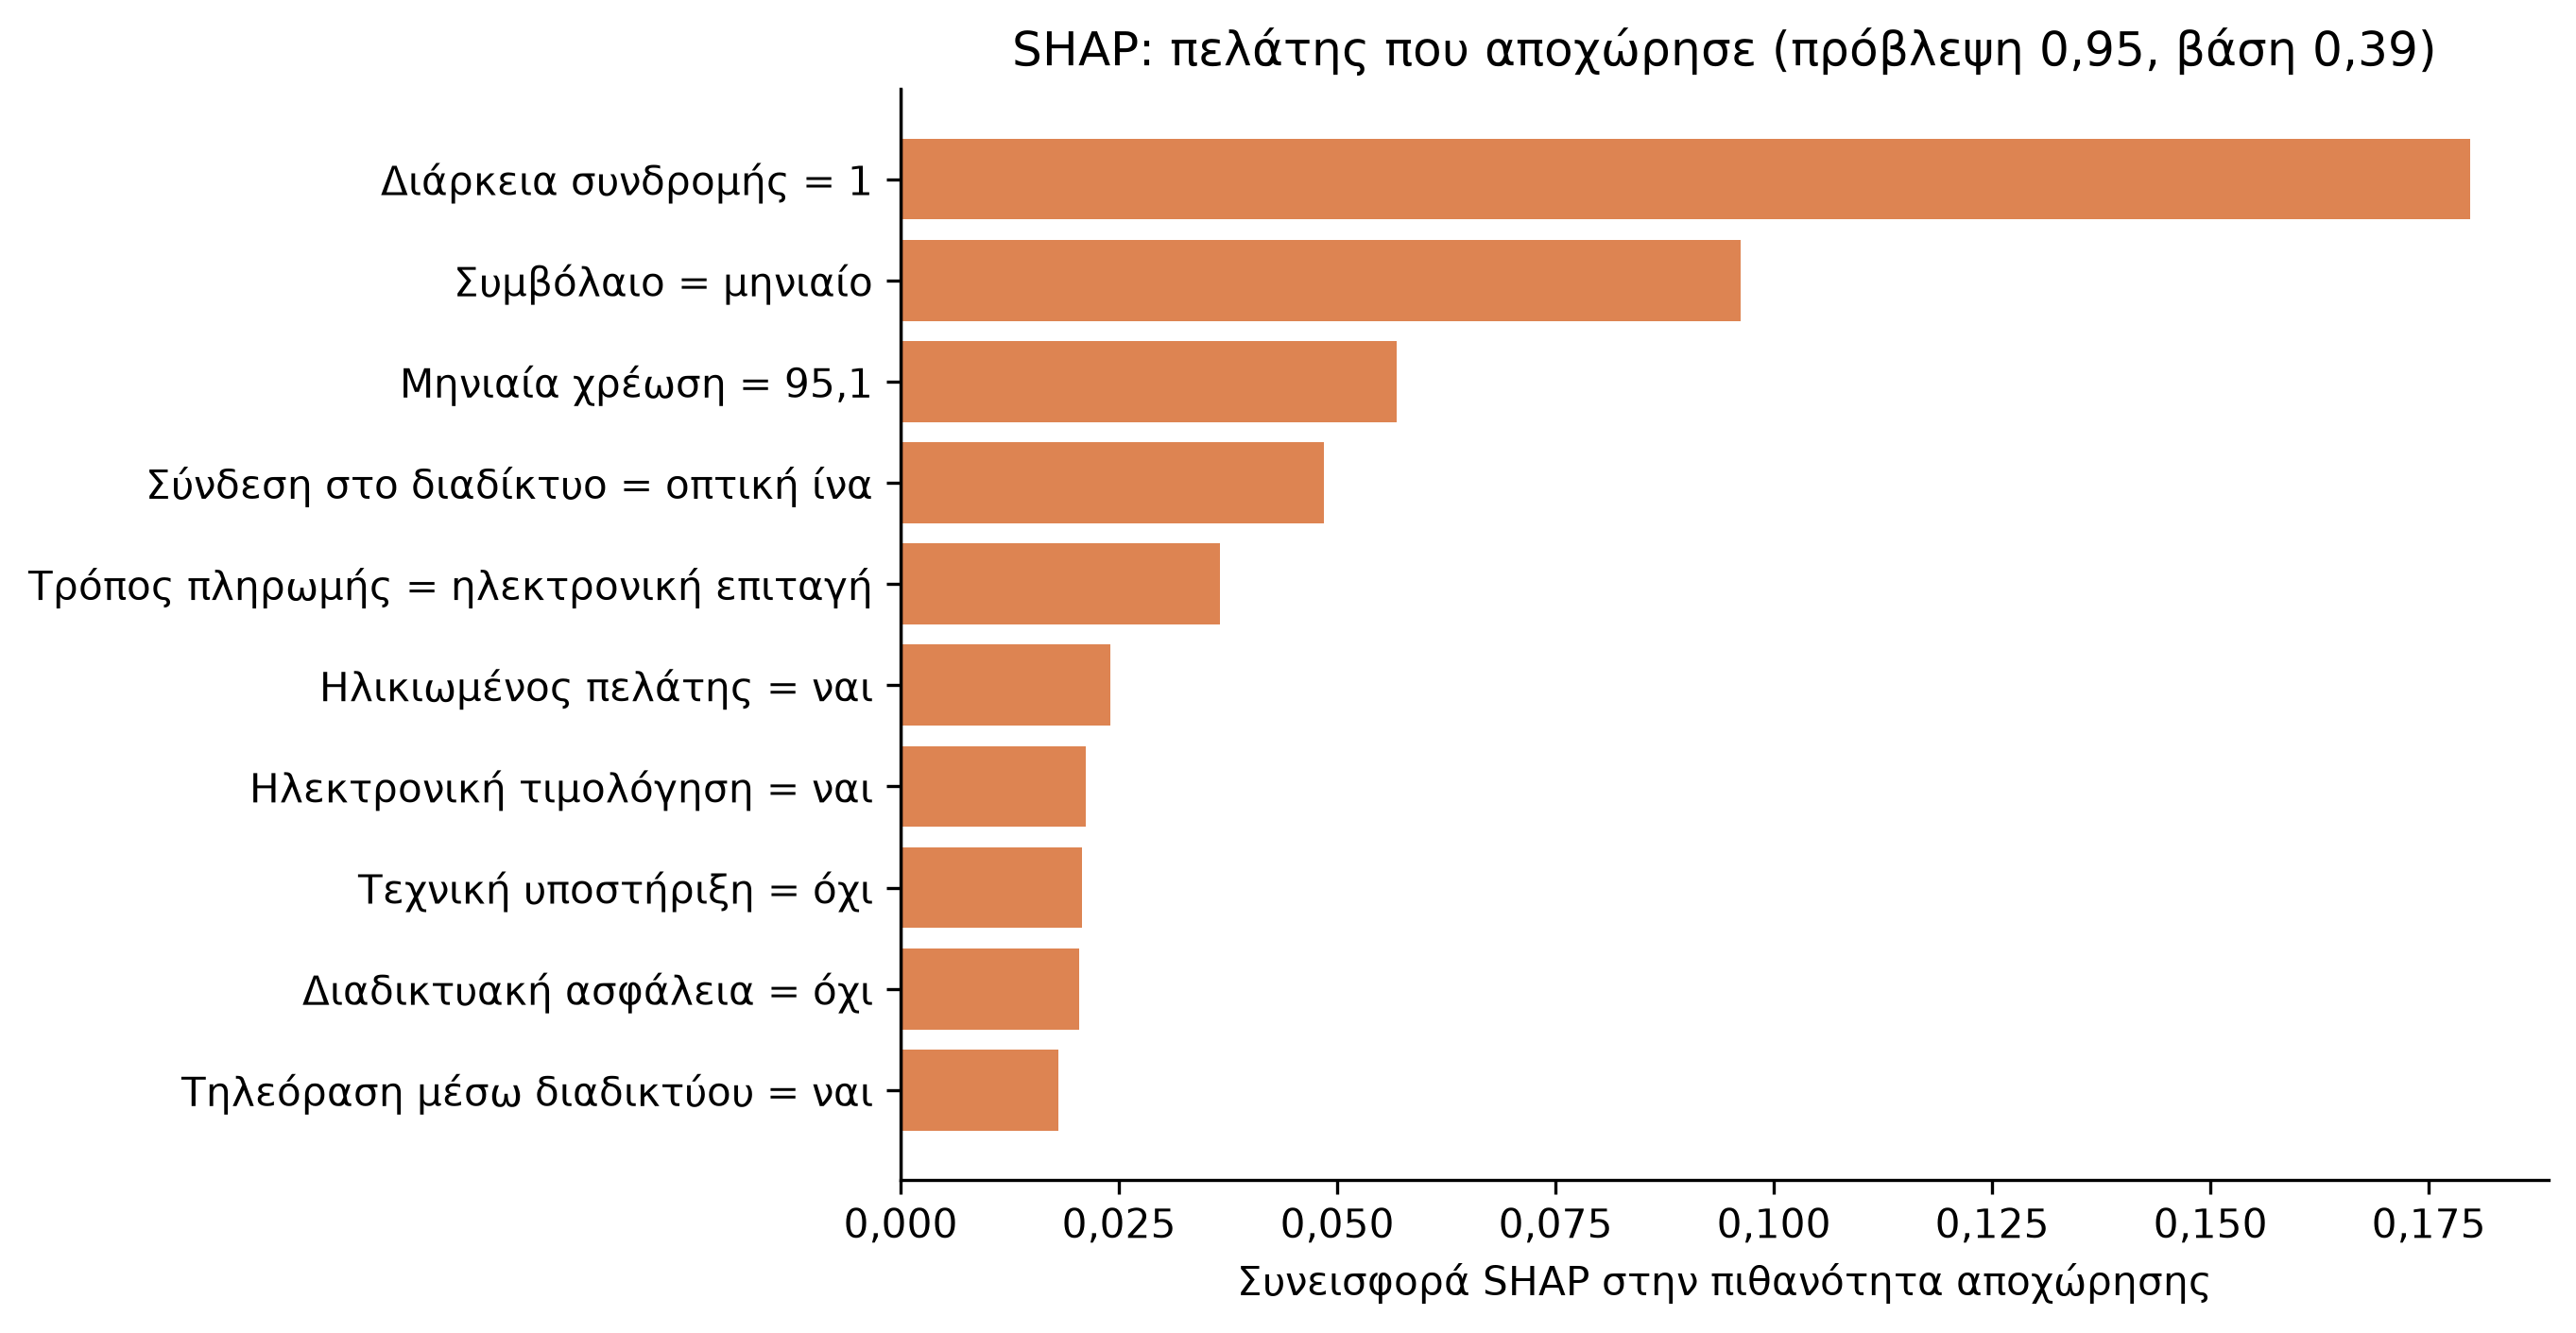

In [42]:
Image(filename=str(FIGURES / "shap_nn_local_churner.png"), width=850)

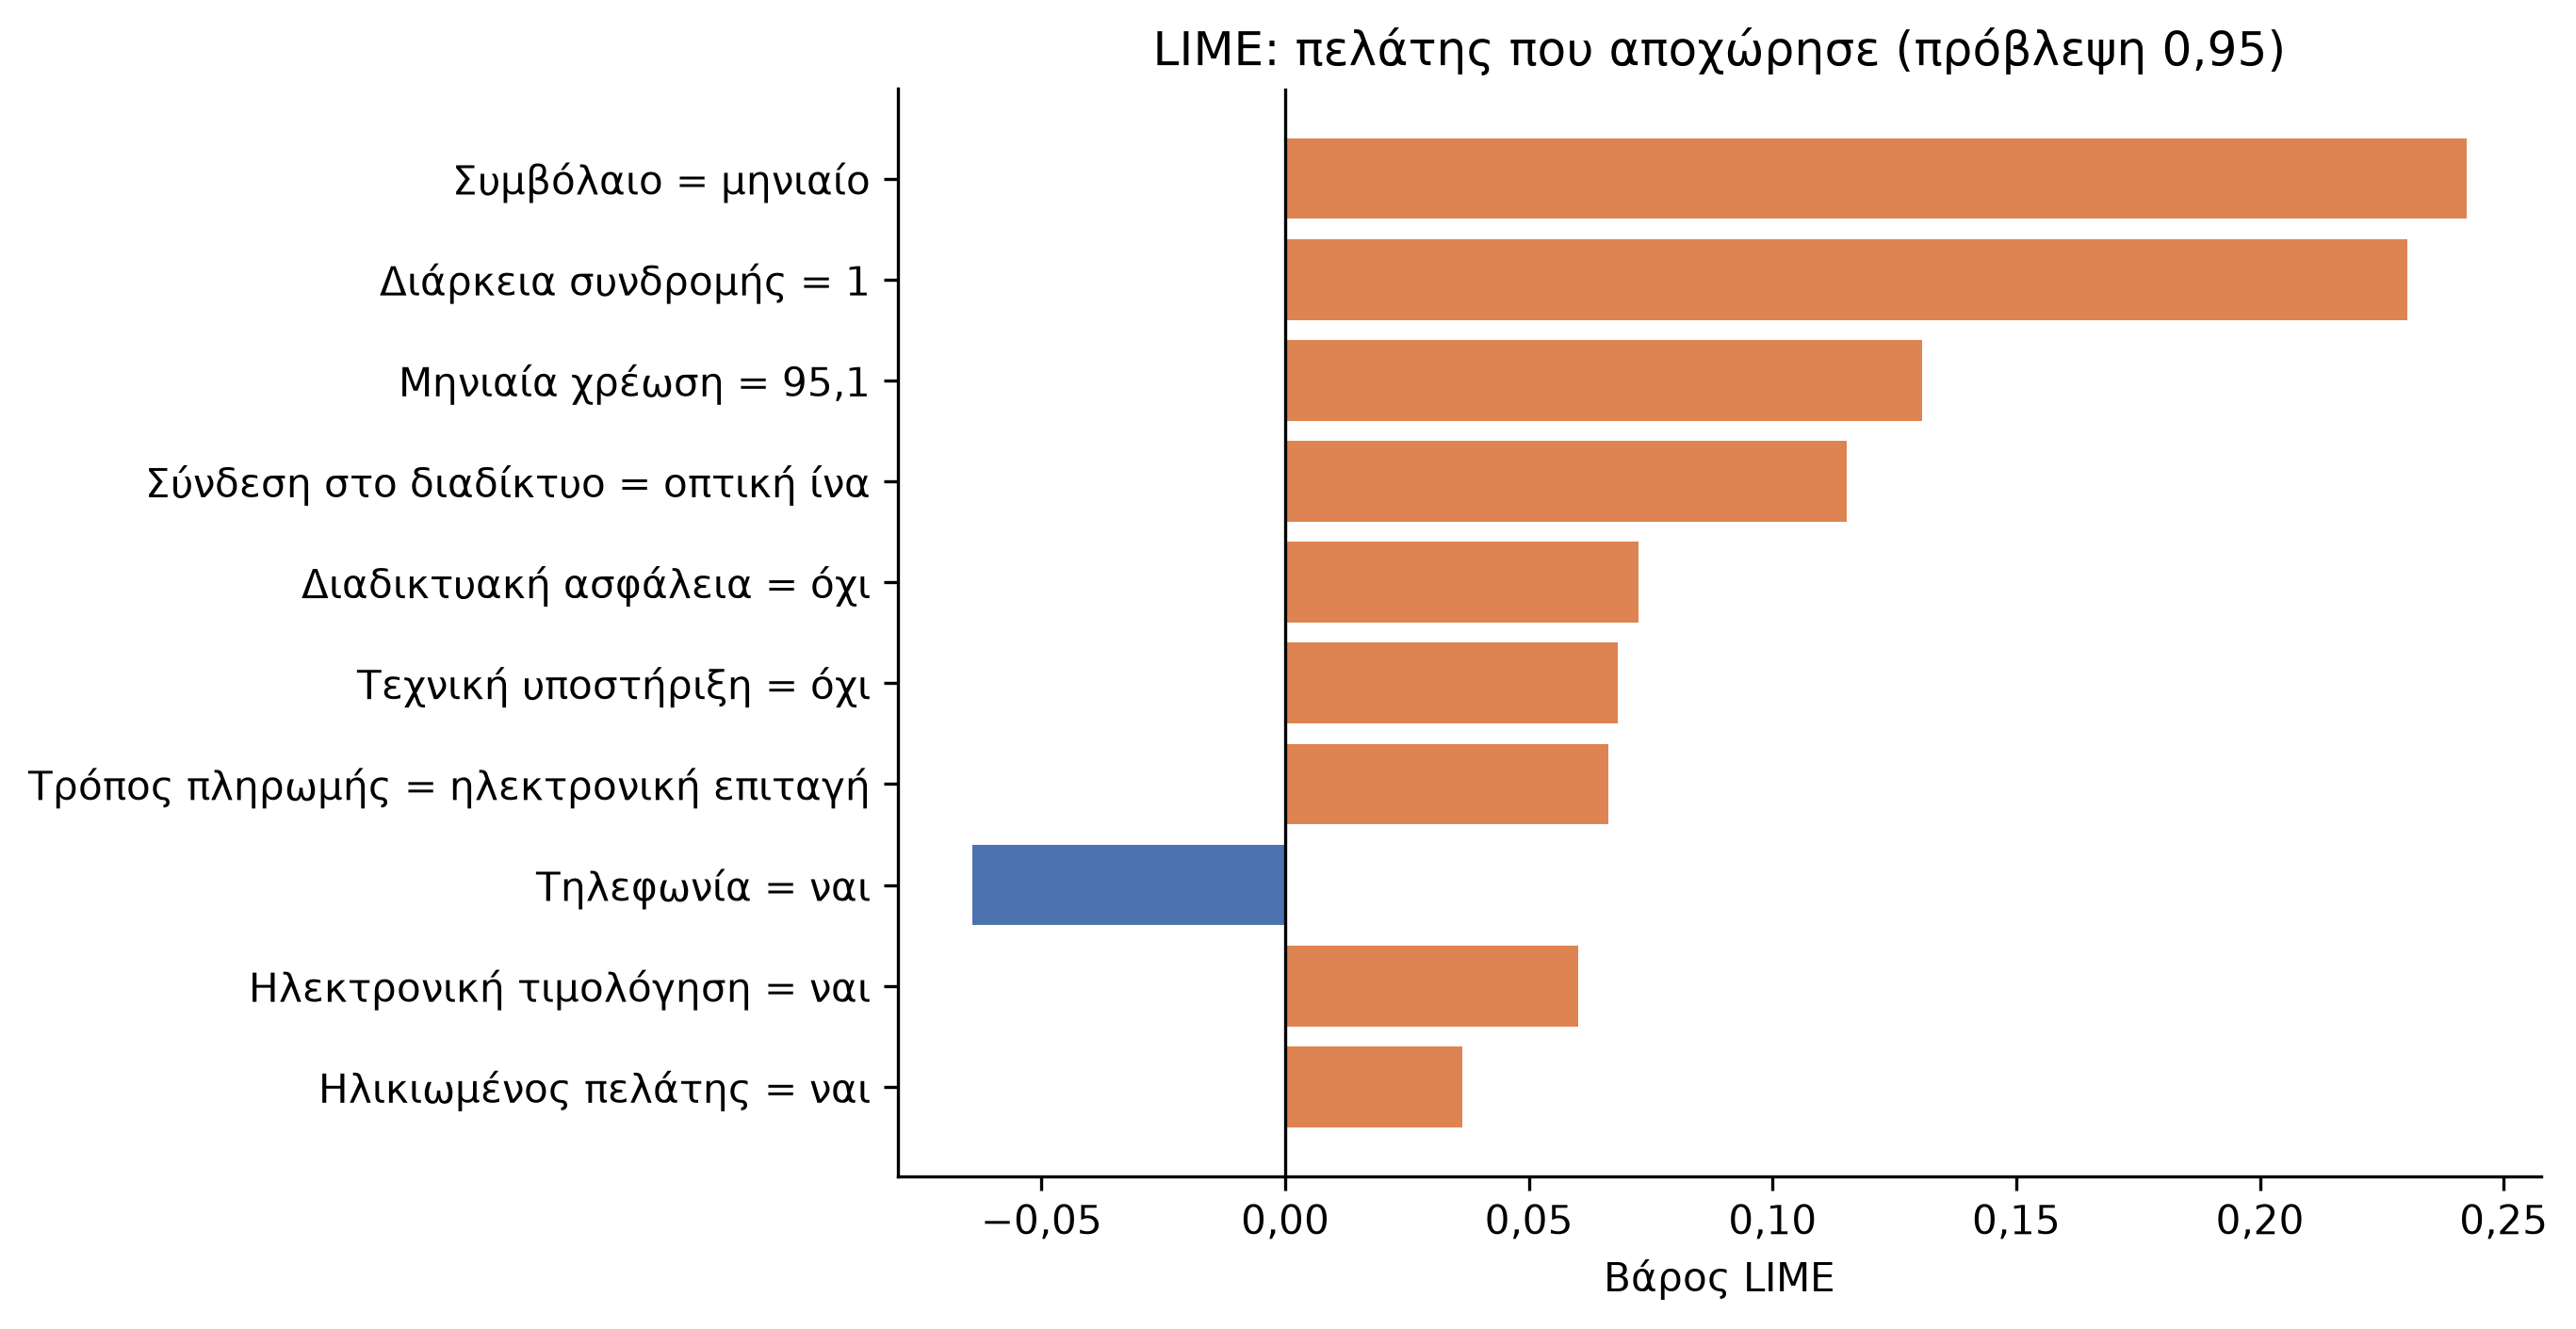

In [43]:
Image(filename=str(FIGURES / "lime_nn_local_churner.png"), width=850)

## 4. Σύγκριση μοντέλων και επιχειρηματική ανάλυση
### 4.1 Όλα τα μοντέλα στο test set
Μετρικές στο threshold που επιλέχθηκε στο validation, με διαστήματα εμπιστοσύνης 95% (bootstrap).

In [44]:
pd.read_csv(TABLES / "final_comparison.csv").query("threshold_type == 'tuned'").sort_values("roc_auc", ascending=False)

,model,Μοντέλο,threshold_type,threshold,accuracy,precision,recall,f1,roc_auc,pr_auc,tn,fp,fn,tp,roc_auc_ci_low,roc_auc_ci_high,f1_ci_low,f1_ci_high
9,xgb,XGBoost,tuned,0.54,0.7588,0.5298,0.7929,0.6352,0.8540,0.6739,580,197,58,222,0.8306,0.8771,0.5950,0.6730
13,catboost,CatBoost,tuned,0.51,0.7512,0.5191,0.8250,0.6372,0.8529,0.6728,563,214,49,231,0.8294,0.8759,0.5966,0.6748
11,lgbm,LightGBM,tuned,0.62,0.7852,0.5768,0.7107,0.6368,0.8511,0.6630,631,146,81,199,0.8271,0.8741,0.5918,0.6773
7,rf,Random Forest,tuned,0.56,0.7767,0.5579,0.7571,0.6424,0.8507,0.6535,609,168,68,212,0.8269,0.8731,0.5991,0.6816
5,mlp_tuned,Τελικό MLP,tuned,0.51,0.7512,0.5197,0.8000,0.6301,0.8482,0.6392,570,207,56,224,0.8242,0.8712,0.5874,0.6675
3,mlp_simple,Απλό MLP,tuned,0.62,0.7692,0.5497,0.7107,0.6199,0.8463,0.6255,614,163,81,199,0.8219,0.8695,0.5748,0.6596
1,logreg,Logistic Regression,tuned,0.58,0.7673,0.5457,0.7250,0.6227,0.8457,0.6415,608,169,77,203,0.8217,0.8690,0.5776,0.6636
15,svm,SVM,tuned,0.47,0.7625,0.5383,0.7286,0.6191,0.8400,0.6389,602,175,76,204,0.8148,0.8650,0.5737,0.6595
17,knn,k-NN,tuned,0.38,0.7616,0.5361,0.7429,0.6228,0.8345,0.6081,597,180,72,208,0.8082,0.8581,0.5754,0.6626
19,nb,Naive Bayes,tuned,0.76,0.7663,0.5450,0.7143,0.6182,0.8282,0.5904,610,167,80,200,0.8018,0.8521,0.5714,0.6587


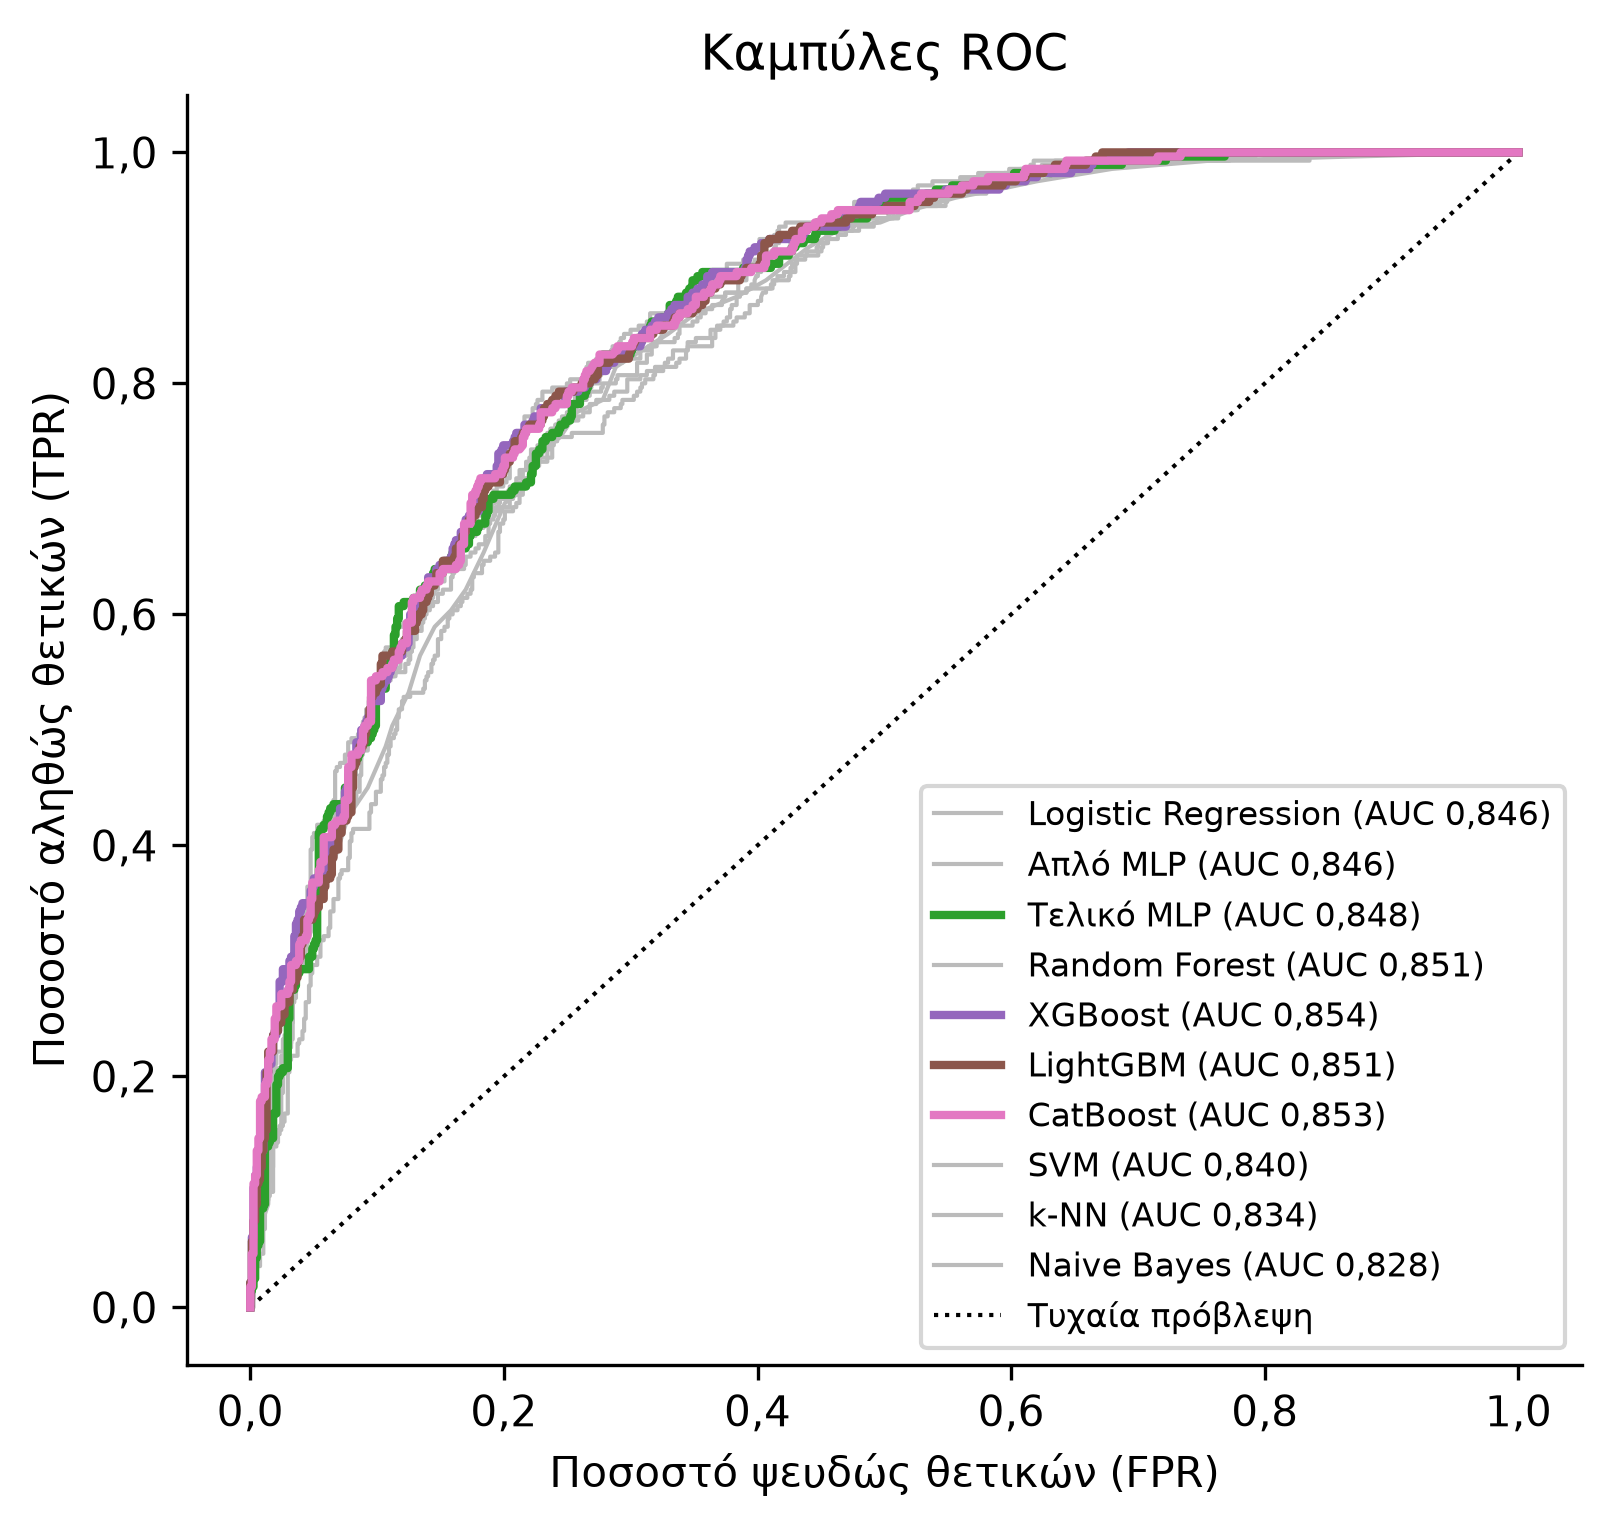

In [45]:
Image(filename=str(FIGURES / "roc_all_models.png"), width=850)

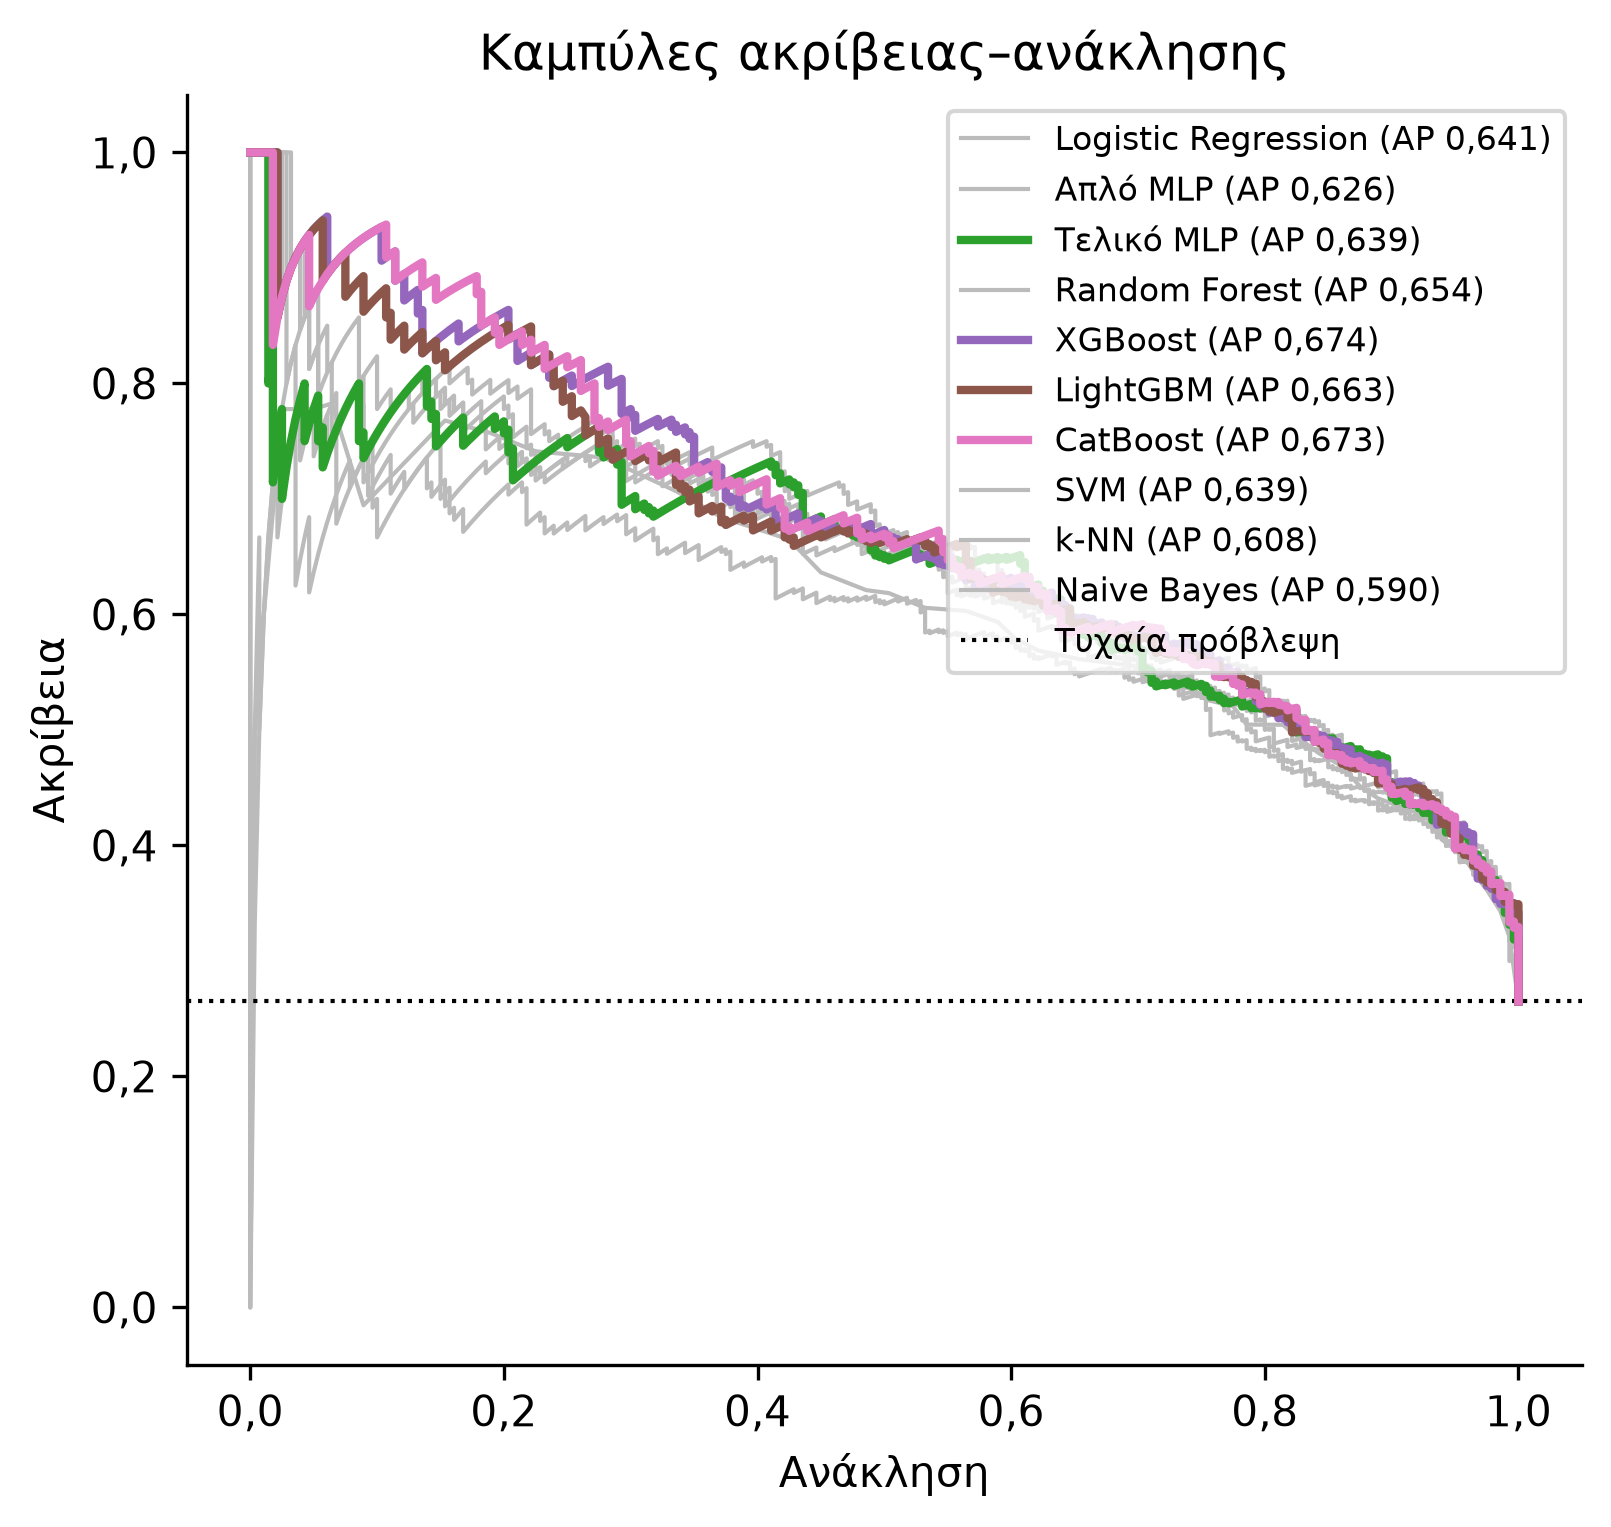

In [46]:
Image(filename=str(FIGURES / "pr_all_models.png"), width=850)

### 4.2 Στατιστική σύγκριση ανά ζεύγος
Paired bootstrap της διαφοράς ROC-AUC στους ίδιους πελάτες, με διόρθωση Holm για πολλαπλές συγκρίσεις.

In [47]:
pd.read_csv(TABLES / "paired_comparison.csv")

,family,model_a,model_b,delta_auc,ci_low,ci_high,p_value,p_holm,significant_at_0.05
0,vs_mlp_tuned,logreg,mlp_tuned,-0.0025,-0.0078,0.0029,0.344,1.000,False
1,vs_mlp_tuned,mlp_simple,mlp_tuned,-0.0018,-0.0070,0.0031,0.449,1.000,False
2,vs_mlp_tuned,rf,mlp_tuned,0.0025,-0.0036,0.0092,0.465,1.000,False
3,vs_mlp_tuned,xgb,mlp_tuned,0.0058,-0.0000,0.0114,0.051,0.306,False
4,vs_mlp_tuned,lgbm,mlp_tuned,0.0030,-0.0029,0.0088,0.329,1.000,False
5,vs_mlp_tuned,catboost,mlp_tuned,0.0047,-0.0006,0.0103,0.081,0.405,False
6,vs_mlp_tuned,svm,mlp_tuned,-0.0082,-0.0150,-0.0014,0.016,0.112,False
7,vs_mlp_tuned,knn,mlp_tuned,-0.0137,-0.0217,-0.0054,0.000,0.000,True
8,vs_mlp_tuned,nb,mlp_tuned,-0.0199,-0.0299,-0.0108,0.000,0.000,True
9,vs_best_xgb,logreg,xgb,-0.0083,-0.0147,-0.0020,0.013,0.078,False


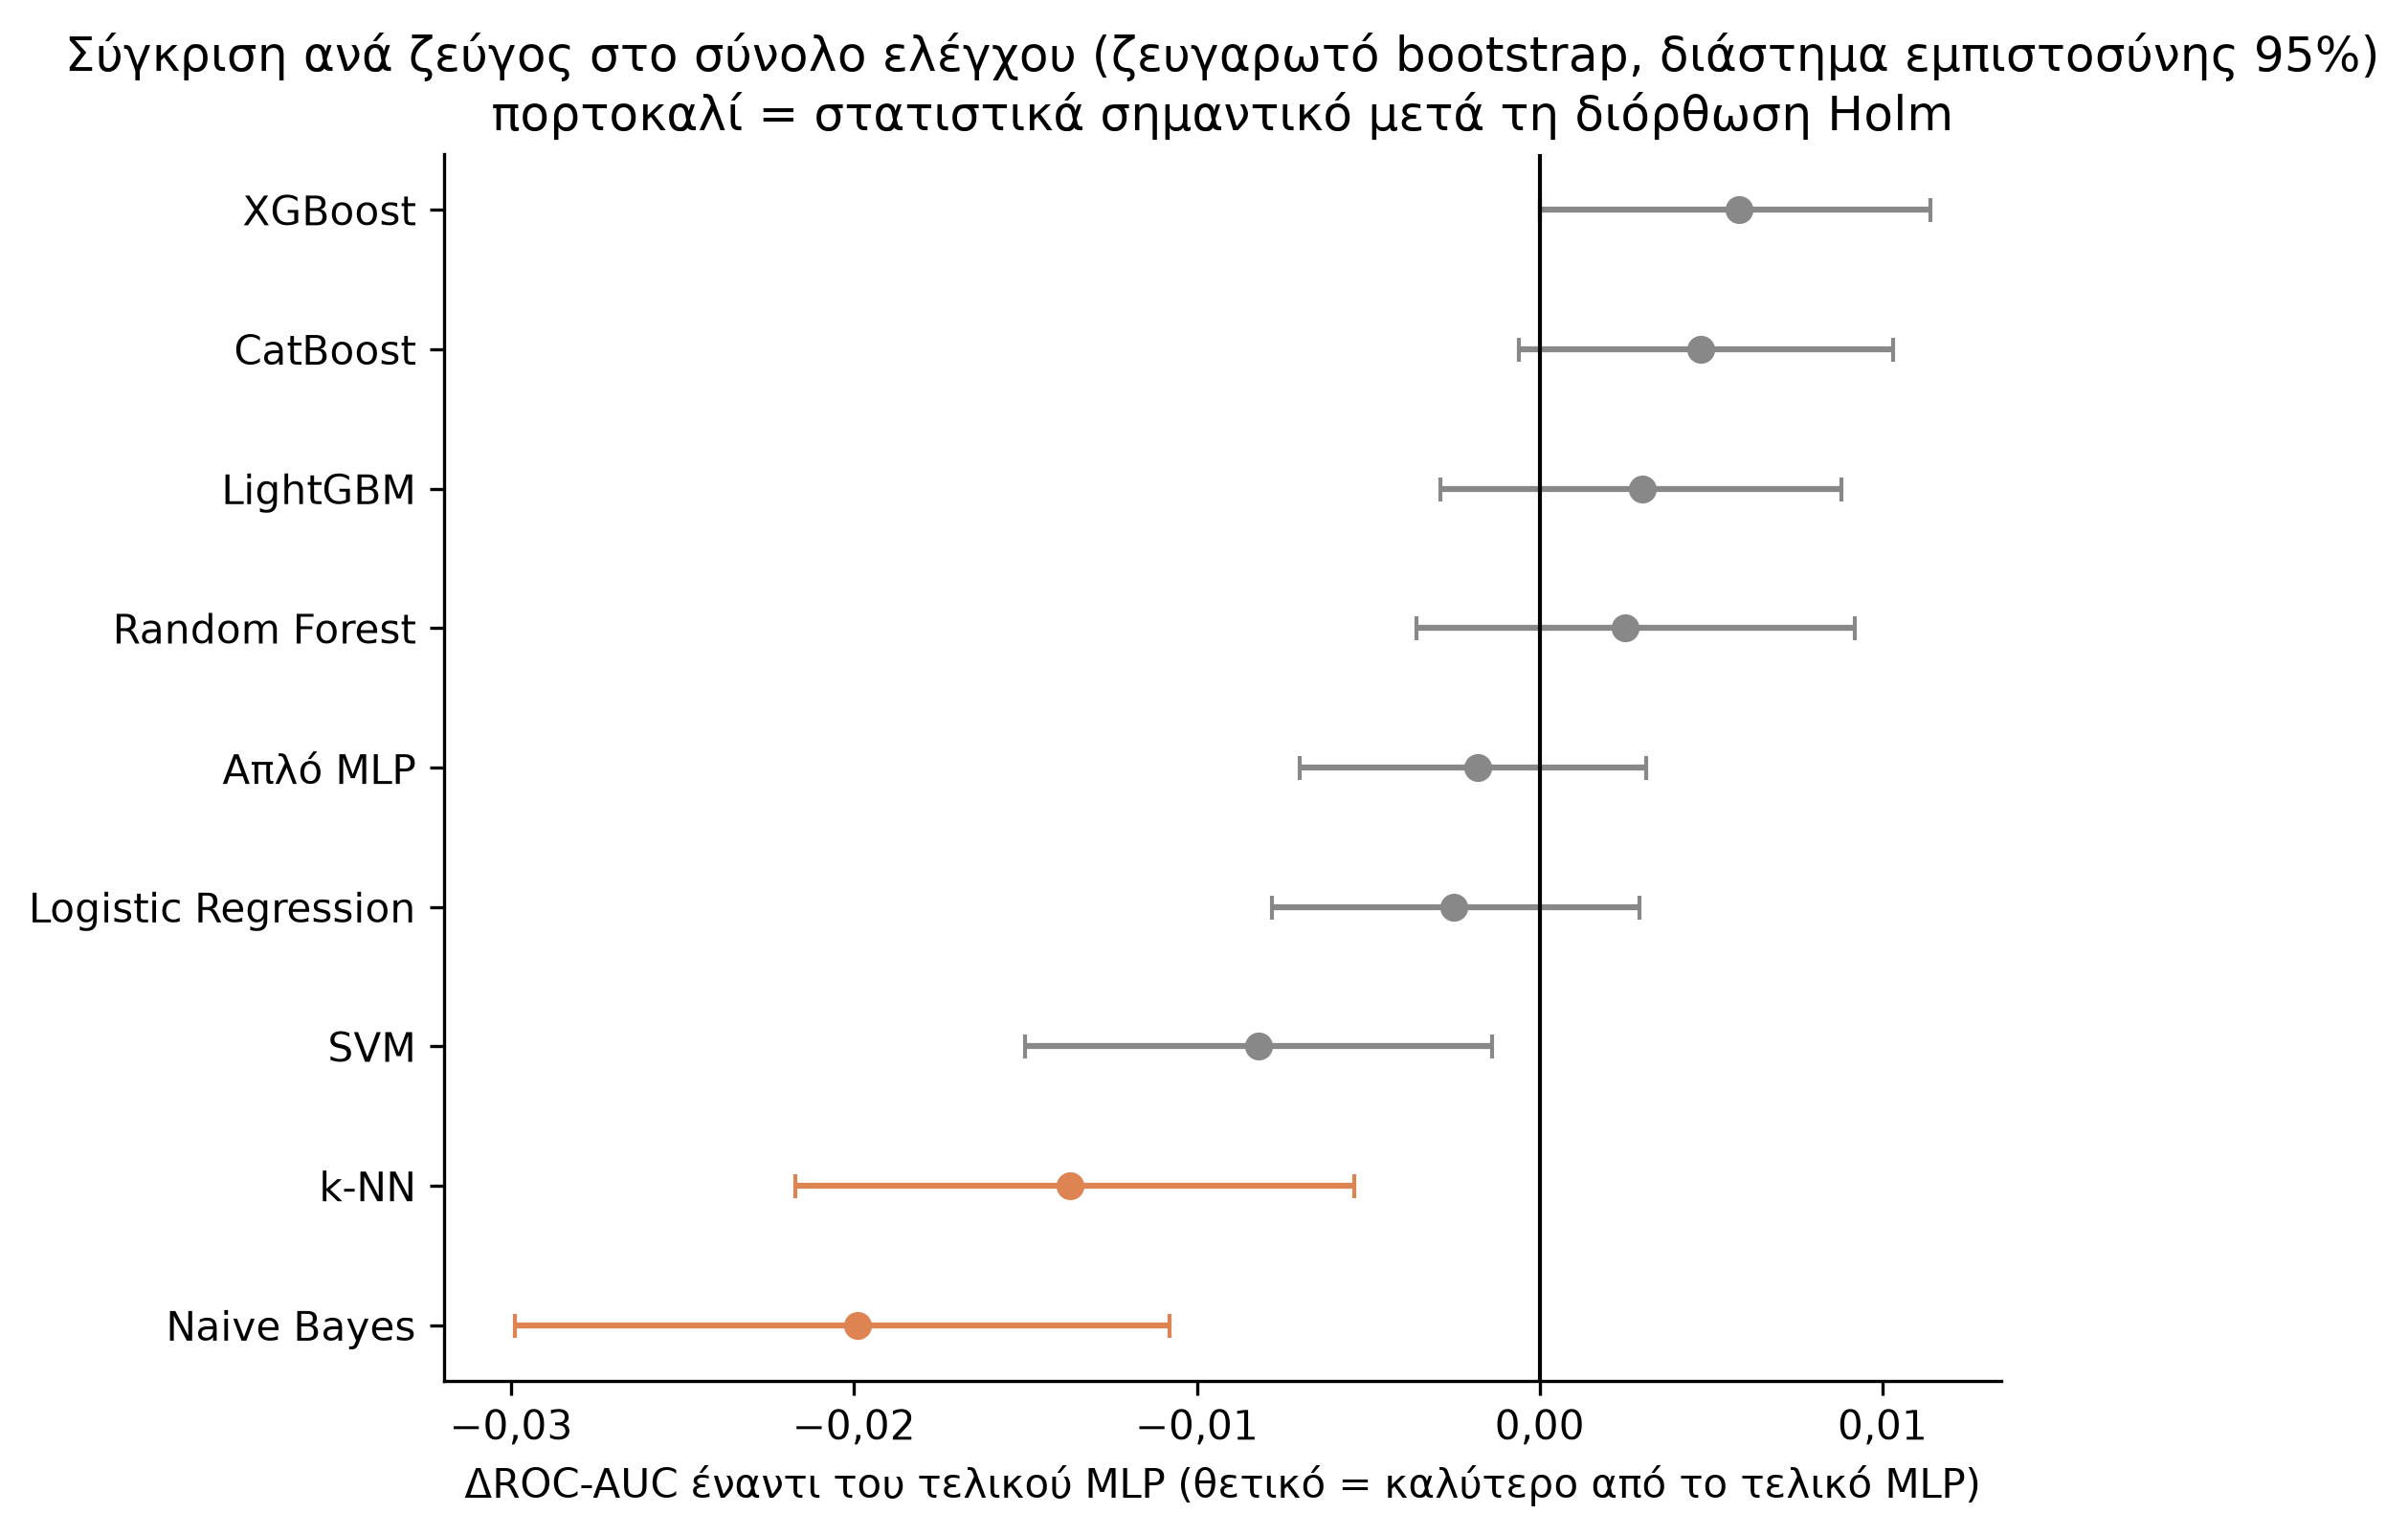

In [48]:
Image(filename=str(FIGURES / "paired_delta_auc.png"), width=850)

### 4.3 Βαθμονόμηση πιθανοτήτων
Platt scaling στο validation: η κατάταξη δεν αλλάζει, οι πιθανότητες γίνονται συγκρίσιμες με τα πραγματικά ποσοστά.

In [49]:
pd.read_csv(TABLES / "calibration.csv")

,model,Μοντέλο,brier_raw,brier_calibrated,ece_raw,ece_calibrated,mean_prob_raw,mean_prob_calibrated,actual_rate
0,logreg,Logistic Regression,0.1679,0.1373,0.1564,0.0291,0.4213,0.2730,0.2649
1,mlp_simple,Απλό MLP,0.1706,0.1370,0.1603,0.0388,0.4252,0.2741,0.2649
2,mlp_tuned,Τελικό MLP,0.1643,0.1359,0.1461,0.0182,0.4110,0.2733,0.2649
3,rf,Random Forest,0.1611,0.1346,0.1456,0.0235,0.4105,0.2724,0.2649
4,xgb,XGBoost,0.1620,0.1329,0.1470,0.0202,0.4119,0.2741,0.2649
5,lgbm,LightGBM,0.1637,0.1346,0.1524,0.0271,0.4173,0.2748,0.2649
6,catboost,CatBoost,0.1634,0.1332,0.1503,0.0283,0.4152,0.2758,0.2649
7,svm,SVM,0.1510,0.1510,0.0696,0.0855,0.2762,0.2707,0.2649
8,knn,k-NN,0.1426,0.1418,0.0318,0.0230,0.2967,0.2735,0.2649
9,nb,Naive Bayes,0.2151,0.1440,0.2010,0.0213,0.4148,0.2735,0.2649


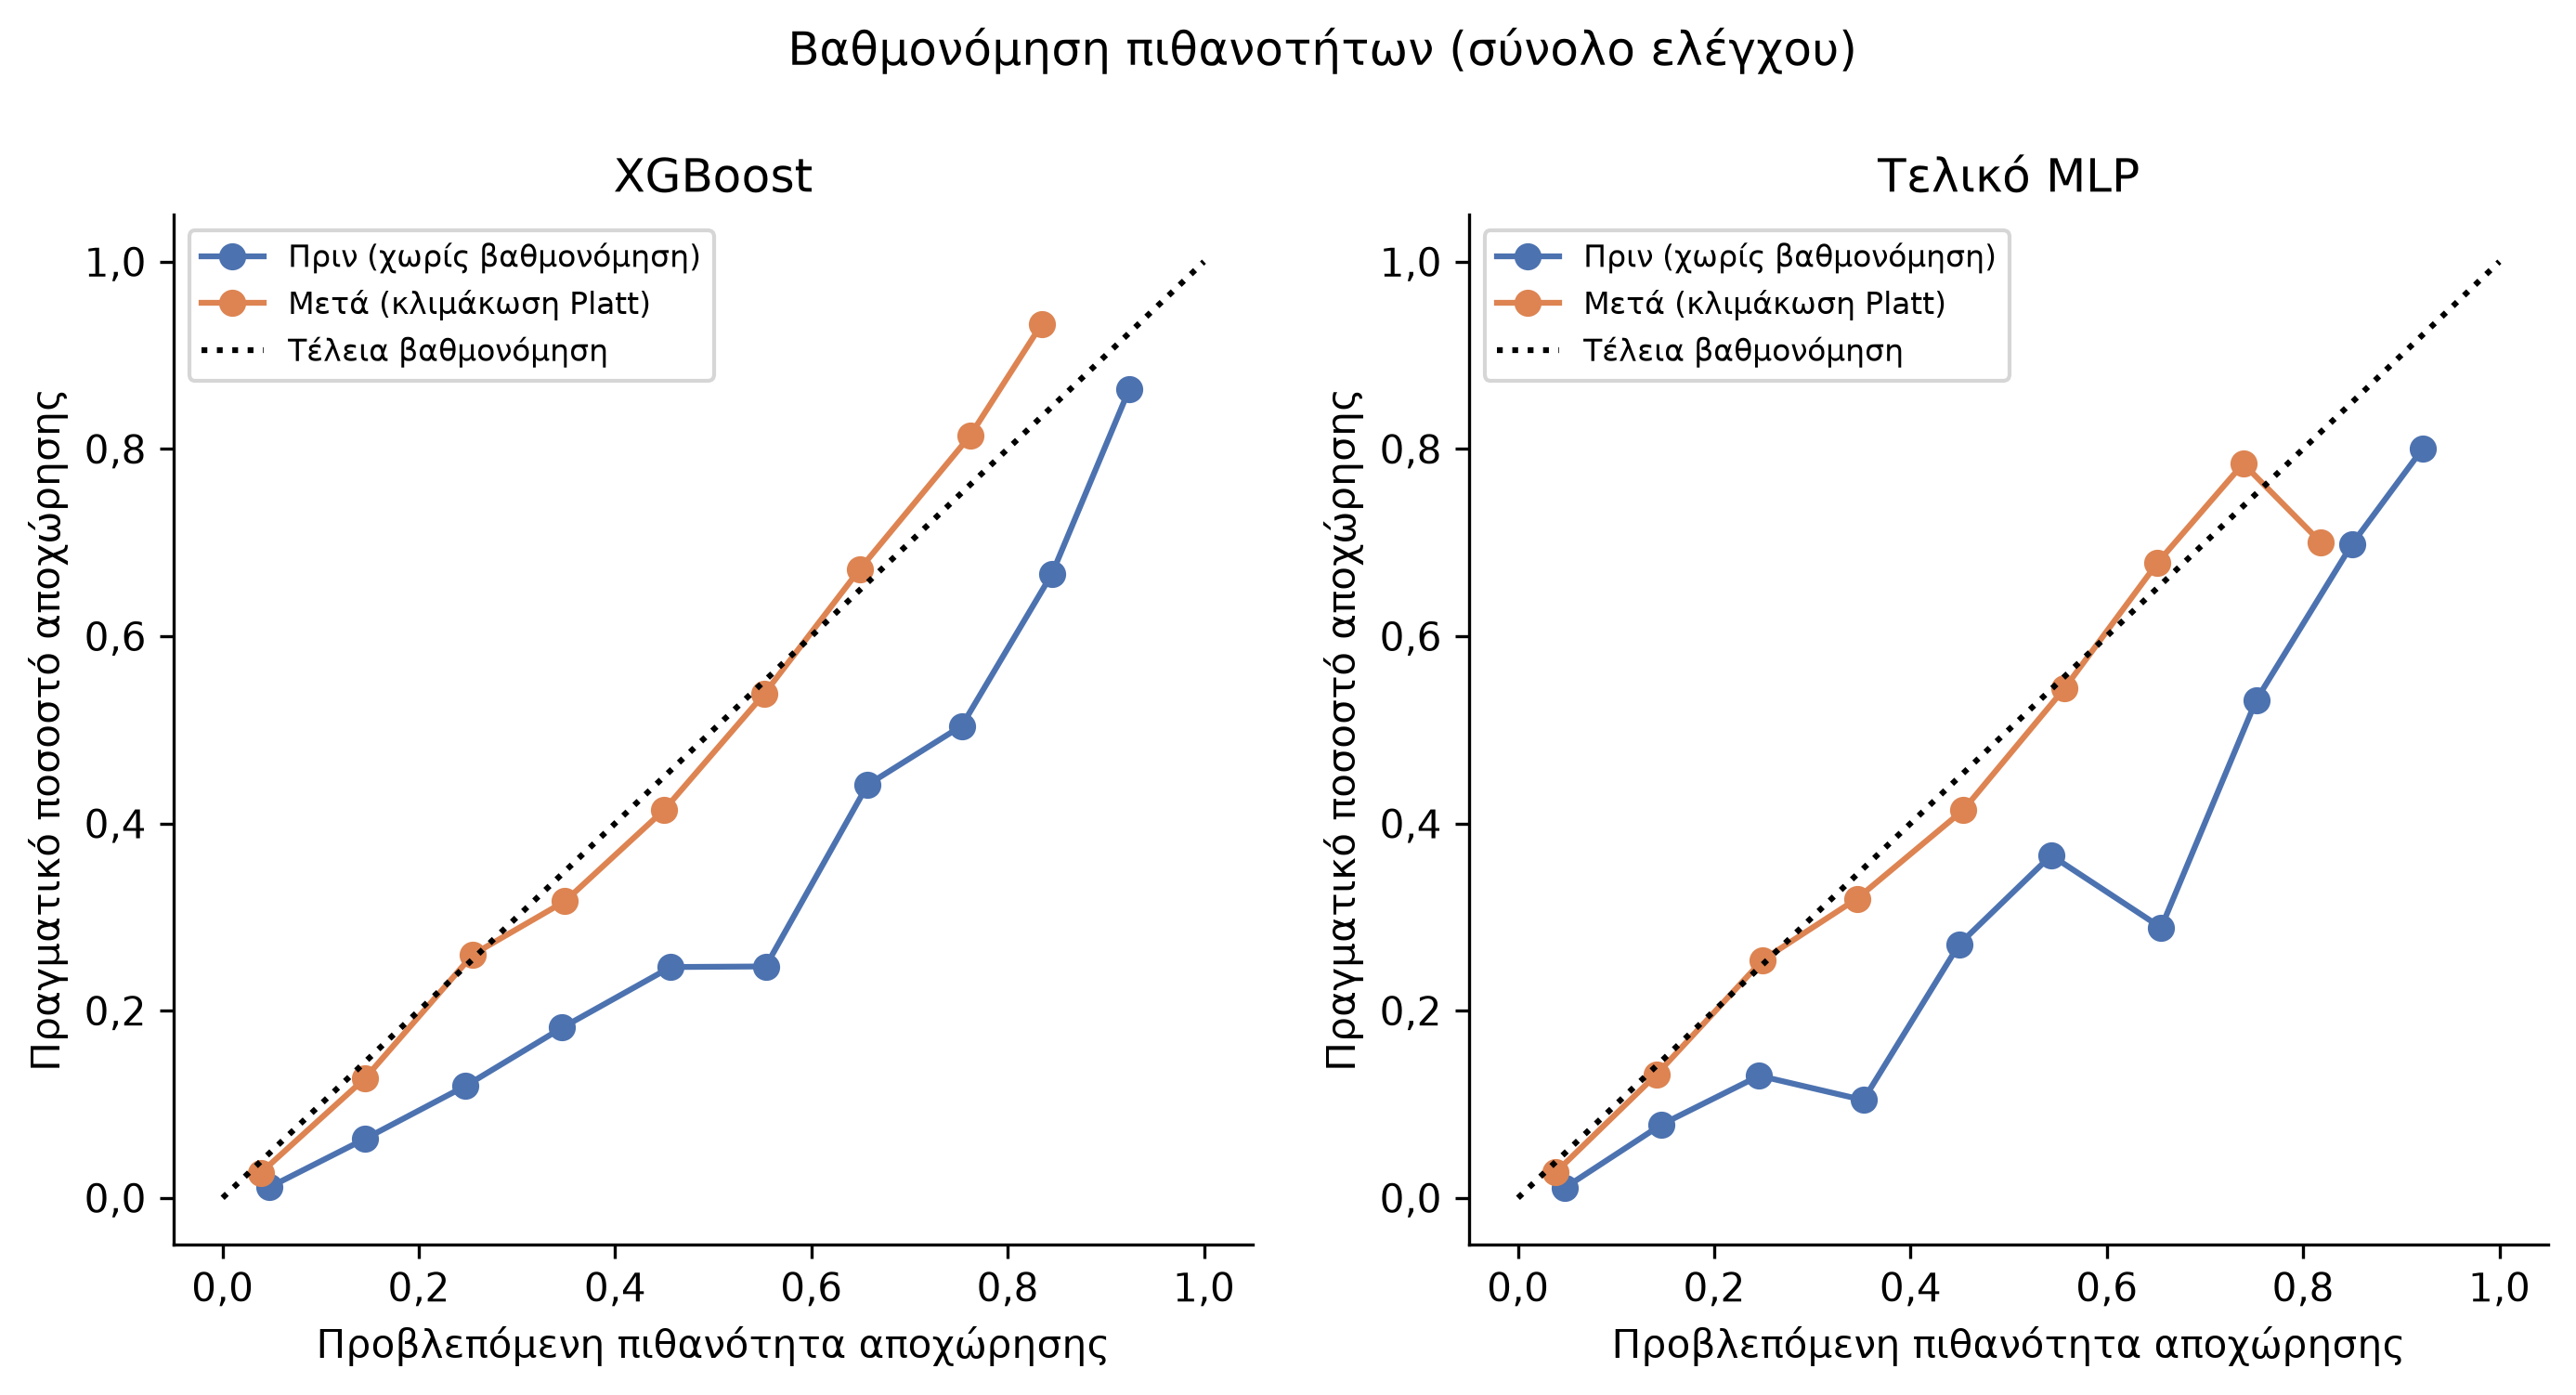

In [50]:
Image(filename=str(FIGURES / "calibration.png"), width=850)

### 4.4 Πίνακας σύγχυσης και είδη λαθών

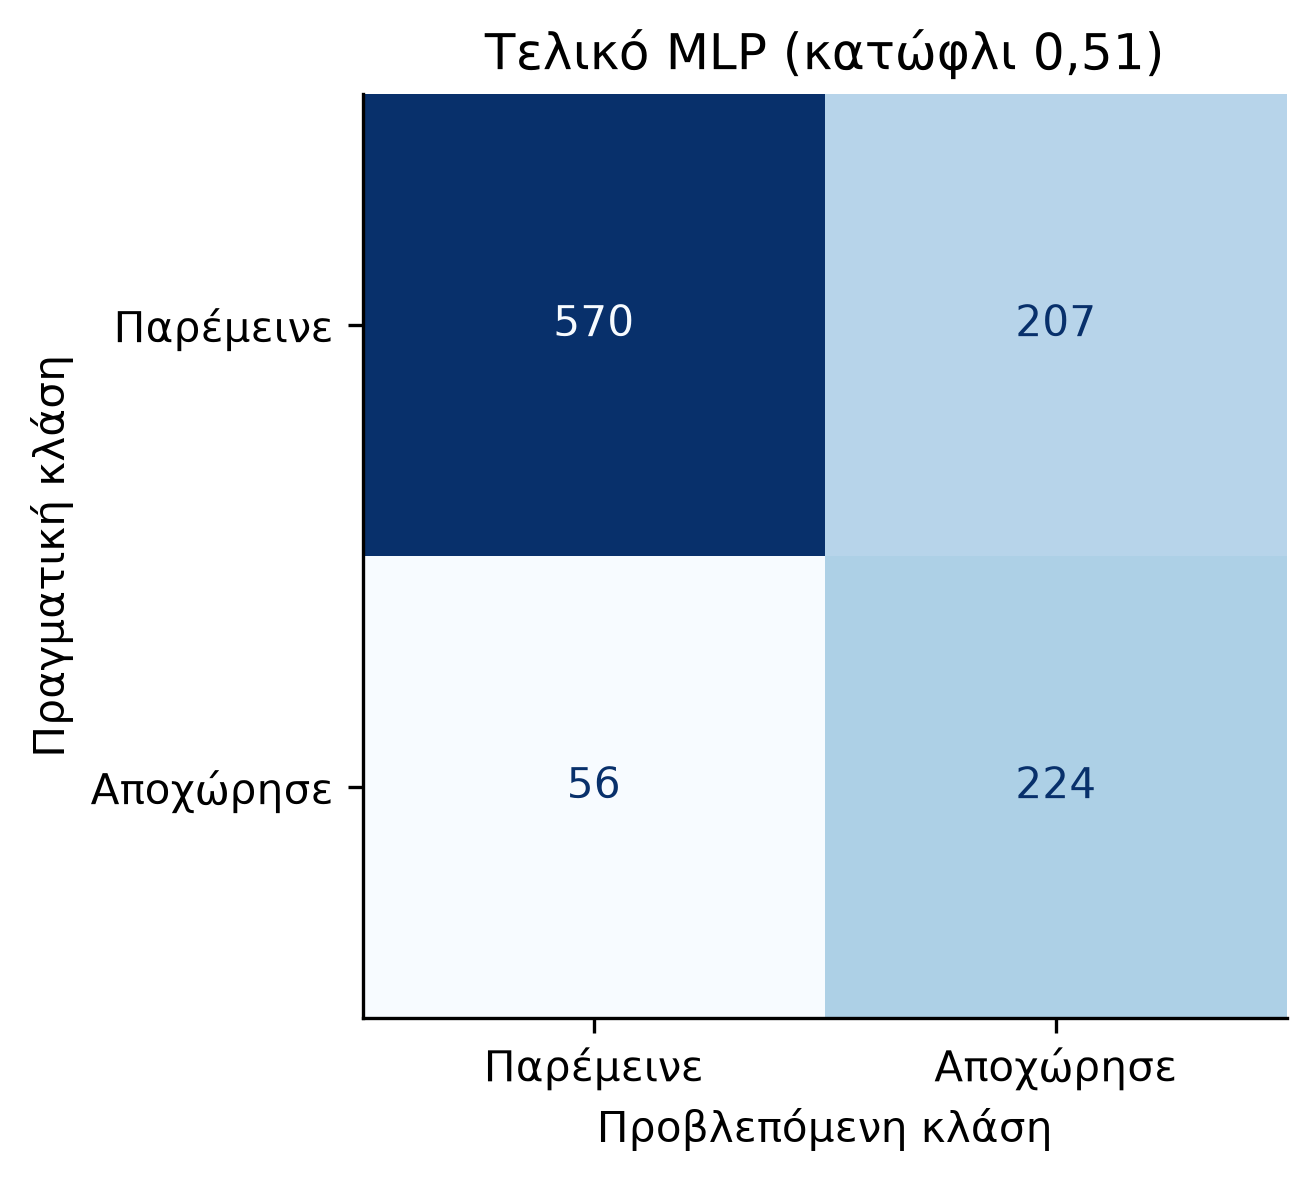

In [51]:
Image(filename=str(FIGURES / "cm_mlp_tuned.png"), width=850)

In [52]:
pd.read_csv(TABLES / "error_profile.csv")

,model,Ομάδα,Πλήθος,Μέση διάρκεια συνδρομής (μήνες),Μέση μηνιαία χρέωση,Συχνότερο συμβόλαιο,Μερίδιο μηνιαίων συμβολαίων,Συχνότερος τρόπος πληρωμής,Μερίδιο οπτικής ίνας
0,xgb,TP (σωστά εντοπισμένες αποχωρήσεις),222,12.4144,75.6818,μηνιαίο,0.9910,ηλεκτρονική επιταγή,0.7838
1,xgb,FN (αποχωρήσεις που δεν εντοπίστηκαν),58,32.3621,67.4086,μηνιαίο,0.4655,ταχυδρομική επιταγή,0.4138
2,xgb,FP (λανθασμένες προβλέψεις αποχώρησης),197,18.8426,76.1178,μηνιαίο,0.9695,ηλεκτρονική επιταγή,0.7107
3,xgb,TN (σωστά «παραμένει»),580,44.3621,57.3004,διετές,0.2500,τραπεζική μεταφορά (αυτόματη),0.2448
4,mlp_tuned,TP (σωστά εντοπισμένες αποχωρήσεις),224,12.8527,76.2567,μηνιαίο,0.9732,ηλεκτρονική επιταγή,0.7902
5,mlp_tuned,FN (αποχωρήσεις που δεν εντοπίστηκαν),56,31.3214,64.8134,μηνιαίο,0.5179,ταχυδρομική επιταγή,0.3750
6,mlp_tuned,FP (λανθασμένες προβλέψεις αποχώρησης),207,17.8261,75.0722,μηνιαίο,0.9565,ηλεκτρονική επιταγή,0.6715
7,mlp_tuned,TN (σωστά «παραμένει»),570,45.1789,57.3500,διετές,0.2421,τραπεζική μεταφορά (αυτόματη),0.2509


### 4.5 Ποια χαρακτηριστικά οδηγούν στην αποχώρηση

In [53]:
pd.read_csv(TABLES / "importance_comparison.csv")

,feature,NN SHAP,NN LIME,XGB SHAP,LogReg |συντελεστές|
0,tenure,1.0,2.0,2.0,2.0
1,Contract,2.0,1.0,1.0,1.0
2,MonthlyCharges,3.0,3.0,4.0,3.0
3,InternetService,4.0,4.0,3.0,5.0
4,PaymentMethod,5.0,10.0,5.0,8.0
5,OnlineSecurity,6.0,6.0,8.0,7.0
6,TechSupport,7.0,5.0,9.0,6.0
7,PaperlessBilling,8.0,8.0,6.0,9.0
8,StreamingMovies,9.0,11.0,7.0,13.0
9,OnlineBackup,10.0,13.0,12.0,11.0


In [54]:
pd.read_csv(TABLES / "shap_nn_by_category.csv")

,feature,category,mean_shap,n
0,tenure,"0–7,75",0.1815,125
1,tenure,"27,5–55",-0.0657,127
2,tenure,55–72,-0.1277,123
3,tenure,"7,75–27,5",0.0726,125
4,Contract,Month-to-month,0.1098,278
5,Contract,One year,-0.0738,101
6,Contract,Two year,-0.1430,121
7,MonthlyCharges,"18,7–41,3",-0.1124,125
8,MonthlyCharges,"41,3–70,67",-0.0214,125
9,MonthlyCharges,"70,67–89,81",0.0285,125


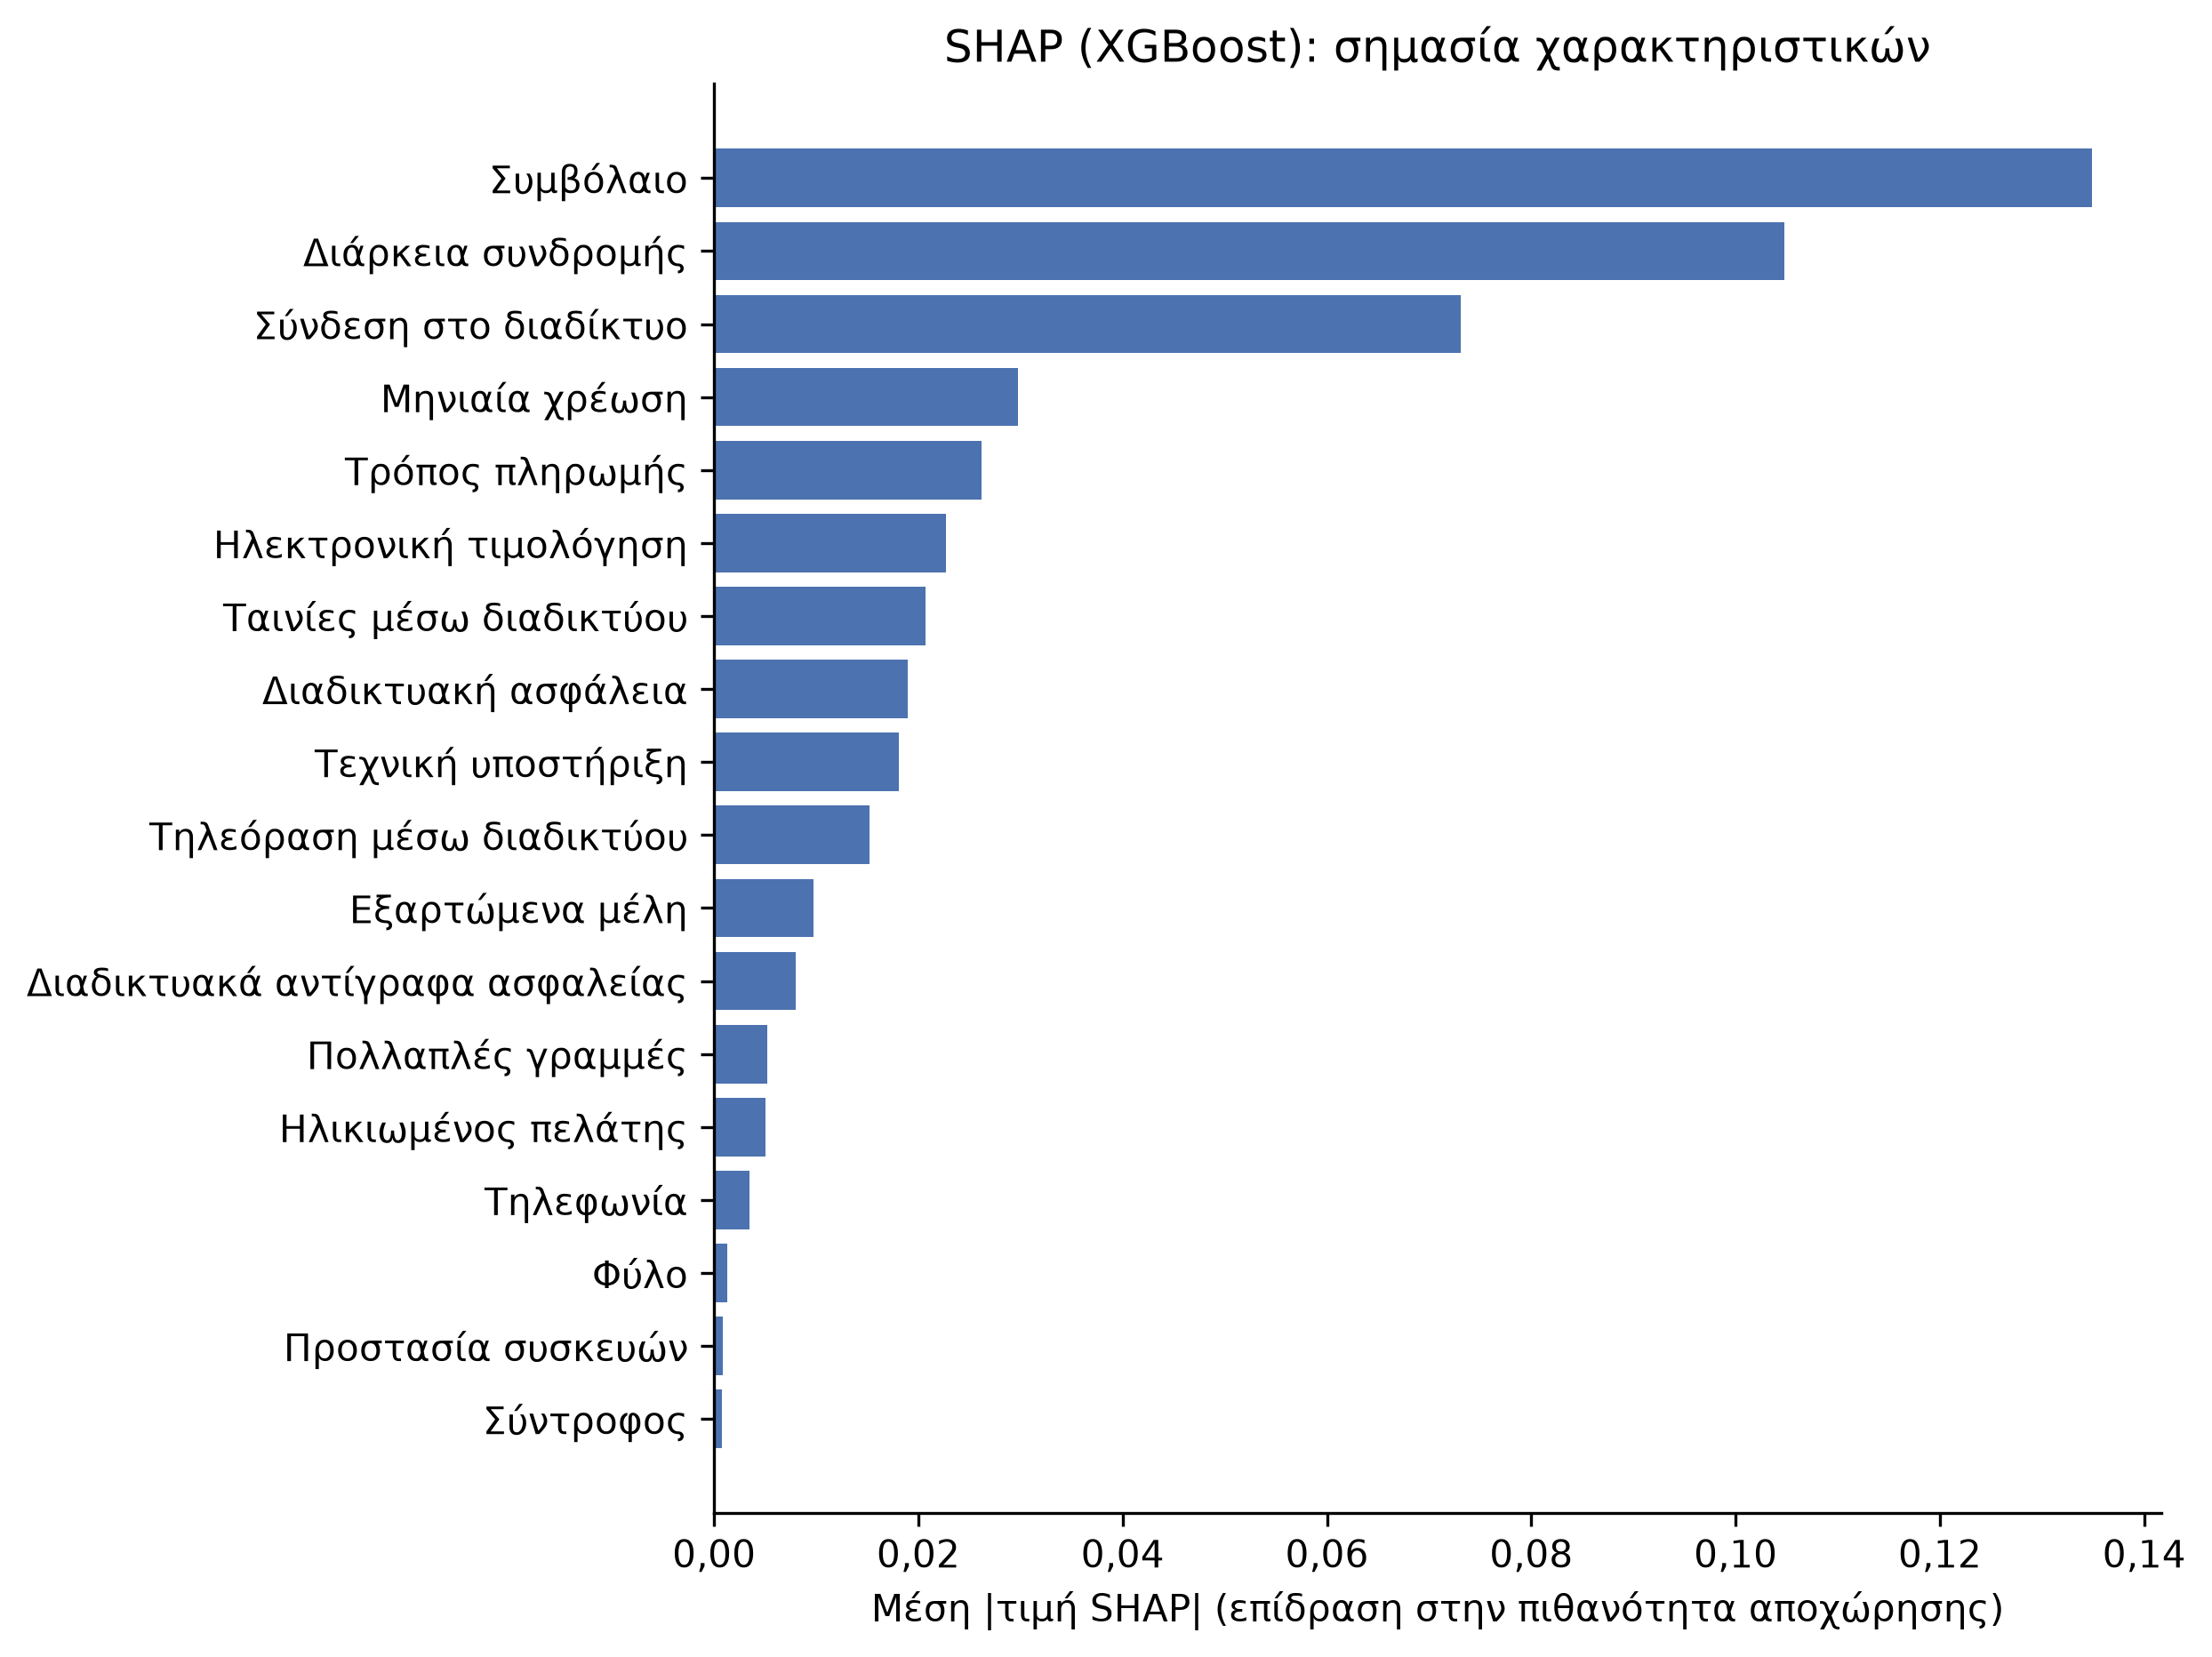

In [55]:
Image(filename=str(FIGURES / "shap_xgb_bar.png"), width=850)

### 4.6 Χρήση του μοντέλου από την εταιρεία
Χωρίς υποθέσεις για χρηματικά ποσά: η καμπάνια σε ένα k% πελατών είναι κερδοφόρα όταν
s·V/C > 1/precision@k, όπου η εταιρεία συμπληρώνει το κόστος C, την αξία V και την επιτυχία s.

In [56]:
pd.read_csv(TABLES / "lift_at_k.csv")

,model,k_percent,n_targeted,churners_caught,recall_at_k,precision_at_k,lift,required_sV_over_C
0,xgb,5,53,45,0.1607,0.8491,3.2052,1.1778
1,xgb,10,106,82,0.2929,0.7736,2.9203,1.2927
2,xgb,15,159,110,0.3929,0.6918,2.6116,1.4455
3,xgb,20,211,141,0.5036,0.6682,2.5226,1.4965
4,xgb,25,264,166,0.5929,0.6288,2.3737,1.5904
5,xgb,30,317,188,0.6714,0.5931,2.2388,1.6862
6,xgb,35,370,209,0.7464,0.5649,2.1324,1.7703
7,xgb,40,423,222,0.7929,0.5248,1.9812,1.9054
8,xgb,45,476,236,0.8429,0.4958,1.8716,2.0169
9,xgb,50,528,248,0.8857,0.4697,1.7731,2.1290


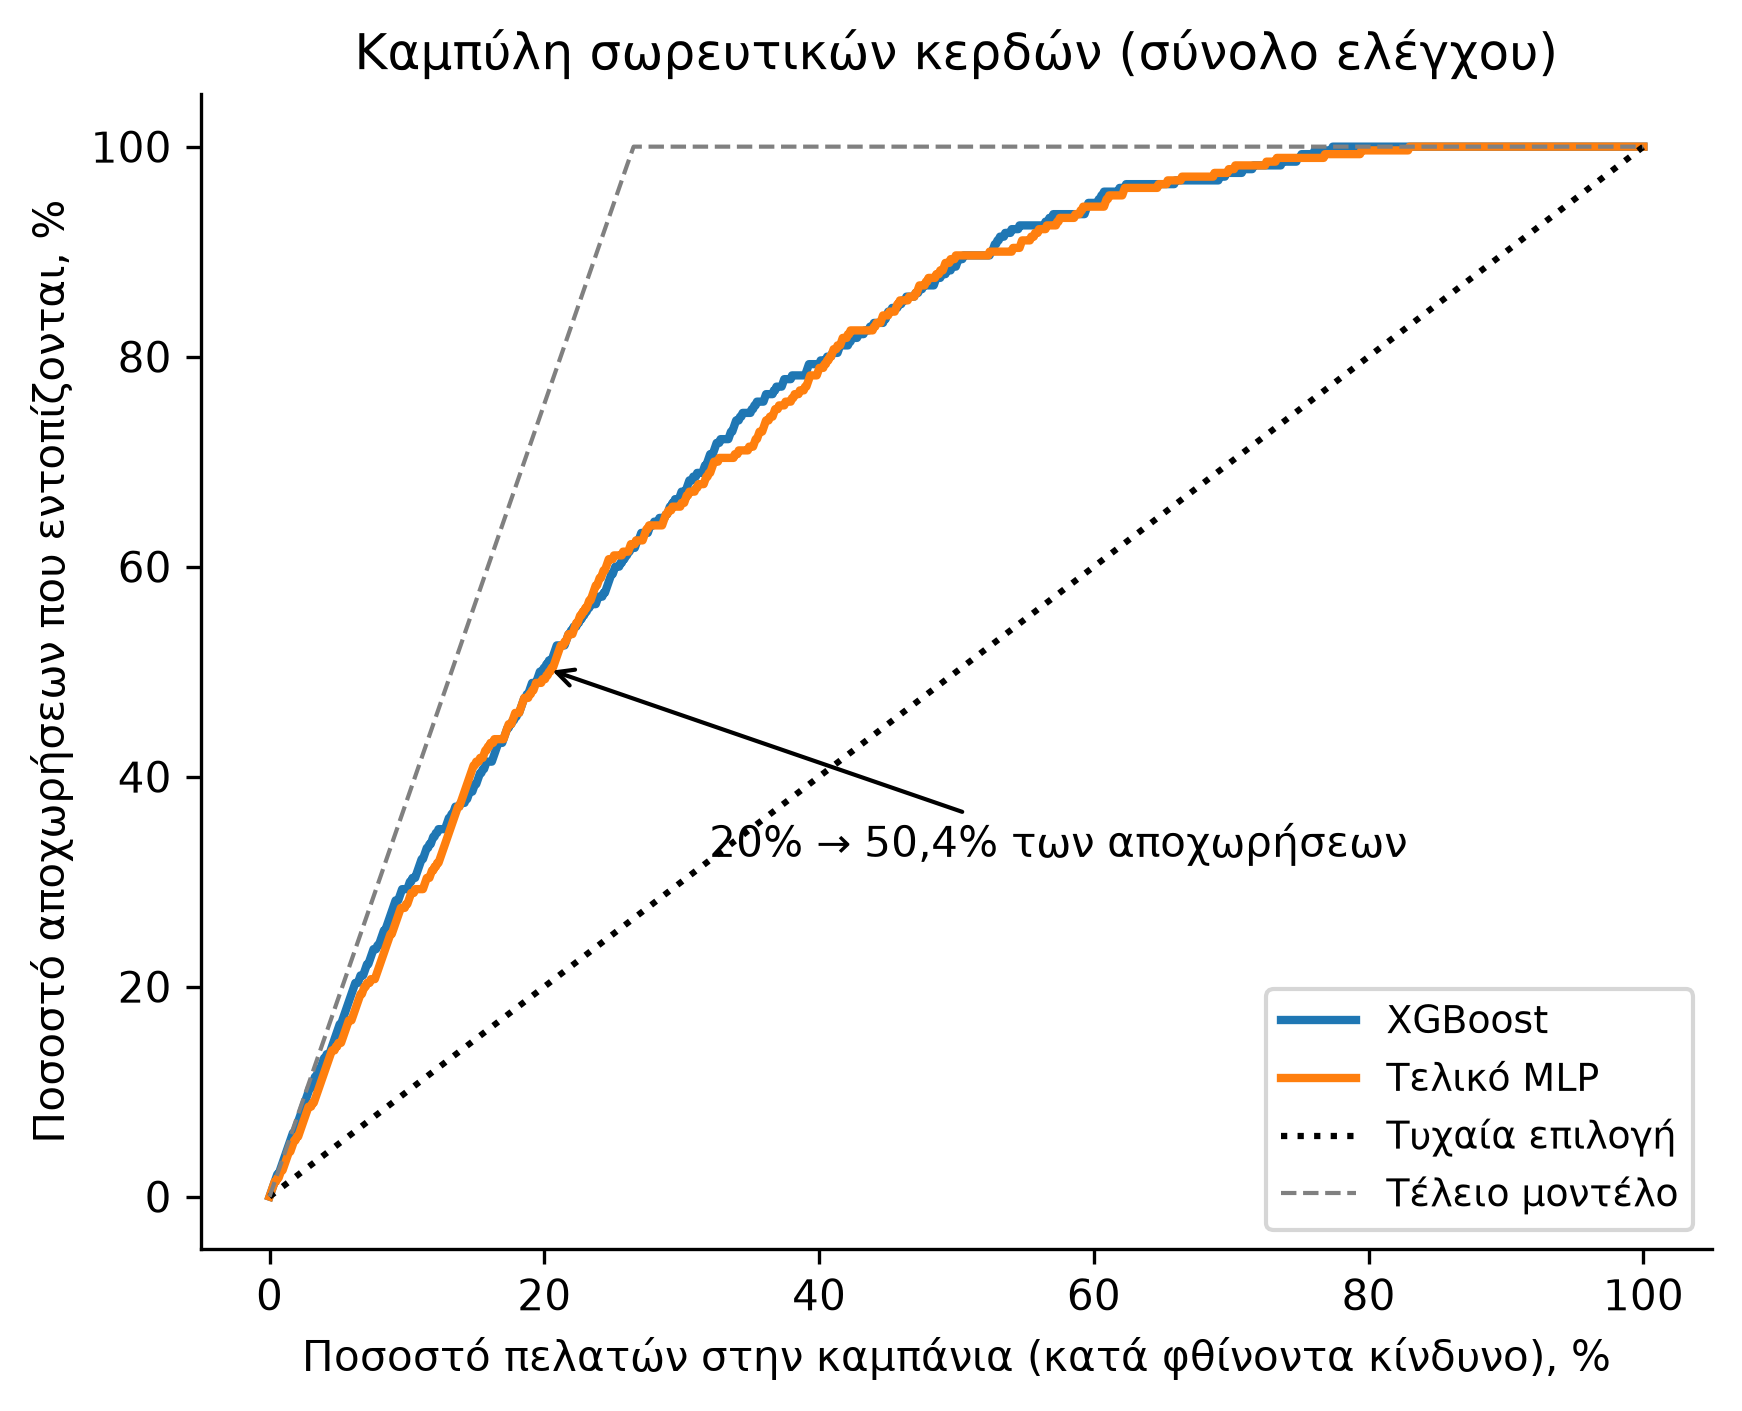

In [57]:
Image(filename=str(FIGURES / "cumulative_gains.png"), width=850)

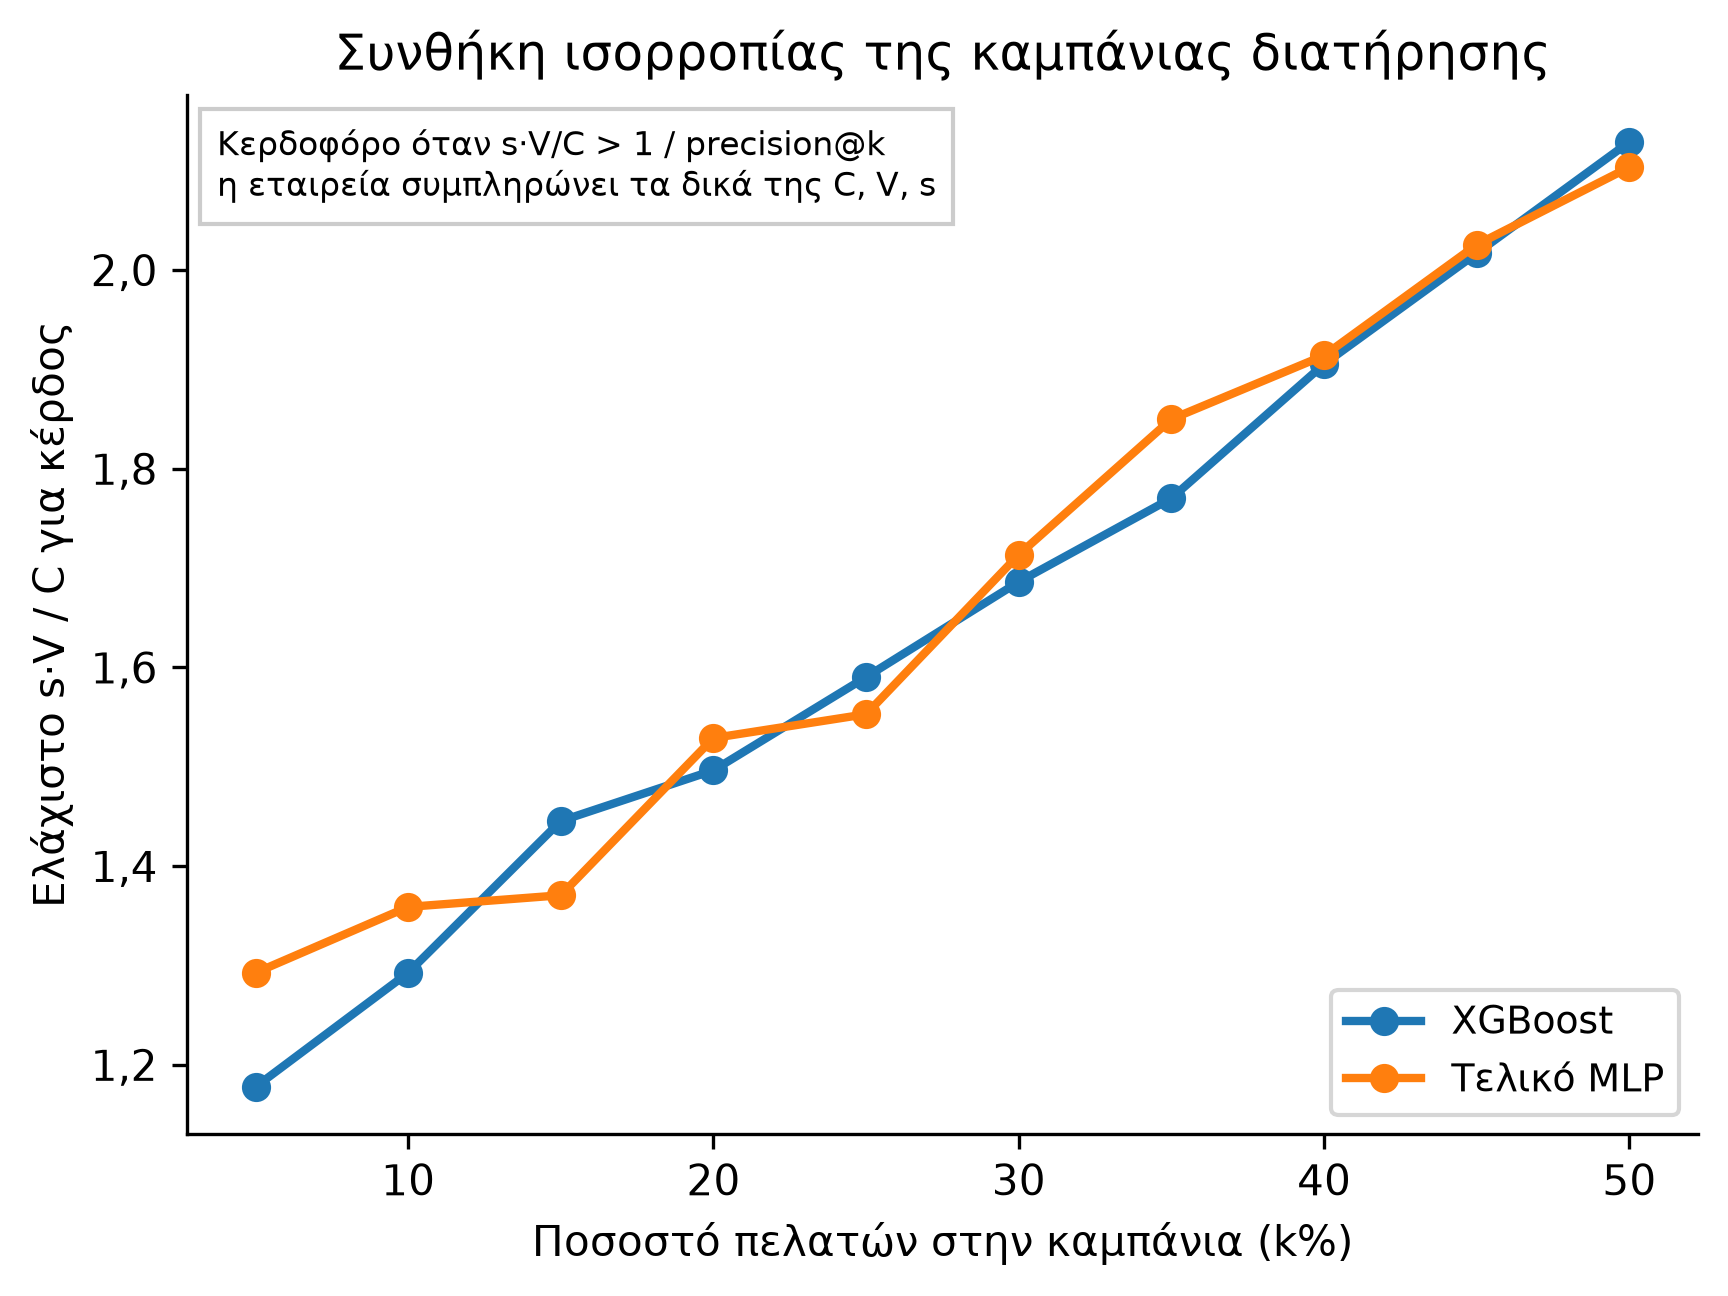

In [58]:
Image(filename=str(FIGURES / "breakeven_curve.png"), width=850)

In [59]:
pd.read_csv(TABLES / "segments.csv")

,model,segment,Τμήμα,Πλήθος,Μερίδιο πελατών,Πραγματικό ποσοστό αποχώρησης,Μέσο βαθμονομημένο ρίσκο
0,xgb,a,Μηνιαίο συμβόλαιο και διάρκεια συνδρομής ≤ 12 ...,292,0.2763,0.5240,0.5202
1,xgb,b,Οπτική ίνα χωρίς τεχνική υποστήριξη,352,0.3330,0.5028,0.4892
2,xgb,c,Πληρωμή με ηλεκτρονική επιταγή,363,0.3434,0.4187,0.4431
3,xgb,d,Ηλικιωμένοι πελάτες,169,0.1599,0.4438,0.4173
4,xgb,e,Διετές συμβόλαιο (αναφορά χαμηλού κινδύνου),250,0.2365,0.0200,0.0366
5,xgb,all,Όλοι οι πελάτες,1057,1.0000,0.2649,0.2741
6,mlp_tuned,a,Μηνιαίο συμβόλαιο και διάρκεια συνδρομής ≤ 12 ...,292,0.2763,0.5240,0.5159
7,mlp_tuned,b,Οπτική ίνα χωρίς τεχνική υποστήριξη,352,0.3330,0.5028,0.4933
8,mlp_tuned,c,Πληρωμή με ηλεκτρονική επιταγή,363,0.3434,0.4187,0.4430
9,mlp_tuned,d,Ηλικιωμένοι πελάτες,169,0.1599,0.4438,0.4251


## Εκδόσεις βιβλιοθηκών

In [60]:
import importlib.metadata as md
for pkg in ["tensorflow", "keras", "keras-tuner", "optuna", "scikit-learn", "imbalanced-learn",
            "xgboost", "lightgbm", "catboost", "shap", "lime", "pandas", "numpy"]:
    print(f"{pkg:18} {md.version(pkg)}")
print("python", sys.version.split()[0])

tensorflow         2.21.0
keras              3.15.1
keras-tuner        1.4.8
optuna             5.1.0
scikit-learn       1.9.1
imbalanced-learn   0.14.2
xgboost            3.4.1
lightgbm           4.7.0
catboost           1.2.10
shap               0.54.1
lime               0.2.0.1
pandas             3.1.1
numpy              2.5.5
python 3.12.14
